# N3 · Paso a paso: 6 condiciones × 10 puntos

Dataset A (4 km–5 min), 20 UTC. Un **punto** es un par (celda $(i,j,k)$, miembro verdad $m$): una observación y los 59 miembros del prior distintos de $m$.

1. Clasificar todos los pares según la reflectividad sin ruido de la verdad, $Z_t = h(\mathbf{x}_m)$, y su $w_t$.
2. Elegir `N_POINTS` puntos por condición con semilla fija.
3. Reproducir la observación de los experimentos de observación única.
4. Correr TEnKF $N_t$ = 1..5 y AOEI con las funciones de producción, guardando el ensamble en cada paso.
5. Verificar contra la salida de los experimentos de observación única (los puntos en celdas del barrido).
6. Figuras por punto y por condición.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import nbcommon as nb

SHOW = "es"
S_DS, S_HOUR = "A", "20"
TAG_SWEEP = f"WS_{S_DS}_sweep_{S_HOUR}00_LOC0.1_ALLMEM"     # los experimentos de observación única

# Condiciones, en el orden en que se eligen los puntos: de la reserva más chica a la más grande
CONDITIONS = ("core", "edge", "updraft", "downdraft", "weak", "clear")
Z_CLEAR = 5.0          # dBZ: aire claro, Z_t < Z_CLEAR en la celda y sus 8 vecinas
Z_CORE = 40.0          # dBZ: núcleo, Z_t > Z_CORE en la celda y sus 8 vecinas
Z_EDGE_LO, Z_EDGE_HI = 5.0, 15.0   # dBZ: borde, ver la definición en la sección 1
W_UP = 15.0            # m/s: corriente ascendente fuerte, w_t ≥ W_UP
W_DOWN = -8.0          # m/s: corriente descendente fuerte, w_t ≤ W_DOWN
W_UP_V1, W_DOWN_V1 = 1.0, -1.0     # m/s: los de la primera selección, que se reproduce en la sección 2
W_WEAK = 0.1           # m/s: viento vertical débil, |w_t| < W_WEAK
N_POINTS = 10
SEED = 20240319

nb.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
# Etiquetas propias de este notebook; el vocabulario común está en nb.VOCAB.
LABELS = {
    "es": {
        "x": "x [km]", "y": "y [km]", "z": "z [km]",
        "cut_xz": "x–z", "cut_yz": "y–z", "cut_xy": "x–y",
        "mean_z": "media del ensamble de Z [dBZ]",
        "Z": "Z [dBZ]", "qtot": "$q_g+q_r+q_s$ [g/kg]", "w": "w [m/s]",
        "members_t5": "miembros TEnKF-T5", "mean_t5": "media TEnKF-T5", "mean_t1": "media TEnKF-T1",
        "abs_err": "|error de la media|", "corr": "corr(x, Z) al entrar al paso",
        "ptime": "pseudotiempo, $i/N_t$", "n_echo_in": "$N_{Z>0}$ al entrar al paso",
        "pts_t5": "puntos (TEnKF-T5)", "mean_pts_t5": "media de los puntos (TEnKF-T5)",
        "t1_mean_pts": "TEnKF-T1, media de los puntos", "aoei_mean_pts": "AOEI, media de los puntos",
        "cell": "celda",
        "cond_core": "núcleo de tormenta", "cond_edge": "borde de tormenta",
        "cond_updraft": "corriente ascendente fuerte", "cond_downdraft": "corriente descendente fuerte",
        "cond_weak": "viento vertical débil", "cond_clear": "aire claro",
    },
    "en": {
        "x": "x [km]", "y": "y [km]", "z": "z [km]",
        "cut_xz": "x–z", "cut_yz": "y–z", "cut_xy": "x–y",
        "mean_z": "ensemble mean of Z [dBZ]",
        "Z": "Z [dBZ]", "qtot": "$q_g+q_r+q_s$ [g/kg]", "w": "w [m/s]",
        "members_t5": "TEnKF-T5 members", "mean_t5": "TEnKF-T5 mean", "mean_t1": "TEnKF-T1 mean",
        "abs_err": "|error of the mean|", "corr": "corr(x, Z) entering the step",
        "ptime": "pseudo-time, $i/N_t$", "n_echo_in": "$N_{Z>0}$ entering the step",
        "pts_t5": "points (TEnKF-T5)", "mean_pts_t5": "mean of the points (TEnKF-T5)",
        "t1_mean_pts": "TEnKF-T1, mean of the points", "aoei_mean_pts": "AOEI, mean of the points",
        "cell": "cell",
        "cond_core": "storm core", "cond_edge": "storm edge",
        "cond_updraft": "strong updraft", "cond_downdraft": "strong downdraft",
        "cond_weak": "weak vertical wind", "cond_clear": "clear air",
    },
}
assert set(LABELS["es"]) == set(LABELS["en"])

## 1 · Clasificación de todos los pares

Para cada celda y cada miembro verdad $m$:

- **Elegible** si pasa el control de calidad: al menos uno de sus 59 miembros del prior tiene $Z > 0$ dBZ en la celda.
- **Celdas no finitas:** las celdas del subset con algún valor no finito en alguno de los 60 miembros (56 en A a las 20 UTC) se excluyen, y es lo correcto: ahí el operador de reflectividad devuelve 0 dBZ sin avisar y el prior no está definido, así que ni la clasificación ni la asimilación tienen sentido.
- **Aire claro:** $Z_t <$ 5 dBZ en la celda y en sus 8 vecinas horizontales (mismo nivel $k$).
- **Núcleo de tormenta:** $Z_t >$ 40 dBZ en la celda y en sus 8 vecinas.
- **Borde de tormenta:** para alguna dirección $d \in \{+x, -x, +y, -y\}$, al menos una de las dos celdas siguientes en $d$ tiene $Z_t <$ 5 dBZ y las dos siguientes en $-d$ tienen $Z_t >$ 15 dBZ. Sin condición sobre la celda.
- **Corriente ascendente fuerte:** $w_t \ge$ 15 m/s; **descendente fuerte:** $w_t \le$ −8 m/s; **viento vertical débil:** $|w_t| <$ 0,1 m/s. Sin condición sobre $Z$ en ninguna de las tres. Los dos primeros umbrales se fijaron con los conteos de candidatos de más abajo; la primera selección usaba ±1 m/s (sección 2).

La clasificación se hace en todos los pares, porque las pruebas de vecinas miran todas las celdas; los puntos de núcleo, borde, viento débil y aire claro se eligen solo entre las celdas con salida de los experimentos de observación única, y los de corriente vertical fuerte entre todas (ver más abajo).

Las celdas cuya plantilla sale de la grilla (a 1 celda del borde para aire claro y núcleo, a 2 para el borde) no son elegibles para las tres condiciones de reflectividad.

In [3]:
t0 = time.time()
P_SUB = nb.subset_path(S_HOUR, S_DS)
nb.assert_dataset(P_SUB, S_DS)
with np.load(P_SUB) as f:
    ENS = f["state_ensemble"]                         # (nx, ny, nz, 60, 8)
    POS = f["pos_km"]
NX, NY, NZ, NM, _ = ENS.shape
DBZ_MIN = nb.dbz_min_of(TAG_SWEEP)

# Z de los 60 miembros en todo el dominio, por bloques de columnas (el operador trabaja en float64)
Z = np.empty((NX, NY, NZ, NM), np.float32)
for i0 in range(0, NX, 32):
    Z[i0:i0 + 32] = nb.hx(ENS[i0:i0 + 32], min_dbz=DBZ_MIN)
W = ENS[..., nb.VI["w"]]
FINITE = np.isfinite(ENS).all(axis=(3, 4))            # (nx, ny, nz)
print(f"subset {nb.DS_LABEL[S_DS]}, {S_HOUR} UTC: {ENS.shape}; {time.time() - t0:.0f} s")
print(f"celdas con algún valor no finito: {int((~FINITE).sum())} de {FINITE.size:,}")

subset 4 km–5 min, 20 UTC: (307, 451, 11, 60, 8); 16 s
celdas con algún valor no finito: 56 de 1,523,027


In [4]:
# Control de calidad por par: miembros del prior con eco = los de los 60, menos la verdad
echo = Z > DBZ_MIN
N_ECHO = (echo.sum(axis=3, dtype=np.int16)[..., None] - echo).astype(np.int16)   # N_Z>0 del prior de cada par
ELIG = (N_ECHO >= 1) & FINITE[..., None]
MEAN_Z = ((Z.sum(axis=3, dtype=np.float64)[..., None] - Z) / (NM - 1)).astype(np.float32)   # media de Z del prior
del echo

ii = np.arange(NX)[:, None, None, None]
jj = np.arange(NY)[None, :, None, None]
IN1 = (ii >= 1) & (ii <= NX - 2) & (jj >= 1) & (jj <= NY - 2)          # la plantilla 3×3 cabe
IN2 = (ii >= 2) & (ii <= NX - 3) & (jj >= 2) & (jj <= NY - 3)          # la cruz de ±2 cabe


def shifted(a, di, dj):
    """a[i + di, j + dj]; NaN donde sale de la grilla."""
    out = np.full(a.shape, np.nan, np.float32)
    src = a[max(di, 0):NX + min(di, 0), max(dj, 0):NY + min(dj, 0)]
    out[max(-di, 0):NX + min(-di, 0), max(-dj, 0):NY + min(-dj, 0)] = src
    return out


# Una vecina a la vez: diecisiete copias de Z desplazadas no caben en memoria juntas.
COND = {"clear": ELIG & IN1, "core": ELIG & IN1}
for di in (-1, 0, 1):
    for dj in (-1, 0, 1):
        zn = shifted(Z, di, dj)
        COND["clear"] &= zn < Z_CLEAR
        COND["core"] &= zn > Z_CORE
edge = np.zeros(Z.shape, bool)
for ux, uy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
    ahead = (shifted(Z, ux, uy) < Z_EDGE_LO) | (shifted(Z, 2 * ux, 2 * uy) < Z_EDGE_LO)
    behind = (shifted(Z, -ux, -uy) > Z_EDGE_HI) & (shifted(Z, -2 * ux, -2 * uy) > Z_EDGE_HI)
    edge |= ahead & behind
COND["edge"] = ELIG & IN2 & edge
COND["updraft"] = ELIG & (W >= W_UP)
COND["downdraft"] = ELIG & (W <= W_DOWN)
COND["weak"] = ELIG & (np.abs(W) < W_WEAK)
del zn, edge, ahead, behind
print(f"pares elegibles: {int(ELIG.sum()):,} de {ELIG.size:,}; "
      f"excluidos por valores no finitos: {int((~FINITE).sum()) * NM:,} pares ({int((~FINITE).sum())} celdas)")

pares elegibles: 55,214,640 de 91,381,620; excluidos por valores no finitos: 3,360 pares (56 celdas)


In [5]:
# Pares por condición y su solapamiento (pares que cumplen las dos)
counts = pd.Series({c: int(COND[c].sum()) for c in CONDITIONS}, name="pares")
OV = pd.DataFrame([[int((COND[a] & COND[b]).sum()) for b in CONDITIONS] for a in CONDITIONS],
                  index=CONDITIONS, columns=CONDITIONS)
print(counts.to_string(), "\n")
print("solapamiento (pares en las dos condiciones):")
print(OV.to_string())

core           114268
edge          3162365
updraft          4725
downdraft          96
weak         28353503
clear        45325797 

solapamiento (pares en las dos condiciones):
             core     edge  updraft  downdraft      weak     clear
core       114268     1654     1893         53      7571         0
edge         1654  3162365     1120         15    782272         0
updraft      1893     1120     4725          0         0         0
downdraft      53       15        0         96         0         0
weak         7571   782272        0          0  28353503  25336983
clear           0        0        0          0  25336983  45325797


### El universo de selección: celdas con salida de observación única

Los experimentos de observación única barren una celda de cada 10 en $x$ y en $y$ (`stride` 10, todos los niveles). Solo en esas celdas hay una salida contra la cual verificar la observación (paso 3) y el resultado (paso 5), así que los puntos de núcleo, borde, viento débil y aire claro se eligen solo entre ellas. Las corrientes verticales fuertes son demasiado raras para eso (la tabla de candidatos, abajo) y se eligen entre todas las celdas: en las que no son del barrido, la observación se reproduce con el ruido del runner (paso 3), pero el resultado no tiene contra qué verificarse (paso 5). Las condiciones son las mismas: las pruebas de vecinas siguen mirando todas las celdas.

In [6]:
cfg = nb.run_config(TAG_SWEEP)
STRIDE = int(cfg["sweep"]["stride"])
SWEEP_CELL = (ii % STRIDE == 0) & (jj % STRIDE == 0)
POOL = ELIG & SWEEP_CELL                               # pares elegibles en celdas del barrido
print(f"stride {STRIDE}: {int(POOL.sum()):,} pares elegibles en {int(POOL.any(axis=3).sum()):,} celdas del barrido")
print(pd.DataFrame({"todos": counts,
                    "en el barrido": {c: int((COND[c] & SWEEP_CELL).sum()) for c in CONDITIONS},
                    "celdas distintas en el barrido": {c: int((COND[c] & SWEEP_CELL).any(axis=3).sum())
                                                       for c in CONDITIONS}}).to_string())
print("\nsolapamiento en celdas del barrido (pares en las dos condiciones):")
print(pd.DataFrame([[int((COND[a] & COND[b] & SWEEP_CELL).sum()) for b in CONDITIONS] for a in CONDITIONS],
                   index=CONDITIONS, columns=CONDITIONS).to_string())

stride 10: 565,366 pares elegibles en 9,454 celdas del barrido
              todos  en el barrido  celdas distintas en el barrido
core         114268           1184                             786
edge        3162365          30862                            6755
updraft        4725             49                              49
downdraft        96              1                               1
weak       28353503         290473                            9428
clear      45325797         440968                            8754

solapamiento en celdas del barrido (pares en las dos condiciones):
           core   edge  updraft  downdraft    weak   clear
core       1184     14       16          1      80       0
edge         14  30862       13          0    7593       0
updraft      16     13       49          0       0       0
downdraft     1      0        0          1       0       0
weak         80   7593        0          0  290473  245957
clear         0      0        0          0  24

In [7]:
# Los candidatos de las corrientes verticales fuertes a las 20 UTC, en todas las celdas: pares, celdas, miembros
# verdad, niveles y regiones (grupos de columnas candidatas que se tocan, con diagonales, juntando los 60
# miembros). Con estos conteos (y los de las cuatro horas) se eligieron W_UP = 15 y W_DOWN = −8 m/s.
from scipy import ndimage

EIGHT = np.ones((3, 3), int)


def candidates(mask):
    cols = mask.any(axis=(2, 3))
    return {"pares": int(mask.sum()), "celdas": int(mask.any(axis=3).sum()),
            "miembros verdad": int(mask.any(axis=(0, 1, 2)).sum()), "niveles": int(mask.any(axis=(0, 1, 3)).sum()),
            "columnas": int(cols.sum()), "regiones": ndimage.label(cols, structure=EIGHT)[1]}


print("candidatos a las 20 UTC, pares elegibles en todas las celdas:")
print(pd.DataFrame({f"w_t ≥ {W_UP:g}": candidates(ELIG & (W >= W_UP)),
                    **{f"w_t ≤ {t:g}": candidates(ELIG & (W <= t)) for t in (-8.0, -9.0, -10.0)}}).T.to_string())

candidatos a las 20 UTC, pares elegibles en todas las celdas:
           pares  celdas  miembros verdad  niveles  columnas  regiones
w_t ≥ 15    4725    4510               60        7      1825       500
w_t ≤ -8      96      92               24        8        64        36
w_t ≤ -9      39      37               14        8        26        15
w_t ≤ -10     12      12                5        4        10         7


## 2 · Selección

En dos etapas.

**Primera selección: seis condiciones, celdas del barrido.** `N_POINTS` puntos por condición, con semilla fija, en el orden de `CONDITIONS`: de la reserva más chica a la más grande (núcleo, borde, ascendente, descendente, débil, aire claro). En cada condición, los pares candidatos (la condición, en celdas del barrido) se barajan y se toman en ese orden saltando las celdas ya usadas. Así las celdas son distintas dentro de una condición, y una celda elegida para una condición sale de la reserva de las siguientes. Los miembros verdad pueden repetirse. Las corrientes verticales eran entonces $w_t \ge$ 1 y $w_t \le$ −1 m/s. Se rehace entera, porque la semilla recorre las seis condiciones, y se exige que dé la guardada en `data/derived/N3s/old_w1/selection.csv`. De ella quedan núcleo, borde, viento débil y aire claro.

**Corrientes verticales fuertes: todas las celdas.** Los puntos de $w_t \ge$ `W_UP` y $w_t \le$ `W_DOWN` reemplazan a los de la primera selección, que se guardan con sus corridas en `data/derived/N3s/old_w1/` y con sus figuras en `figures/<idioma>/N3s/old_w1/`. Candidatos: los pares elegibles de la condición en todas las celdas, salvo las celdas de las otras cuatro condiciones. Las regiones de cada condición son los grupos de columnas candidatas que se tocan (con diagonales, juntando los 60 miembros), como en la tabla de candidatos. Los candidatos se barajan con semilla fija y se toman en ese orden con a lo sumo un punto por región y, primero, con miembros verdad distintos; si así no se llega a `N_POINTS`, se recorre la misma permutación sin la condición de los miembros. Una celda elegida para la ascendente sale de la reserva de la descendente.

La selección final se guarda en `data/derived/N3s/selection.csv` (con la región de cada punto de corriente vertical; 0 en las otras condiciones); si ya existe, se recalcula y se exige que sea la misma.

In [8]:
OUT_S = nb.DERIVED / "N3s"
SEL_FILE = OUT_S / "selection.csv"
OLD = OUT_S / "old_w1"                # la primera selección, con las corridas de sus puntos de corriente vertical
W_CONDS = ("updraft", "downdraft")
SEL_COLS = ["condition", "i", "j", "k", "m"]


def sel_row(c, i, j, k, m, **extra):
    return dict(condition=c, i=i, j=j, k=k, m=m, Z_t=float(Z[i, j, k, m]), w_t=float(W[i, j, k, m]),
                n_echo=int(N_ECHO[i, j, k, m]), prior_mean_Z=float(MEAN_Z[i, j, k, m]), seed=SEED, **extra)


# Primera selección: las seis condiciones en celdas del barrido, con |w_t| >= 1 m/s para las corrientes verticales.
COND_V1 = COND | {"updraft": ELIG & (W >= W_UP_V1), "downdraft": ELIG & (W <= W_DOWN_V1)}
rng = np.random.default_rng(SEED)
used, rows = set(), []
for c in CONDITIONS:
    cand = np.argwhere(COND_V1[c] & SWEEP_CELL)          # (pares, 4): i, j, k, m
    got = []
    for q in rng.permutation(len(cand)):
        i, j, k, m = (int(v) for v in cand[q])
        if (i, j, k) in used:
            continue
        used.add((i, j, k))
        got.append((i, j, k, m))
        if len(got) == N_POINTS:
            break
    assert len(got) == N_POINTS, f"{c}: solo {len(got)} puntos"
    rows += [sel_row(c, i, j, k, m) for i, j, k, m in got]
SEL_V1 = pd.DataFrame(rows)
assert all(COND_V1[c][i, j, k, m] and SWEEP_CELL[i, j, 0, 0]
           for c, i, j, k, m in SEL_V1[SEL_COLS].itertuples(index=False))
assert pd.read_csv(OLD / "selection.csv")[SEL_COLS].equals(SEL_V1[SEL_COLS]), \
    "la primera selección no es la guardada en old_w1/selection.csv"
del COND_V1
print(f"primera selección: igual a {(OLD / 'selection.csv').relative_to(nb.REPO)}")

primera selección: igual a data/derived/N3s/old_w1/selection.csv


In [9]:
# Corrientes verticales fuertes: candidatos en todas las celdas, salvo las de las otras cuatro condiciones;
# a lo sumo un punto por región y, primero, miembros verdad distintos.
SEL4 = SEL_V1[~SEL_V1.condition.isin(W_CONDS)]
USED = np.zeros((NX, NY, NZ), bool)
USED[SEL4.i.to_numpy(), SEL4.j.to_numpy(), SEL4.k.to_numpy()] = True
rng_w = np.random.default_rng(SEED)
REGIONS, rows = {}, []
for c in W_CONDS:
    pool = COND[c] & ~USED[..., None]
    cand = np.argwhere(pool)                             # (pares, 4): i, j, k, m
    lab, n_reg = ndimage.label(pool.any(axis=(2, 3)), structure=EIGHT)
    REGIONS[c] = lab
    perm = rng_w.permutation(len(cand))
    got, regs, mems = [], set(), set()
    for distinct_m in (True, False):                     # sin la condición de los miembros solo si hace falta
        for q in perm:
            i, j, k, m = (int(v) for v in cand[q])
            g = int(lab[i, j])
            if g in regs or USED[i, j, k] or (distinct_m and m in mems):
                continue
            regs.add(g)
            mems.add(m)
            USED[i, j, k] = True
            got.append((i, j, k, m))
            if len(got) == N_POINTS:
                break
        if len(got) == N_POINTS:
            break
    assert len(got) == N_POINTS, f"{c}: solo {len(got)} puntos"
    print(f"{c}: {len(cand):,} pares candidatos en {n_reg} regiones; "
          f"{len(mems)} miembros verdad distintos en {N_POINTS} puntos")
    rows += [sel_row(c, i, j, k, m, region=int(lab[i, j])) for i, j, k, m in got]

SEL = pd.concat([SEL4.assign(region=0), pd.DataFrame(rows)], ignore_index=True)
SEL = SEL.sort_values("condition", key=lambda s: s.map({c: q for q, c in enumerate(CONDITIONS)}), kind="stable",
                      ignore_index=True)
assert SEL[["i", "j", "k"]].drop_duplicates().shape[0] == len(SEL), "una celda repetida"
assert SEL4.reset_index(drop=True).equals(SEL[~SEL.condition.isin(W_CONDS)].drop(columns="region")
                                          .reset_index(drop=True)), "cambiaron las otras cuatro condiciones"
if SEL_FILE.exists():
    old = pd.read_csv(SEL_FILE)
    assert old[SEL_COLS + ["region"]].equals(SEL[SEL_COLS + ["region"]]), f"la selección cambió respecto de {SEL_FILE.name}"
else:
    SEL.to_csv(SEL_FILE, index=False)
    print(f"escrito {SEL_FILE.relative_to(nb.REPO)}")

W_PTS = SEL[SEL.condition.isin(W_CONDS)].copy()
W_PTS["z [km]"] = POS[W_PTS.i.to_numpy(), W_PTS.j.to_numpy(), W_PTS.k.to_numpy(), 2]
W_PTS["columnas de la región"] = [int((REGIONS[c] == g).sum()) for c, g in zip(W_PTS.condition, W_PTS.region)]
W_PTS["barrido"] = (W_PTS.i % STRIDE == 0) & (W_PTS.j % STRIDE == 0)
print("\npuntos de corriente vertical fuerte:")
print(W_PTS.rename(columns={"n_echo": "N_Z>0 prior", "region": "región"})[
    ["condition", "i", "j", "k", "z [km]", "m", "w_t", "Z_t", "N_Z>0 prior", "región", "columnas de la región",
     "barrido"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print()
print(SEL.groupby("condition", sort=False).agg(puntos=("m", "size"), miembros_verdad=("m", "nunique"),
                                               niveles=("k", lambda v: sorted(set(v)))).to_string())

updraft: 4,725 pares candidatos en 500 regiones; 10 miembros verdad distintos en 10 puntos
downdraft: 96 pares candidatos en 36 regiones; 10 miembros verdad distintos en 10 puntos

puntos de corriente vertical fuerte:
condition   i   j  k  z [km]  m    w_t   Z_t  N_Z>0 prior  región  columnas de la región  barrido
  updraft 134 218  7    6.00 59  16.07 51.55            4     159                      4    False
  updraft 155 346 10   12.00 25  15.22 50.39           16     215                      9    False
  updraft 122 407 10   12.00 51  20.50 49.72            9     116                      7    False
  updraft 137 365  8    8.00 38  23.87 55.70           12     162                     17    False
  updraft 159 301  8    8.00 44  15.22 50.08           19     177                     90    False
  updraft  55 102  8    8.00 48  20.83 52.74            1      37                      7    False
  updraft 131 368  9   10.00 52  24.18 53.30            9     154                      5    Fals

## 3 · La observación

El runner genera el ruido una vez por miembro verdad, en todo el dominio: `np.random.default_rng(42 + tm).normal(0, sqrt(R), (nx, ny, nz))` en float32, y la observación es $y_o = \max(h(\mathbf{x}_m) + \epsilon,\ $`dbz_min`$)$ (`run_experiment._setup`). Se reproduce acá para los 60 miembros verdad y se compara con `yo` en todas las celdas del barrido: exacto partiendo de `yo_clean` del archivo (el $h(\mathbf{x}_m)$ del Fortran), y con el operador de NumPy, hasta su redondeo. En los puntos fuera del barrido (corrientes verticales fuertes) no hay fila del barrido: la observación se calcula con el mismo ruido, y la sección 5 comprueba que es la que usó la corrida.

In [10]:
R = nb.obs_error_var(TAG_SWEEP)
SIGMA = float(np.sqrt(R))
assert cfg["obs"]["add_noise"] and cfg["qc"]["clamp_obs"]


def noise_of(tm):
    """El ruido del runner para el miembro verdad tm, en todo el dominio."""
    return np.random.default_rng(42 + tm).normal(0.0, SIGMA, (NX, NY, NZ)).astype(np.float32)


rows = []
for tm in range(NM):
    with np.load(nb.sweep_files(TAG_SWEEP, [tm])[0]) as z:
        one = (z["method"] == "TEnKF") & (z["ntemp"] == 1)
        i, j, k = (z[c][one].astype(np.intp) for c in ("i", "j", "k"))
        yo, yc = z["yo"][one], z["yo_clean"][one]
    eps = noise_of(tm)[i, j, k]
    yo_exact = np.maximum(yc + eps, np.float32(DBZ_MIN))           # float32, como el runner
    yo_np = np.maximum(Z[i, j, k, tm] + eps, np.float32(DBZ_MIN))
    rows.append(dict(tm=tm, n=len(i), exact=bool(np.array_equal(yo_exact, yo)),
                     max_np=float(np.abs(yo_np - yo).max())))
OBS_CHECK = pd.DataFrame(rows)
assert OBS_CHECK.exact.all(), "el ruido reproducido no da la yo del barrido"
print(f"{OBS_CHECK.n.sum():,} observaciones de {NM} miembros verdad: y_o reproducida exacta desde yo_clean; "
      f"con el operador de NumPy, máx |Δ| = {OBS_CHECK.max_np.max():.1e} dBZ")

565,426 observaciones de 60 miembros verdad: y_o reproducida exacta desde yo_clean; con el operador de NumPy, máx |Δ| = 0.0e+00 dBZ


In [11]:
# La observación de cada punto elegido; en los puntos de celdas del barrido, también su fila del barrido.
SWEEP_ROWS = {}
yo_pt = []
for r in SEL.itertuples(index=False):
    yo = np.maximum(np.float32(r.Z_t) + noise_of(r.m)[r.i, r.j, r.k], np.float32(DBZ_MIN))
    if r.i % STRIDE == 0 and r.j % STRIDE == 0:
        with np.load(nb.sweep_files(TAG_SWEEP, [r.m])[0]) as z:
            at = np.flatnonzero((z["i"] == r.i) & (z["j"] == r.j) & (z["k"] == r.k))
            SWEEP_ROWS[(r.i, r.j, r.k, r.m)] = {key: z[key][at] for key in z.files
                                                if z[key].ndim == 1 and len(z[key]) == len(z["i"])}
        sw = SWEEP_ROWS[(r.i, r.j, r.k, r.m)]
        assert len(at) == 11, f"{r}: {len(at)} filas en el barrido"
        assert yo == sw["yo"][0] and np.float32(r.Z_t) == sw["yo_clean"][0], f"{r}: y_o no es la del barrido"
    yo_pt.append(float(yo))
SEL["y_o"] = yo_pt
SEL["d"] = SEL.y_o - SEL.prior_mean_Z
print(f"y_o de los {len(SWEEP_ROWS)} puntos en celdas del barrido: igual a la del barrido; "
      f"los otros {len(SEL) - len(SWEEP_ROWS)} se comparan con su corrida en la sección 5.\n")
TAB_PTS = SEL.rename(columns={"n_echo": "N_Z>0", "prior_mean_Z": "media prior Z"})[
    ["condition", "i", "j", "k", "m", "Z_t", "y_o", "media prior Z", "d", "N_Z>0", "w_t"]]
print(TAB_PTS.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

y_o de los 40 puntos en celdas del barrido: igual a la del barrido; los otros 20 se comparan con su corrida en la sección 5.

condition   i   j  k  m   Z_t   y_o  media prior Z     d  N_Z>0    w_t
     core 180 150  2 10 47.72 43.19          11.74 31.45     25  -0.64
     core 210 180  6 48 51.33 51.30          45.78  5.52     59   0.17
     core 150 350  3  8 48.11 43.91           5.05 38.86     13  -3.02
     core 150 370  7 40 53.82 50.76           5.12 45.63      9   1.94
     core 140 380  8  6 50.48 53.37           2.17 51.20      5  -1.26
     core 170 420  6 25 56.95 61.43           3.46 57.97      7  -0.19
     core 120 370  8 47 45.75 44.93           2.23 42.70      7   2.39
     core 160 310  7 23 54.48 53.59           5.68 47.91     13  -0.74
     core 160 420  0 25 40.85 40.81           0.30 40.51      1   0.20
     core 230  40  3 39 48.53 46.33           6.20 40.13     12  -1.49
     edge 190 160  4  1 11.84 11.40          14.33 -2.94     28  -0.28
     edge 230 300  6 3

## 4 · Las corridas

TEnKF con $N_t$ = 1..5 ($\alpha_s = 1$) y AOEI, cada uno con la censura de hidrometeoros en cada paso (`per_step`, la de producción) y solo al final (`final`).

Se llama a la función de producción del modo `point` del runner, `run_experiment._process_point(..., capture_steps=True)`. Usa el mismo subdominio, la misma actualización (`da.core.tenkf_update` / `aoei_update`, en Fortran), el mismo registro paso a paso (`StepRecorder`) y la misma fila de métricas que el barrido. Sus entradas se arman como en `run_experiment._setup`, sobre una ventana de ±`WIN` celdas alrededor de la celda (el subdominio de la localización de 0,1 km es de ±1 celda):

- los 59 miembros distintos de $m$;
- $H(\mathbf{x})$ con `_calc_hx_domain`;
- $y_o$ con el ruido del runner.

Biblioteca Fortran: `src/fortran/cletkf_wloc.cpython-314-darwin.so`, compilada para macOS desde las mismas fuentes que la de Linux (`cpython-38-x86_64-linux-gnu`). Cada punto se guarda en `data/derived/N3s/steps/<condición>_<i>_<j>_<k>_tm<m>.npz`, con las claves de las dos censuras prefijadas `per_step/` y `final/`.

In [12]:
import copy
import runners.run_experiment as rx
from da import core

core.set_verbose(0)
RUN_STEPS = False          # True: rehace las corridas aunque existan
STEPS_DIR = OUT_S / "steps"
S_NTEMP = (1, 2, 3, 4, 5)
CLAMP_MODES = ("per_step", "final")
WIN = 5                    # celdas de la ventana a cada lado; el subdominio usa ±1

RCFG = copy.deepcopy(cfg)
RCFG["sweep"]["ntemp"] = list(S_NTEMP)
COMBOS = rx._build_combos(RCFG["sweep"])
VAR_IDX = RCFG["state"]["var_idx"]
CUTOFF = float(RCFG.get("cutoff_factor", 4.0))
assert [(c[0], c[1]) for c in COMBOS] == [("TEnKF", n) for n in S_NTEMP] + [("AOEI", 1)]
assert VAR_IDX == nb.VI and rx.clamp_mode_of(cfg) == "per_step"
print("cletkf_wloc:", __import__("cletkf_wloc").__file__)


def point_name(r):
    return f"{r.condition}_{r.i}_{r.j}_{r.k}_tm{r.m:02d}"


def setup_window(i, j, m):
    """Las variables globales de run_experiment, como las deja _setup, en una ventana."""
    si = slice(max(i - WIN, 0), min(i + WIN + 1, NX))
    sj = slice(max(j - WIN, 0), min(j + WIN + 1, NY))
    sub = ENS[si, sj]
    others = [n for n in range(NM) if n != m]
    truth = sub[:, :, :, m, :].copy()
    xf = np.asfortranarray(sub[:, :, :, others, :])
    truth_hx = rx._calc_hx_domain(truth, VAR_IDX, dbz_min=DBZ_MIN)
    ens_hx = rx._calc_hx_domain(xf, VAR_IDX, dbz_min=DBZ_MIN)
    yo_field = (truth_hx + noise_of(m)[si, sj]).astype(np.float32)
    np.maximum(yo_field, DBZ_MIN, out=yo_field)                 # clamp_obs
    np.maximum(ens_hx, DBZ_MIN, out=ens_hx)
    rx._XF, rx._ENS_HX, rx._TRUTH, rx._TRUTH_HX = xf, ens_hx, truth, truth_hx
    rx._POS_KM, rx._YO_FIELD = POS[si, sj].astype(np.float32), yo_field
    return i - si.start, j - sj.start


def run_point(r):
    ic, jc = setup_window(r.i, r.j, r.m)
    out = dict(xf_point=np.asarray(rx._XF[ic, jc, r.k], np.float32),
               truth_point_state=np.asarray(rx._TRUTH[ic, jc, r.k], np.float32),
               hxf_point=np.asarray(rx._ENS_HX[ic, jc, r.k], np.float32),
               yo=np.float32(rx._YO_FIELD[ic, jc, r.k]), yo_clean=np.float32(rx._TRUTH_HX[ic, jc, r.k]))
    for mode in CLAMP_MODES:
        row, _, blocks = rx._process_point(ic, jc, r.k, COMBOS, VAR_IDX, R, CUTOFF, return_fields=False,
                                           dbz_min=DBZ_MIN, capture_steps=True, clamp_mode=mode)
        out.update({f"{mode}/{key}": v for key, v in {**row, **blocks}.items()})
    return out


STEPS_DIR.mkdir(parents=True, exist_ok=True)
t0, n_run = time.time(), 0
for r in SEL.itertuples(index=False):
    f = STEPS_DIR / f"{point_name(r)}.npz"
    if RUN_STEPS or not f.exists():
        np.savez_compressed(f, **run_point(r))
        n_run += 1
print(f"{n_run} puntos corridos en {time.time() - t0:.0f} s; {len(SEL)} en {STEPS_DIR.relative_to(nb.REPO)}")
STEPS = {point_name(r): dict(np.load(STEPS_DIR / f"{point_name(r)}.npz")) for r in SEL.itertuples(index=False)}

cletkf_wloc: /Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/src/fortran/cletkf_wloc.cpython-314-darwin.so
0 puntos corridos en 0 s; 60 en data/derived/N3s/steps


## 5 · Verificación

Con la censura en cada paso, la media final del ensamble en la celda ($Z$ y las 8 variables de estado) tiene que reproducir la salida de los experimentos de observación única para la misma (celda, verdad, esquema), que se corrió en Linux con la biblioteca de Linux. Se compara:

- la fila de métricas (`mean_a_point_*`, `hxa_mean_obs`, y del prior `mean_f_point_*`, `hxf_mean_obs`) contra la del barrido;
- la media del último ensamble registrado contra la misma fila.

Diferencias en ULP de float32 de la escala de cada variable en la celda (el máximo de |valor| entre los miembros del prior y la verdad). Con la censura solo al final, los esquemas de un paso (T1 y AOEI) tienen que dar exactamente lo mismo que con la censura en cada paso.

Solo los puntos en celdas del barrido tienen una salida contra la cual compararse: los de las cuatro primeras condiciones y los de corriente vertical fuerte que caigan en una (se informa cuántos). En todos los puntos se comprueba que la observación de la corrida es la de la sección 3 y que los esquemas de un paso dan lo mismo con las dos censuras.

In [13]:
EPS32 = float(np.finfo(np.float32).eps)
ULP_TOL = 16
QV = list(nb.VARS)
rows = []
for r in SEL.itertuples(index=False):
    P_ = STEPS[point_name(r)]
    # en todos los puntos: la observación de la corrida es la de la sección 3
    assert P_["yo"] == np.float32(r.y_o) and P_["yo_clean"] == np.float32(r.Z_t), f"{point_name(r)}: y_o"
    sw = SWEEP_ROWS.get((r.i, r.j, r.k, r.m))           # None fuera del barrido
    if sw is not None:
        swk = {(str(a), int(b)): q for q, (a, b) in enumerate(zip(sw["method"], sw["ntemp"]))}
        scale = np.abs(np.vstack([P_["xf_point"], P_["truth_point_state"][None]])).max(axis=0)
        zscale = max(float(np.abs(P_["hxf_point"]).max()), float(P_["yo_clean"]), 1.0)
    for c, (meth, nt) in enumerate((a, int(b)) for a, b in zip(P_["per_step/method"], P_["per_step/ntemp"])):
        one_step = (nt == 1) and all(np.array_equal(P_[f"per_step/c{c:02d}_{k_}"], P_[f"final/c{c:02d}_{k_}"])
                                     for k_ in ("state_pre_clamp", "state_post_clamp", "hx"))
        row = dict(condition=r.condition, point=point_name(r), scheme=f"{meth}-T{nt}" if meth == "TEnKF" else meth,
                   barrido=sw is not None, one_step_identical=one_step if nt == 1 else np.nan)
        if sw is not None:
            q = swk[(str(meth), nt)]
            last = P_[f"per_step/c{c:02d}_state_post_clamp"][-1].astype(np.float64).mean(axis=0)
            hx_last = P_[f"per_step/c{c:02d}_hx"][-1].astype(np.float64).mean()
            d = {}
            for iv, v in enumerate(QV):
                d[v] = max(abs(float(P_[f"per_step/mean_a_point_{v}"][c]) - float(sw[f"mean_a_point_{v}"][q])),
                           abs(last[iv] - float(sw[f"mean_a_point_{v}"][q]))) / (EPS32 * max(scale[iv], 1e-30))
            d["Z"] = max(abs(float(P_["per_step/hxa_mean_obs"][c]) - float(sw["hxa_mean_obs"][q])),
                         abs(hx_last - float(sw["hxa_mean_obs"][q]))) / (EPS32 * zscale)
            prior = max(abs(float(P_[f"per_step/mean_f_point_{v}"][c]) - float(sw[f"mean_f_point_{v}"][q]))
                        / (EPS32 * max(scale[iv], 1e-30)) for iv, v in enumerate(QV))
            row |= dict(ulp_max=max(d.values()), worst_var=max(d, key=d.get), ulp_prior=prior,
                        abs_Z=abs(hx_last - float(sw["hxa_mean_obs"][q])))
        rows.append(row)
VER_ALL = pd.DataFrame(rows)
VER = VER_ALL[VER_ALL.barrido]
wv = VER_ALL[VER_ALL.condition.isin(W_CONDS)]
print(f"puntos en celdas del barrido: {VER.point.nunique()} de {VER_ALL.point.nunique()} "
      f"(de corriente vertical fuerte: {wv[wv.barrido].point.nunique()} de {wv.point.nunique()}); "
      "los demás no tienen contra qué compararse")
print(f"{len(VER)} comparaciones ({VER.point.nunique()} puntos × 6 esquemas), censura en cada paso:")
print(f"  peor diferencia de la media final: {VER.ulp_max.max():.2f} ULP de float32 "
      f"({VER.loc[VER.ulp_max.idxmax(), 'worst_var']}, {VER.loc[VER.ulp_max.idxmax(), 'point']}, "
      f"{VER.loc[VER.ulp_max.idxmax(), 'scheme']}); en Z, máx |Δ| = {VER.abs_Z.max():.1e} dBZ")
print(f"  peor diferencia del prior: {VER.ulp_prior.max():.2f} ULP")
print(f"  T1 y AOEI idénticos con censura al final, en los {VER_ALL.point.nunique()} puntos: "
      f"{bool(VER_ALL.one_step_identical.dropna().all())}")
print(VER.groupby("scheme", sort=False).ulp_max.agg(["median", "max"]).round(2).T.to_string())
assert VER.ulp_max.max() <= ULP_TOL and VER.ulp_prior.max() <= ULP_TOL, "no reproduce el barrido"
assert VER_ALL.one_step_identical.dropna().all()

puntos en celdas del barrido: 40 de 60 (de corriente vertical fuerte: 0 de 20); los demás no tienen contra qué compararse
240 comparaciones (40 puntos × 6 esquemas), censura en cada paso:
  peor diferencia de la media final: 6.08 ULP de float32 (T, weak_180_50_1_tm51, TEnKF-T2); en Z, máx |Δ| = 1.1e-05 dBZ
  peor diferencia del prior: 0.00 ULP
  T1 y AOEI idénticos con censura al final, en los 60 puntos: True
scheme  TEnKF-T1  TEnKF-T2  TEnKF-T3  TEnKF-T4  TEnKF-T5  AOEI
median      3.64      2.97      2.71      2.64      2.67  3.59
max         6.03      6.08      5.63      5.81      5.42  5.73


## 6 · Figuras

Borradores: una figura por punto y una de resumen por condición. Las dos usan la censura en cada paso (la de producción).

- **Por punto.** Arriba, los tres cortes alrededor de la celda (x–z, y–z, x–y en el nivel $k$, ±10 puntos de grilla): en colores la media del prior de $Z$, en contornos la $Z$ de la verdad a 10, 25 y 40 dBZ, y un círculo blanco en la celda. Abajo, las trayectorias de $Z$, $q_g+q_r+q_s$ y $w$ contra el pseudotiempo (en $y$, como en el panel (c) de la figura 0D): los miembros de TEnKF-T5 en cada paso, su media, la media de TEnKF-T1, AOEI, la verdad y la observación. Los números del punto están en la tabla de la sección 3.
- **Por condición.** Columnas $Z$, $q_g+q_r+q_s$ y $w$. Filas: el error absoluto de la media, la dispersión, y del ensamble que entra a cada paso, la correlación con $Z$ (para $q_g+q_r+q_s$ y $w$) o los miembros con $Z > 0$ dBZ de 59 (para $Z$), todo contra el pseudotiempo (en $x$). Líneas finas: cada punto (T5); gruesa: la media de los puntos; T1 y AOEI como marcadores en 1.

**Pseudotiempo.** Después del paso $i$ de $N_t$ el ensamble está en $i/N_t$: el prior en 0 y el posterior en 1, sean cuales sean los pesos del temperado. T1 y AOEI van de 0 a 1 en un solo paso.

In [14]:
HALF = 10
TRUTH_LEV = (10, 25, 40)
TRUTH_LW = (0.6, 1.0, 1.6)
FIG_MODE = "per_step"
COL = {5: nb.combo_color("TEnKF", 5), 1: nb.combo_color("TEnKF", 1), "AOEI": nb.METHOD_COLORS["AOEI"]}
Z_LEV = POS[0, 0, :, 2]
IQ = [nb.VI[v] for v in ("qg", "qr", "qs")]
TVARS = ("Z", "qtot", "w")
# Figura por punto [pulgadas]: seis paneles cuadrados del mismo tamaño (el corte x–y necesita
# aspecto 1:1) en márgenes fijos, para que las etiquetas y la barra de colores no achiquen ninguno.
PT_W = nb.PAGE_W * 1.45
PT_ML, PT_MR, PT_MB, PT_MT = 0.6, 0.8, 0.8, 0.55     # márgenes: etiqueta y, barra, eje x + leyenda, títulos
PT_GW, PT_GH = 0.65, 0.8                           # entre columnas, entre filas
PT_SIDE = (PT_W - PT_ML - PT_MR - 2 * PT_GW) / 3
PT_H = PT_MB + 2 * PT_SIDE + PT_GH + PT_MT


def combo_index(P_, method, ntemp):
    m_, n_ = P_[f"{FIG_MODE}/method"], P_[f"{FIG_MODE}/ntemp"]
    c = [q for q in range(len(m_)) if str(m_[q]) == method and int(n_[q]) == ntemp]
    assert len(c) == 1
    return c[0]


def trajectory(P_, method, ntemp):
    """Ensamble después de cada paso, con el prior delante: (pasos + 1, 59) por variable.

    El eje es el pseudotiempo i/N_t: después del paso i de N_t el ensamble está en i/N_t
    (el prior en 0, el posterior en 1), sean cuales sean los pesos del temperado.
    """
    c = combo_index(P_, method, ntemp)
    n_steps = len(P_[f"{FIG_MODE}/c{c:02d}_steps_alpha"])
    X = np.concatenate([P_["xf_point"][None], P_[f"{FIG_MODE}/c{c:02d}_state_post_clamp"]]).astype(float)
    return dict(w=np.arange(n_steps + 1) / n_steps,
                Z=np.concatenate([P_["hxf_point"][None], P_[f"{FIG_MODE}/c{c:02d}_hx"]]).astype(float),
                qtot=X[..., IQ].sum(-1) * 1e3, w_=X[..., nb.VI["w"]])


def truth_of(P_):
    t = P_["truth_point_state"].astype(float)
    return {"Z": float(P_["yo_clean"]), "qtot": float(t[IQ].sum()) * 1e3, "w": float(t[nb.VI["w"]])}


def draw_point(lang, r):
    from matplotlib.transforms import Bbox
    V, L = nb.VOCAB[lang], LABELS[lang]
    P_ = STEPS[point_name(r)]
    i, j, k, m = r.i, r.j, r.k, r.m
    si = slice(max(i - HALF, 0), min(i + HALF + 1, NX))
    sj = slice(max(j - HALF, 0), min(j + HALF + 1, NY))
    x = POS[si, j, k, 0] - POS[i, j, k, 0]
    y = POS[i, sj, k, 1] - POS[i, j, k, 1]
    M, T = MEAN_Z[..., m], Z[..., m]
    # Los mismos límites en x e y con el espaciado más chico de la ventana (dx cambia con la latitud):
    # en el panel cuadrado, el corte x–y queda con aspecto 1:1 y lleno.
    lim = (HALF + 0.5) * min(np.diff(x).mean(), np.diff(y).mean())
    fig = plt.figure(figsize=(PT_W, PT_H))
    gs = fig.add_gridspec(2, 3, left=PT_ML / PT_W, right=1 - PT_MR / PT_W, bottom=PT_MB / PT_H,
                          top=1 - PT_MT / PT_H, wspace=PT_GW / PT_SIDE, hspace=PT_GH / PT_SIDE)
    top, bottom = ([fig.add_subplot(gs[row, c]) for c in range(3)] for row in range(2))
    # y–z sin etiqueta en y: es la misma z que x–z
    cuts = [(x, Z_LEV, M[si, j, :].T, T[si, j, :].T, Z_LEV[k], L["x"], L["z"], L["cut_xz"]),
            (y, Z_LEV, M[i, sj, :].T, T[i, sj, :].T, Z_LEV[k], L["y"], "", L["cut_yz"]),
            (x, y, M[si, sj, k].T, T[si, sj, k].T, 0.0, L["x"], L["y"], L["cut_xy"])]
    for ax, (h, v, F, Ft, yc, xl, yl, ti) in zip(top, cuts):
        pm = ax.pcolormesh(h, v, F, shading="nearest", cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM)
        ax.set(xlabel=xl, ylabel=yl, title=ti, xlim=(-lim, lim))
        if ax is top[2]:
            ax.set_ylim(-lim, lim)
        if np.nanmax(Ft) > TRUTH_LEV[0]:
            # La verdad con su valor sobre el contorno; fuera las etiquetas que tapan la celda u otra
            # etiqueta, o que se salen del panel.
            cs = ax.contour(h, v, Ft, levels=TRUTH_LEV, colors="k", linewidths=TRUTH_LW)
            c_, r_ = ax.transData.transform((0, yc)), 6 * fig.dpi / 72
            taken = [Bbox([c_ - r_, c_ + r_])]
            for t in ax.clabel(cs, fmt="%d", fontsize=6.5, inline=False):
                bb = t.get_window_extent(fig.canvas.get_renderer()).expanded(1.3, 1.4)
                if any(bb.overlaps(o) for o in taken) or not (ax.bbox.contains(*bb.p0) and ax.bbox.contains(*bb.p1)):
                    t.remove()
                else:
                    taken.append(bb)
                    t.set_bbox(dict(fc="white", ec="none", alpha=0.85, pad=1.2))
        ax.plot(0, yc, "o", ms=5, mfc="white", mec="k", mew=1.0, zorder=5)
        ax.grid(False)
    p = top[2].get_position()
    cax = fig.add_axes([p.x1 + 0.12 / PT_W, p.y0, 0.12 / PT_W, p.height])
    fig.colorbar(pm, cax=cax, label=L["mean_z"])
    t5, t1, ao = trajectory(P_, "TEnKF", 5), trajectory(P_, "TEnKF", 1), trajectory(P_, "AOEI", 1)
    tru = truth_of(P_)
    jit = np.random.default_rng(0).uniform(-0.015, 0.015, t5["Z"].shape)   # solo visual
    for c, (ax, v) in enumerate(zip(bottom, TVARS)):
        key = "w_" if v == "w" else v
        ax.plot(t5[key].ravel(), (t5["w"][:, None] + jit).ravel(), "o", ms=2.2, mec='white', alpha=0.5, color=COL[5],zorder=1)
        ax.plot(t5[key].mean(1), t5["w"], "-D", ms=3.5, lw=1.2, color=COL[5], mec="w", mew=0.4, zorder=4)
        ax.plot(t1[key].mean(1), t1["w"], "--D", ms=3.5, lw=1.0, mfc="white", color=COL[1],zorder=3)
        ax.plot([ao[key][-1].mean()], [1.0], "s", ms=4.5, color=COL["AOEI"], mec="k", mew=0.4, zorder=1)
        ax.axvline(tru[v], color="0.2", ls="--", lw=0.9)
        if v == "Z":
            ax.axvline(float(P_["yo"]), color="0.2", ls=":", lw=1.1)
        ax.set(xlabel=L[v], ylim=(-0.06, 1.06))
        if v != "Z":
            ax.locator_params(axis="x", nbins=4)    # marcas con decimales: menos, para que no se toquen
        if c == 0:
            ax.set_ylabel(L["ptime"])
    for letter, ax in zip("abcdef", top + bottom):
        ax.set_title(f"({letter})", loc="left", fontweight="bold")
    # La leyenda es solo de la fila de abajo; los contornos de la verdad llevan su valor encima.
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], ls="", marker=".", ms=6, color=COL[5], label=L["members_t5"]),
               Line2D([], [], marker="D", ms=4, color=COL[5], mec="k", label=L["mean_t5"]),
               Line2D([], [], ls="--", marker="D", ms=4, mfc="white", color=COL[1], label=L["mean_t1"]),
               Line2D([], [], ls="", marker="s", ms=5, color=COL["AOEI"], mec="k", label="AOEI"),
               Line2D([], [], ls="--", color="0.2", label=V["truth"]),
               Line2D([], [], ls=":", color="0.2", label=V["obs"])]
    x_mid = (PT_ML + 1.5 * PT_SIDE + PT_GW) / PT_W       # centro de los paneles, sin la barra
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(x_mid, 0.0), ncol=6, frameon=False,
               fontsize=7)
    fig.suptitle(f"{L['cond_' + r.condition]} · {L['cell']} ({i}, {j}, {k}) · {V['truth']} {m}",
                 x=x_mid, y=1 - 0.08 / PT_H, va="top", fontsize=8)
    return fig


figures/es/N3s/points/clear/clear_290_60_7_tm54.png  figures/en/N3s/points/clear/clear_290_60_7_tm54.png


{'es': PosixPath('/Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/Notebooks/figures/es/N3s/points/clear/clear_290_60_7_tm54.png'),
 'en': PosixPath('/Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/Notebooks/figures/en/N3s/points/clear/clear_290_60_7_tm54.png')}

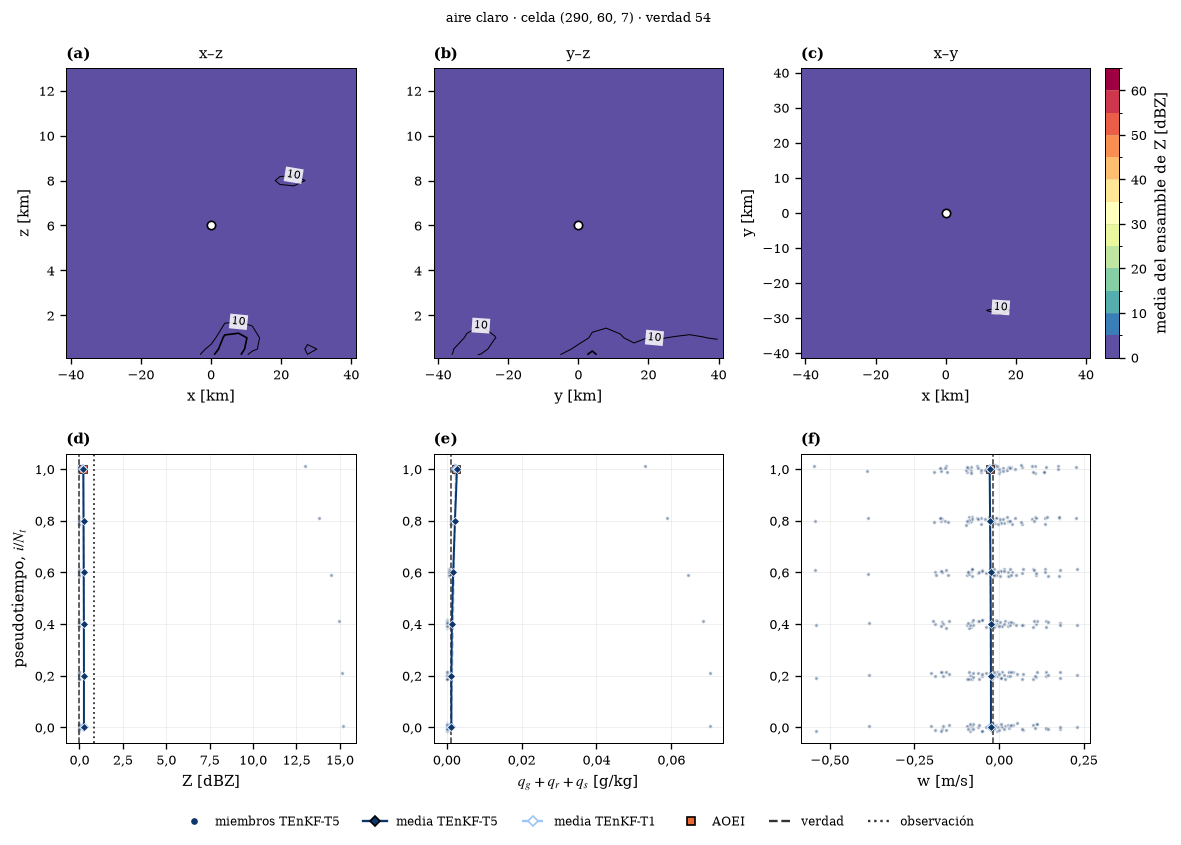

In [15]:
nb.save(lambda lang, r=r: draw_point(lang, r), f"N3s/points/{r.condition}/{point_name(r)}",
            show=SHOW)

figures/es/N3s/points/core/core_180_150_2_tm10.png  figures/en/N3s/points/core/core_180_150_2_tm10.png


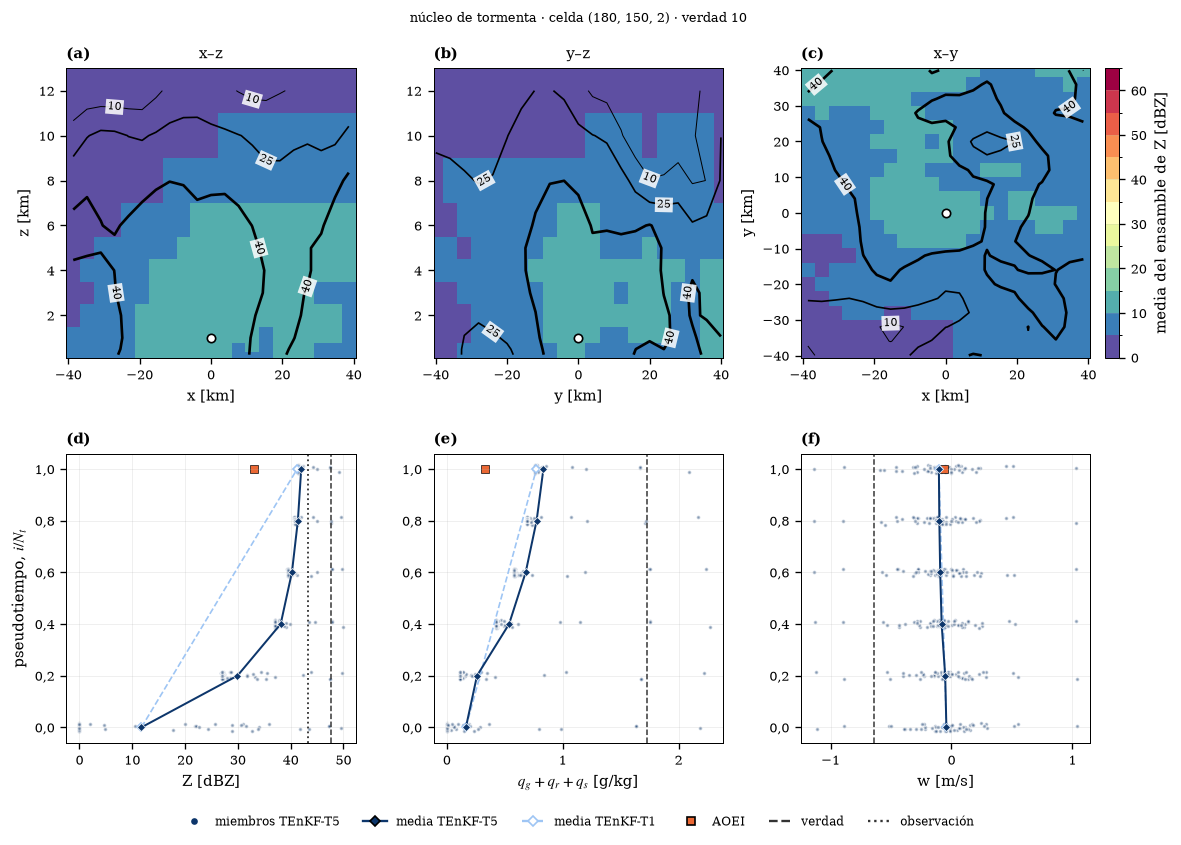

figures/es/N3s/points/core/core_210_180_6_tm48.png  figures/en/N3s/points/core/core_210_180_6_tm48.png
figures/es/N3s/points/core/core_150_350_3_tm08.png  figures/en/N3s/points/core/core_150_350_3_tm08.png
figures/es/N3s/points/core/core_150_370_7_tm40.png  figures/en/N3s/points/core/core_150_370_7_tm40.png
figures/es/N3s/points/core/core_140_380_8_tm06.png  figures/en/N3s/points/core/core_140_380_8_tm06.png
figures/es/N3s/points/core/core_170_420_6_tm25.png  figures/en/N3s/points/core/core_170_420_6_tm25.png
figures/es/N3s/points/core/core_120_370_8_tm47.png  figures/en/N3s/points/core/core_120_370_8_tm47.png
figures/es/N3s/points/core/core_160_310_7_tm23.png  figures/en/N3s/points/core/core_160_310_7_tm23.png
figures/es/N3s/points/core/core_160_420_0_tm25.png  figures/en/N3s/points/core/core_160_420_0_tm25.png
figures/es/N3s/points/core/core_230_40_3_tm39.png  figures/en/N3s/points/core/core_230_40_3_tm39.png
figures/es/N3s/points/edge/edge_190_160_4_tm01.png  figures/en/N3s/points/e

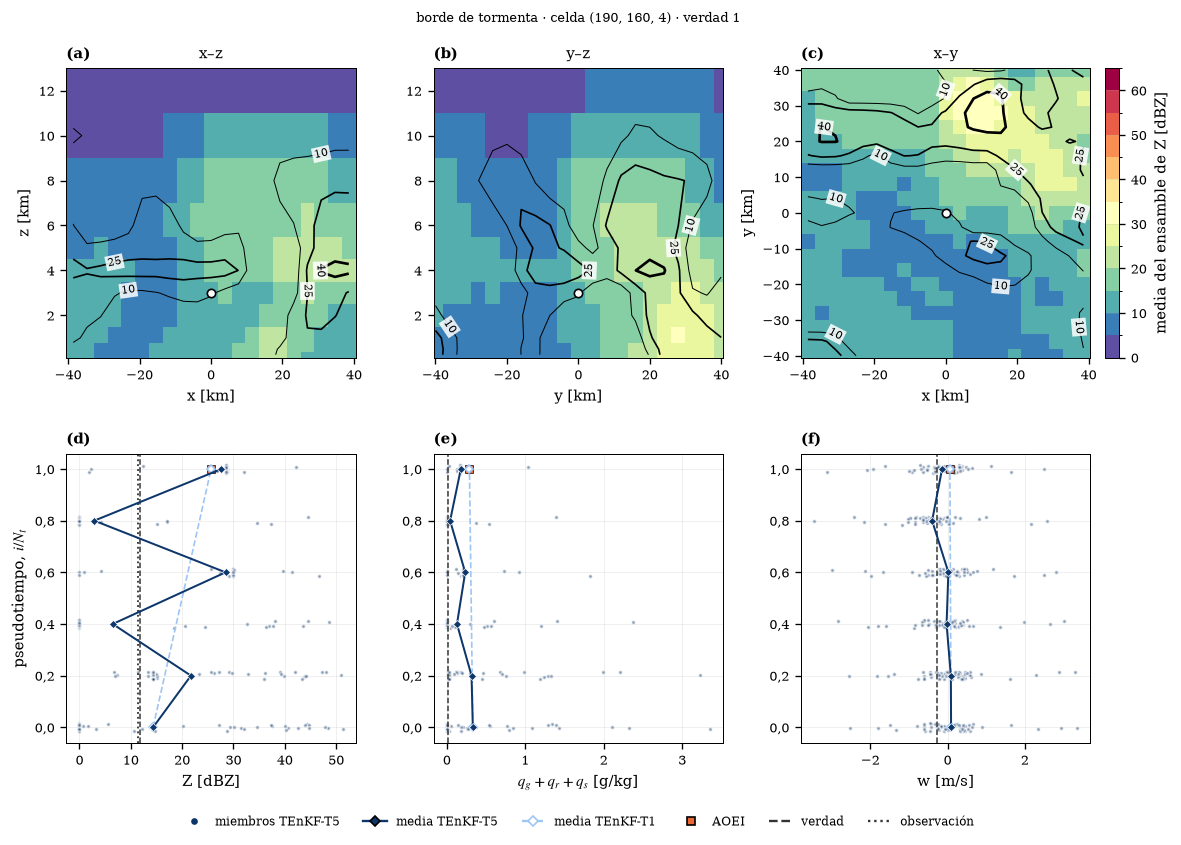

figures/es/N3s/points/edge/edge_230_300_6_tm36.png  figures/en/N3s/points/edge/edge_230_300_6_tm36.png
figures/es/N3s/points/edge/edge_200_300_6_tm43.png  figures/en/N3s/points/edge/edge_200_300_6_tm43.png
figures/es/N3s/points/edge/edge_140_420_6_tm48.png  figures/en/N3s/points/edge/edge_140_420_6_tm48.png
figures/es/N3s/points/edge/edge_270_160_3_tm00.png  figures/en/N3s/points/edge/edge_270_160_3_tm00.png
figures/es/N3s/points/edge/edge_200_430_6_tm34.png  figures/en/N3s/points/edge/edge_200_430_6_tm34.png
figures/es/N3s/points/edge/edge_130_330_3_tm38.png  figures/en/N3s/points/edge/edge_130_330_3_tm38.png
figures/es/N3s/points/edge/edge_190_340_8_tm53.png  figures/en/N3s/points/edge/edge_190_340_8_tm53.png
figures/es/N3s/points/edge/edge_300_280_6_tm22.png  figures/en/N3s/points/edge/edge_300_280_6_tm22.png
figures/es/N3s/points/edge/edge_200_300_10_tm45.png  figures/en/N3s/points/edge/edge_200_300_10_tm45.png
figures/es/N3s/points/updraft/updraft_134_218_7_tm59.png  figures/en/N3

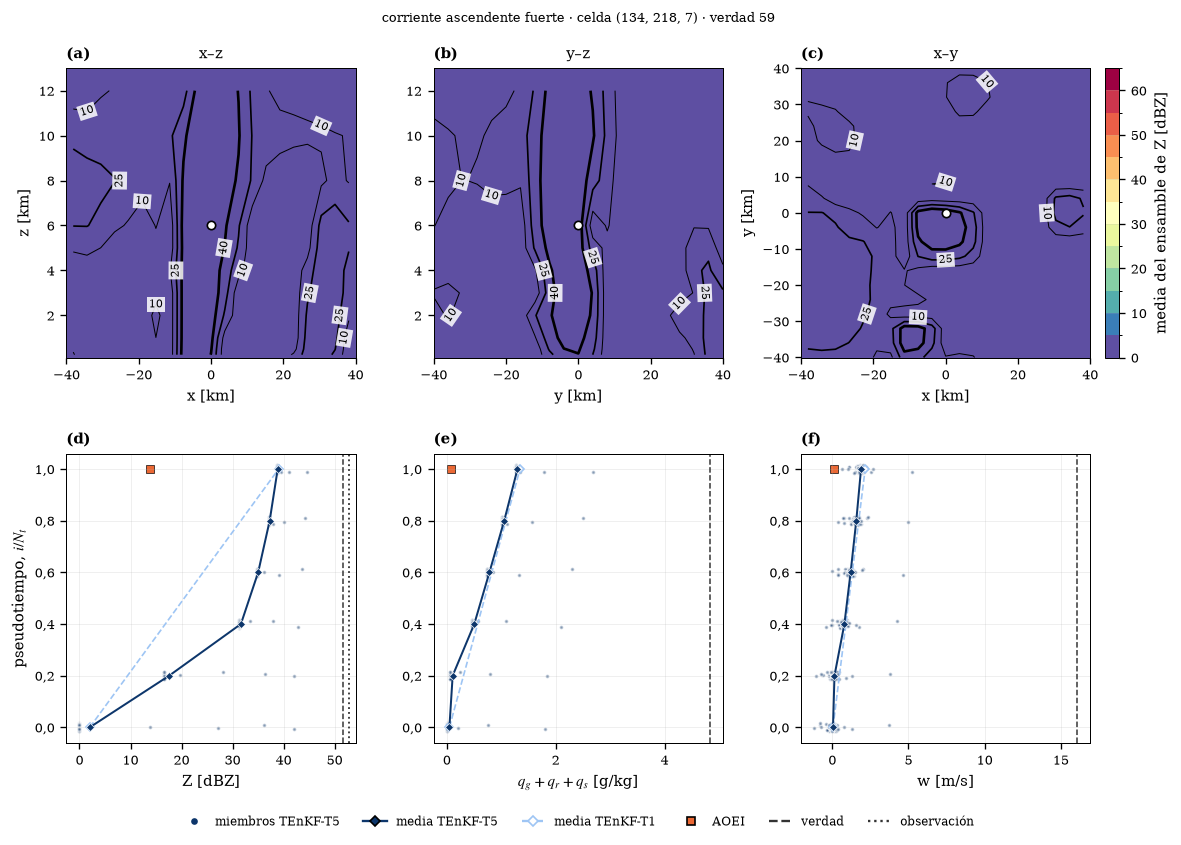

figures/es/N3s/points/updraft/updraft_155_346_10_tm25.png  figures/en/N3s/points/updraft/updraft_155_346_10_tm25.png
figures/es/N3s/points/updraft/updraft_122_407_10_tm51.png  figures/en/N3s/points/updraft/updraft_122_407_10_tm51.png
figures/es/N3s/points/updraft/updraft_137_365_8_tm38.png  figures/en/N3s/points/updraft/updraft_137_365_8_tm38.png
figures/es/N3s/points/updraft/updraft_159_301_8_tm44.png  figures/en/N3s/points/updraft/updraft_159_301_8_tm44.png
figures/es/N3s/points/updraft/updraft_55_102_8_tm48.png  figures/en/N3s/points/updraft/updraft_55_102_8_tm48.png
figures/es/N3s/points/updraft/updraft_131_368_9_tm52.png  figures/en/N3s/points/updraft/updraft_131_368_9_tm52.png
figures/es/N3s/points/updraft/updraft_166_361_7_tm47.png  figures/en/N3s/points/updraft/updraft_166_361_7_tm47.png
figures/es/N3s/points/updraft/updraft_231_291_10_tm55.png  figures/en/N3s/points/updraft/updraft_231_291_10_tm55.png
figures/es/N3s/points/updraft/updraft_164_309_8_tm14.png  figures/en/N3s/poi

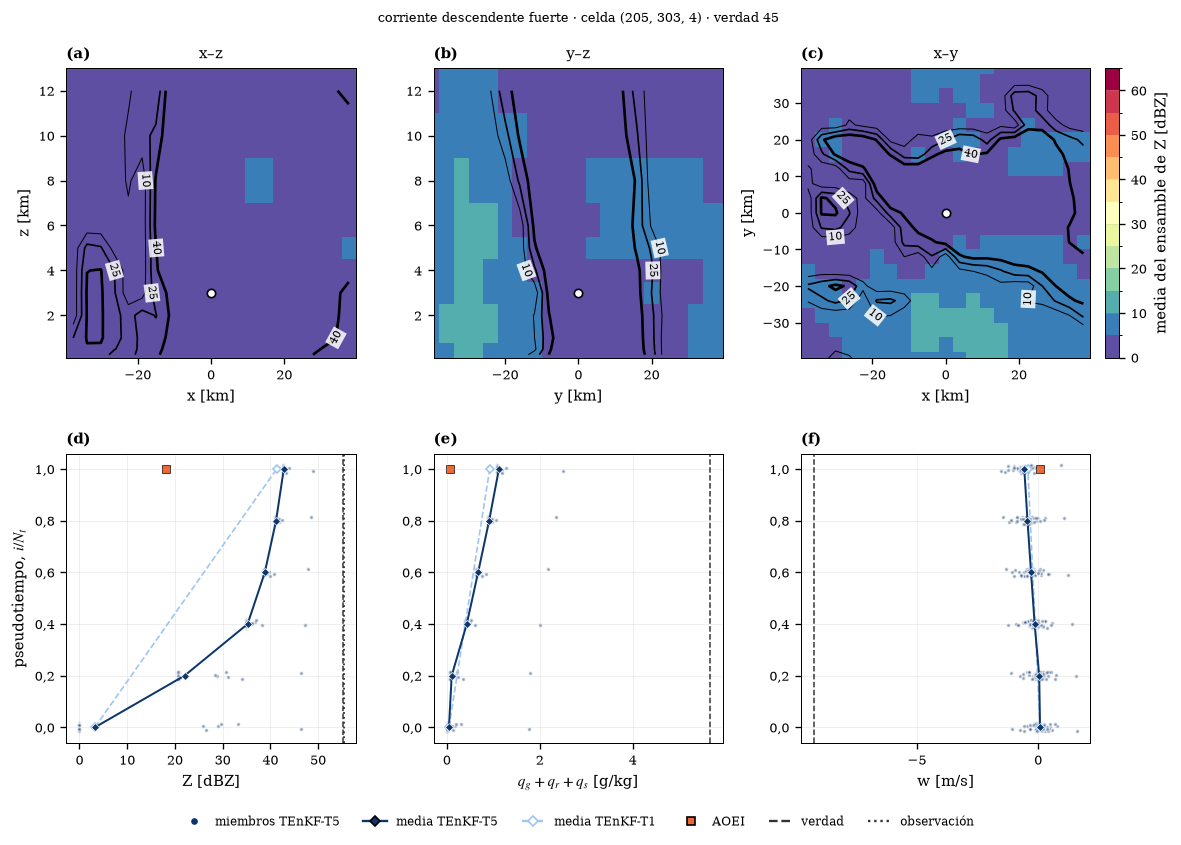

figures/es/N3s/points/downdraft/downdraft_34_135_7_tm16.png  figures/en/N3s/points/downdraft/downdraft_34_135_7_tm16.png
figures/es/N3s/points/downdraft/downdraft_145_313_10_tm32.png  figures/en/N3s/points/downdraft/downdraft_145_313_10_tm32.png
figures/es/N3s/points/downdraft/downdraft_246_251_10_tm01.png  figures/en/N3s/points/downdraft/downdraft_246_251_10_tm01.png
figures/es/N3s/points/downdraft/downdraft_114_216_9_tm05.png  figures/en/N3s/points/downdraft/downdraft_114_216_9_tm05.png
figures/es/N3s/points/downdraft/downdraft_65_91_8_tm18.png  figures/en/N3s/points/downdraft/downdraft_65_91_8_tm18.png
figures/es/N3s/points/downdraft/downdraft_253_241_5_tm31.png  figures/en/N3s/points/downdraft/downdraft_253_241_5_tm31.png
figures/es/N3s/points/downdraft/downdraft_150_303_10_tm08.png  figures/en/N3s/points/downdraft/downdraft_150_303_10_tm08.png
figures/es/N3s/points/downdraft/downdraft_148_204_4_tm29.png  figures/en/N3s/points/downdraft/downdraft_148_204_4_tm29.png
figures/es/N3s/p

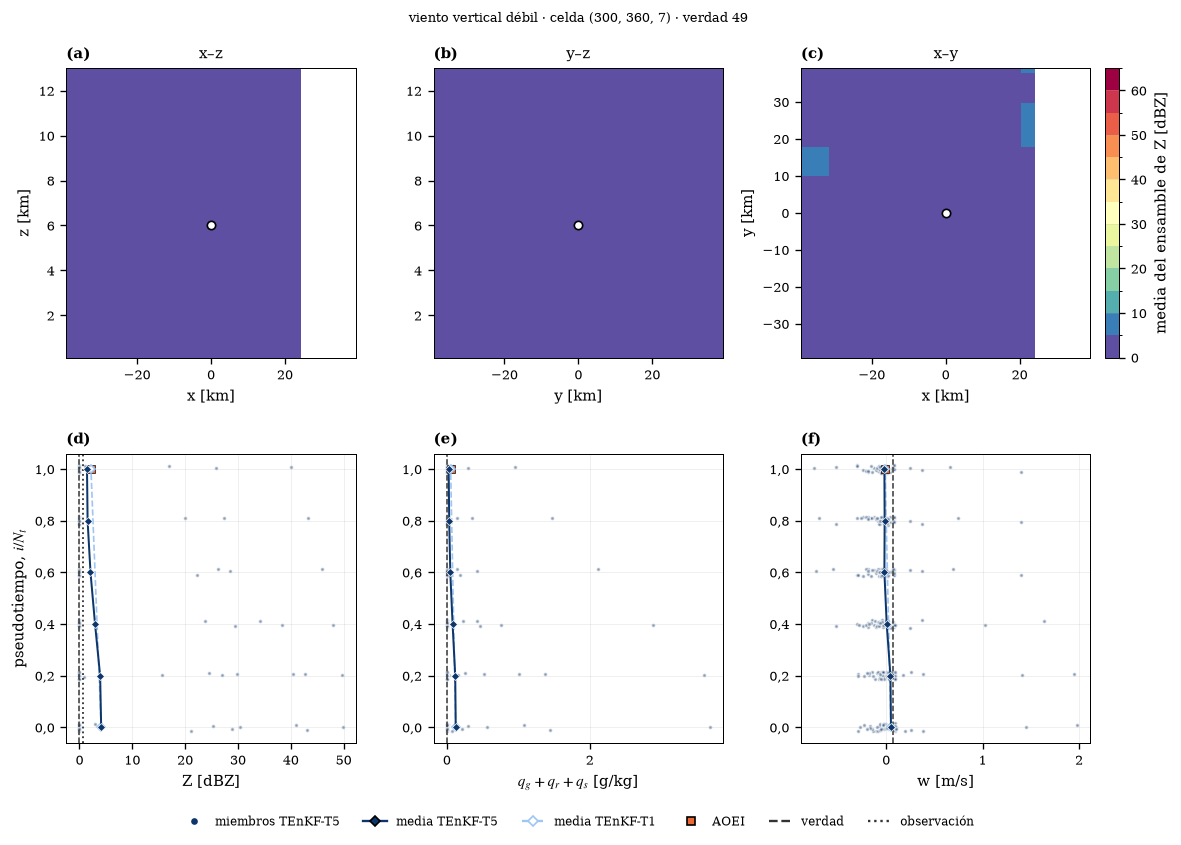

figures/es/N3s/points/weak/weak_100_310_2_tm52.png  figures/en/N3s/points/weak/weak_100_310_2_tm52.png
figures/es/N3s/points/weak/weak_160_50_4_tm44.png  figures/en/N3s/points/weak/weak_160_50_4_tm44.png
figures/es/N3s/points/weak/weak_220_0_6_tm26.png  figures/en/N3s/points/weak/weak_220_0_6_tm26.png
figures/es/N3s/points/weak/weak_170_140_6_tm44.png  figures/en/N3s/points/weak/weak_170_140_6_tm44.png
figures/es/N3s/points/weak/weak_290_0_3_tm55.png  figures/en/N3s/points/weak/weak_290_0_3_tm55.png
figures/es/N3s/points/weak/weak_260_60_7_tm57.png  figures/en/N3s/points/weak/weak_260_60_7_tm57.png
figures/es/N3s/points/weak/weak_180_50_1_tm51.png  figures/en/N3s/points/weak/weak_180_50_1_tm51.png
figures/es/N3s/points/weak/weak_180_300_10_tm46.png  figures/en/N3s/points/weak/weak_180_300_10_tm46.png
figures/es/N3s/points/weak/weak_280_400_2_tm46.png  figures/en/N3s/points/weak/weak_280_400_2_tm46.png
figures/es/N3s/points/clear/clear_230_60_7_tm39.png  figures/en/N3s/points/clear/clea

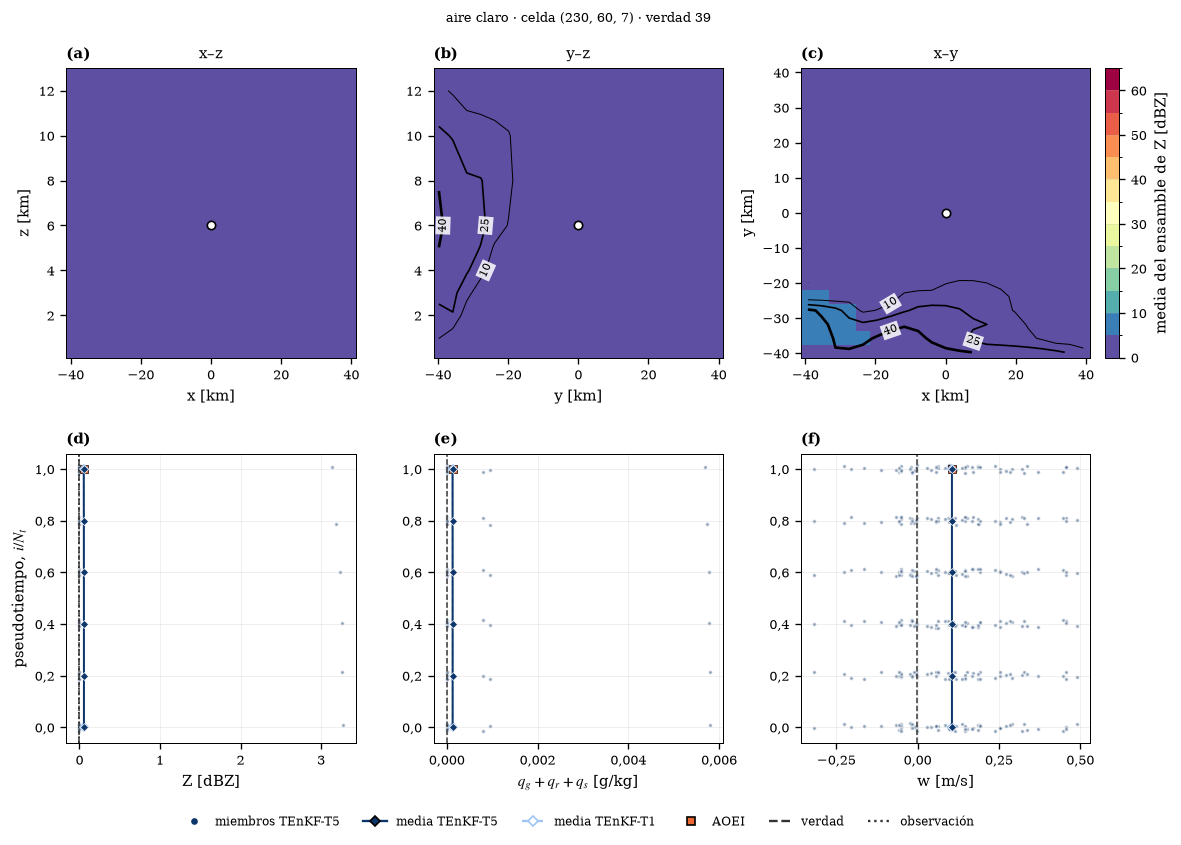

figures/es/N3s/points/clear/clear_280_30_0_tm15.png  figures/en/N3s/points/clear/clear_280_30_0_tm15.png
figures/es/N3s/points/clear/clear_220_70_2_tm18.png  figures/en/N3s/points/clear/clear_220_70_2_tm18.png
figures/es/N3s/points/clear/clear_90_440_0_tm16.png  figures/en/N3s/points/clear/clear_90_440_0_tm16.png
figures/es/N3s/points/clear/clear_270_260_10_tm47.png  figures/en/N3s/points/clear/clear_270_260_10_tm47.png
figures/es/N3s/points/clear/clear_170_240_5_tm23.png  figures/en/N3s/points/clear/clear_170_240_5_tm23.png
figures/es/N3s/points/clear/clear_270_30_2_tm36.png  figures/en/N3s/points/clear/clear_270_30_2_tm36.png
figures/es/N3s/points/clear/clear_170_160_1_tm45.png  figures/en/N3s/points/clear/clear_170_160_1_tm45.png
figures/es/N3s/points/clear/clear_210_250_6_tm34.png  figures/en/N3s/points/clear/clear_210_250_6_tm34.png
figures/es/N3s/points/clear/clear_290_60_7_tm54.png  figures/en/N3s/points/clear/clear_290_60_7_tm54.png
120 figuras por punto en 52 s


In [16]:
# Las 60 figuras por punto, en los dos idiomas, sin mostrarlas; en línea, la primera de cada condición.
t0 = time.time()
for r in SEL.itertuples(index=False):
    first = r == next(SEL[SEL.condition == r.condition].itertuples(index=False))
    nb.save(lambda lang, r=r: draw_point(lang, r), f"N3s/points/{r.condition}/{point_name(r)}",
            show=SHOW if first else False)
    if first:
        plt.show()
print(f"{2 * len(SEL)} figuras por punto en {time.time() - t0:.0f} s")

In [17]:
def summary_series(P_, method, ntemp, v, kind):
    t, tru = trajectory(P_, method, ntemp), truth_of(P_)
    key = "w_" if v == "w" else v
    X = t[key]
    if kind == "abs_err":
        return t["w"], np.abs(X.mean(1) - tru[v])
    if kind == "spread":
        return t["w"], X.std(1, ddof=1)
    if kind == "n_echo":                      # miembros con eco en el ensamble que entra a cada paso
        return t["w"][:-1], (t["Z"][:-1] > DBZ_MIN).sum(1).astype(float)
    # correlación con Z del ensamble que entra a cada paso: el prior y los pasos salvo el último
    Zs, Xs = t["Z"][:-1], X[:-1]
    with np.errstate(invalid="ignore", divide="ignore"):
        za, xa_ = Zs - Zs.mean(1, keepdims=True), Xs - Xs.mean(1, keepdims=True)
        rho = (za * xa_).sum(1) / np.sqrt((za ** 2).sum(1) * (xa_ ** 2).sum(1))
    return t["w"][:-1], rho


def draw_summary(lang, cond):
    V, L = nb.VOCAB[lang], LABELS[lang]
    pts = SEL[SEL.condition == cond]
    kinds = ("abs_err", "spread", "corr")
    fig, axes = plt.subplots(3, 3, figsize=(nb.PAGE_W * 1.45, nb.PAGE_W * 1.05), sharex=True,
                             constrained_layout=True)
    for c, v in enumerate(TVARS):
        for r_, kind in enumerate(kinds):
            kind = "n_echo" if (v, kind) == ("Z", "corr") else kind
            ax = axes[r_, c]
            ys = []
            for r in pts.itertuples(index=False):
                w, y = summary_series(STEPS[point_name(r)], "TEnKF", 5, v, kind)
                ax.plot(w, y, "-", lw=0.6, alpha=0.45, color=COL[5])
                ys.append(y)
            ax.plot(w, np.nanmean(ys, axis=0), "-o", ms=3, lw=2.0, color=COL[5])
            if kind not in ("corr", "n_echo"):
                # AOEI hueco y abajo, T1 lleno y arriba: si caen en el mismo lugar se ven los dos
                for meth, nt, kw in (("AOEI", 1, dict(marker="s", ms=6.5, mfc="none", mec=COL["AOEI"], mew=1.3, zorder=5)),
                                     ("TEnKF", 1, dict(marker="D", ms=4.5, color=COL[1], mec="k", mew=0.5, zorder=6))):
                    end = np.nanmean([summary_series(STEPS[point_name(r)], meth, nt, v, kind)[1][-1]
                                      for r in pts.itertuples(index=False)])
                    ax.plot([1.0], [end], ls="", **kw)
            if r_ == 0:
                ax.set_title(L[v])
            if r_ == 2:
                ax.set_xlabel(L["ptime"])
        axes[0, c].set_ylim(bottom=0)
        axes[2, c].set_ylim(*((-1.5, NM - 1 + 1.5) if v == "Z" else (-1.05, 1.05)))
    axes[0, 0].set_ylabel(L["abs_err"])
    axes[1, 0].set_ylabel(V["ens_spread"])
    axes[2, 0].set_ylabel(L["n_echo_in"])
    axes[2, 1].set_ylabel(L["corr"])
    from matplotlib.lines import Line2D
    fig.legend(handles=[Line2D([], [], color=COL[5], lw=0.6, alpha=0.6, label=L["pts_t5"]),
                        Line2D([], [], color=COL[5], lw=2.0, marker="o", ms=5, label=L["mean_pts_t5"]),
                        Line2D([], [], ls="", marker="D", ms=4.5, color=COL[1], mec="k", label=L["t1_mean_pts"]),
                        Line2D([], [], ls="", marker="s", ms=6.5, mfc="none", mec=COL["AOEI"], mew=1.3,
                               label=L["aoei_mean_pts"])],
               loc="outside lower center", ncol=4, frameon=False, fontsize=7)
    return fig

figures/es/N3s/core_summary.png  figures/en/N3s/core_summary.png


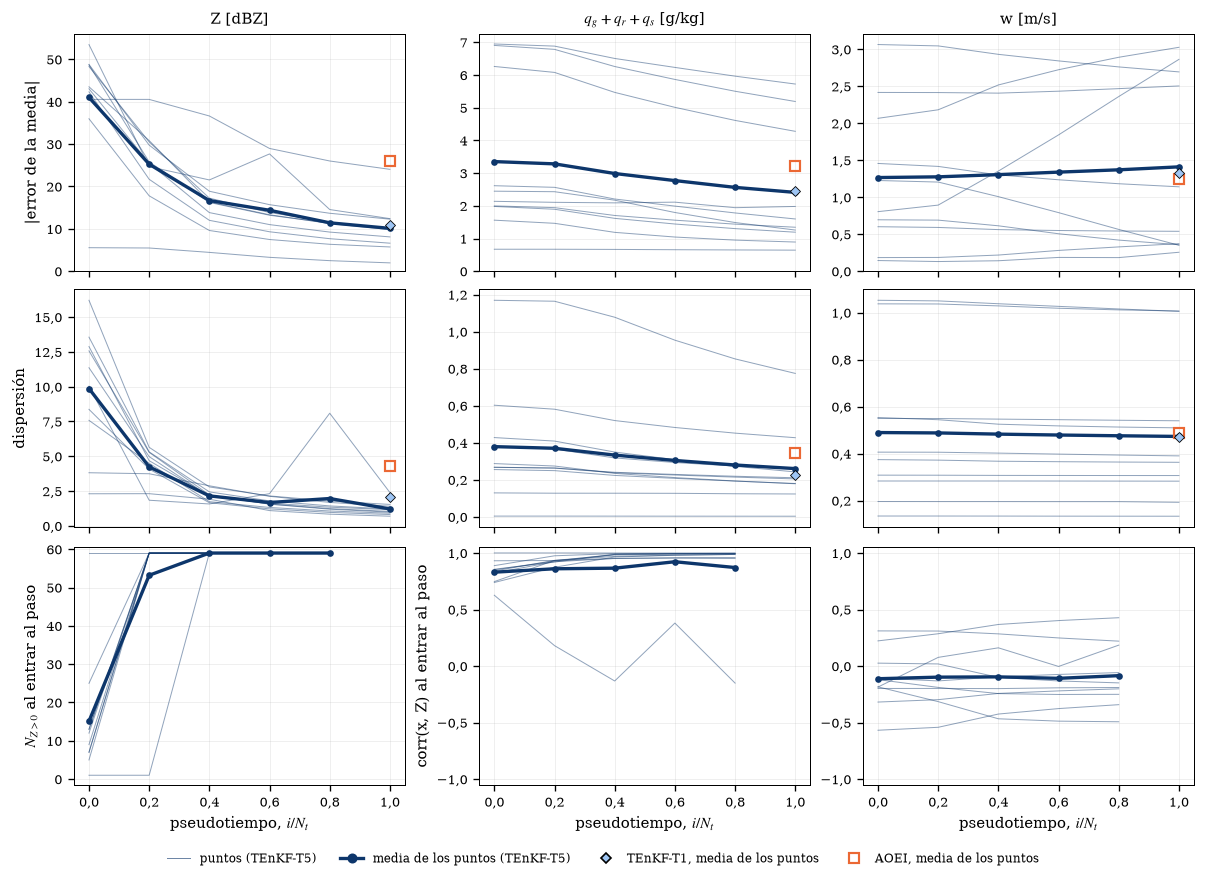

figures/es/N3s/edge_summary.png  figures/en/N3s/edge_summary.png


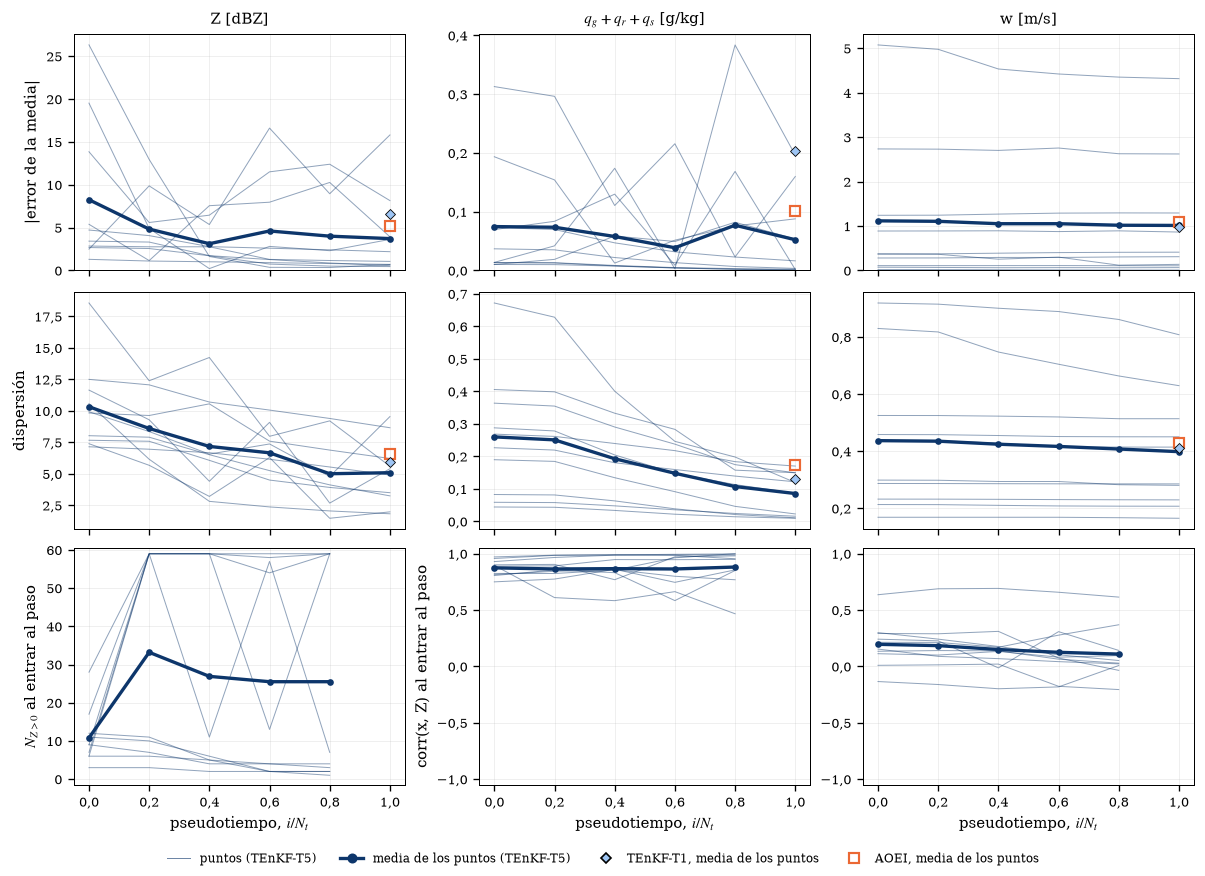

figures/es/N3s/updraft_summary.png  figures/en/N3s/updraft_summary.png


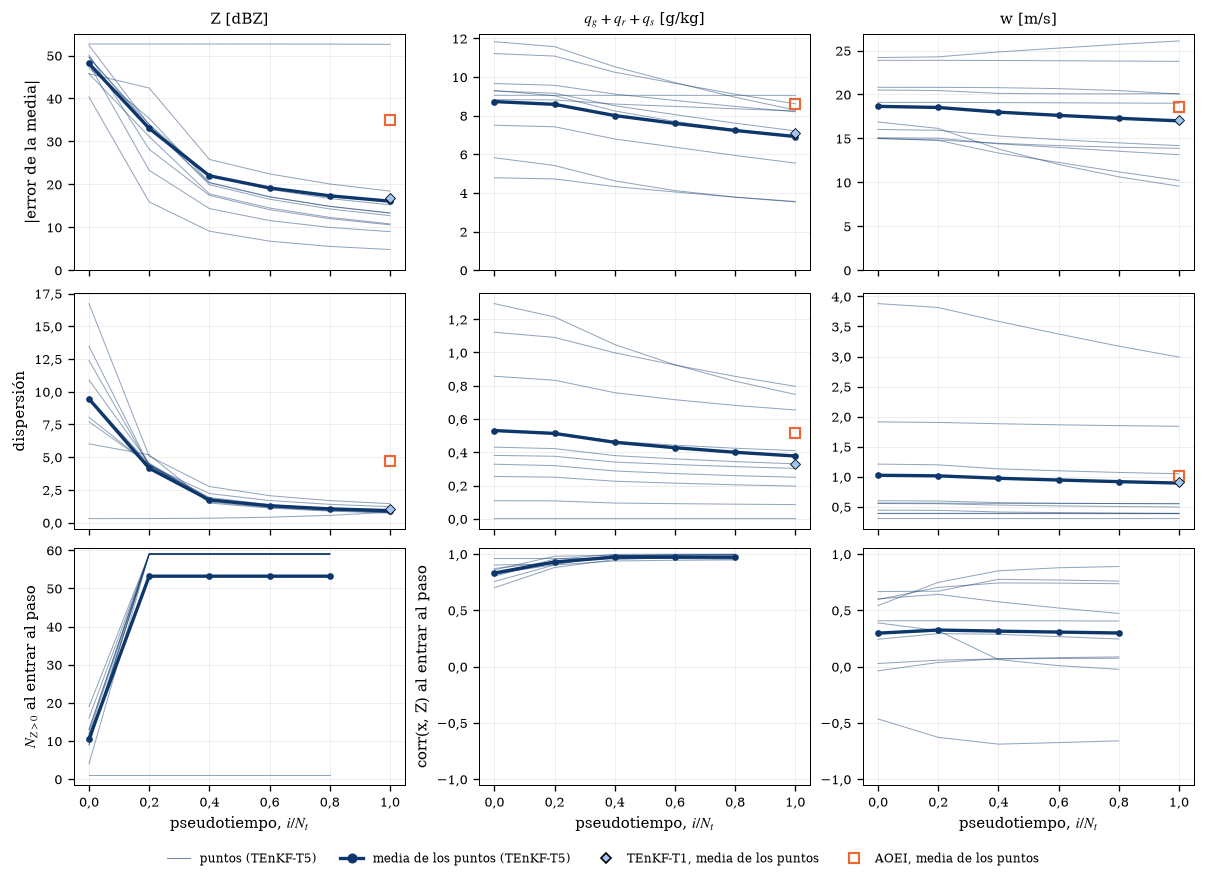

figures/es/N3s/downdraft_summary.png  figures/en/N3s/downdraft_summary.png


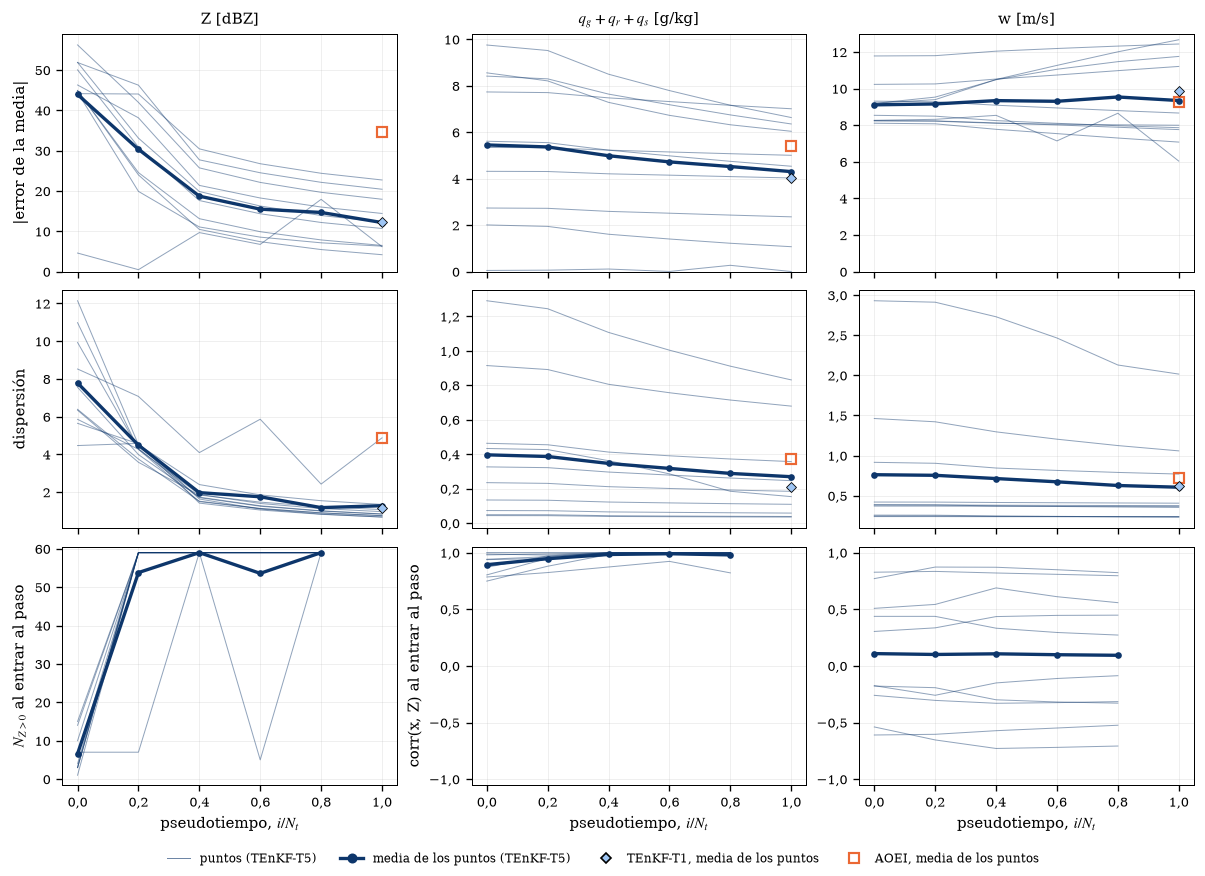

figures/es/N3s/weak_summary.png  figures/en/N3s/weak_summary.png


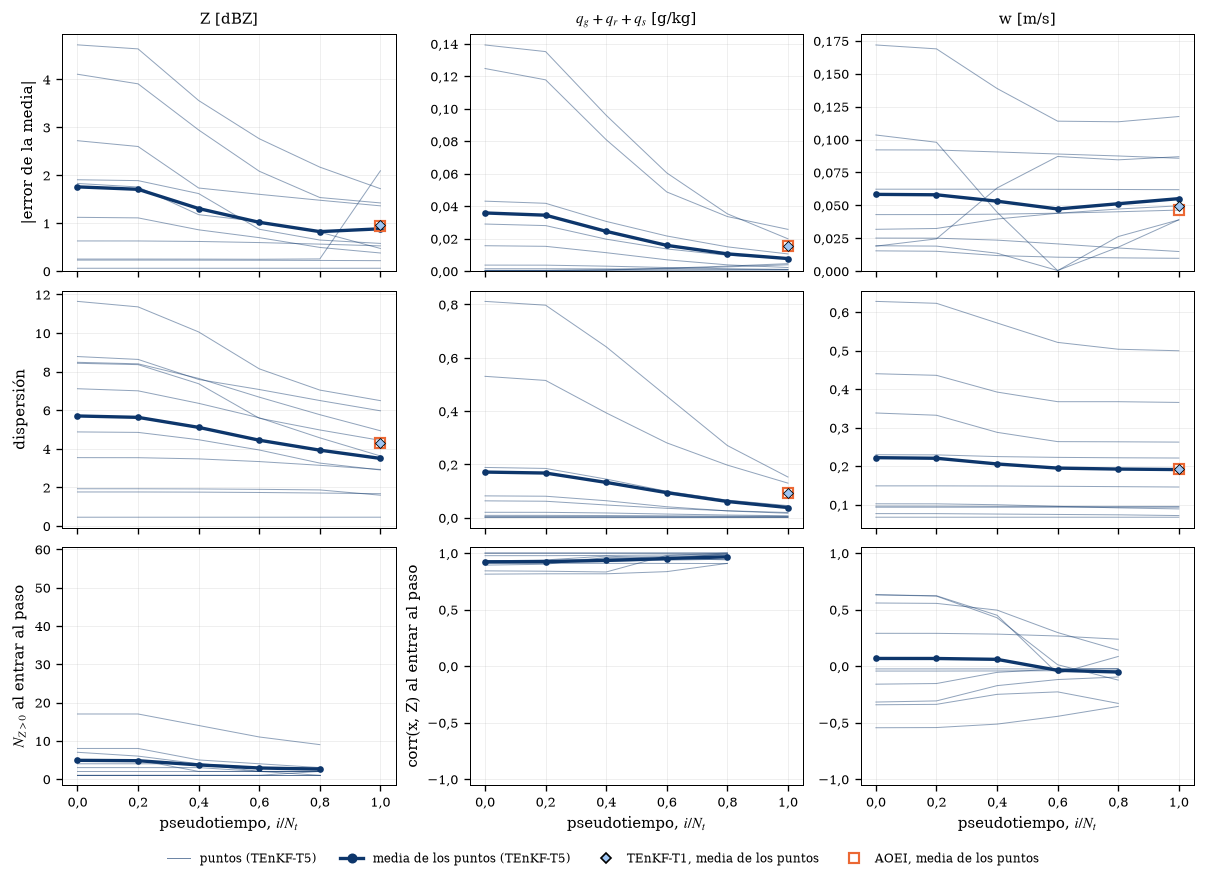

figures/es/N3s/clear_summary.png  figures/en/N3s/clear_summary.png


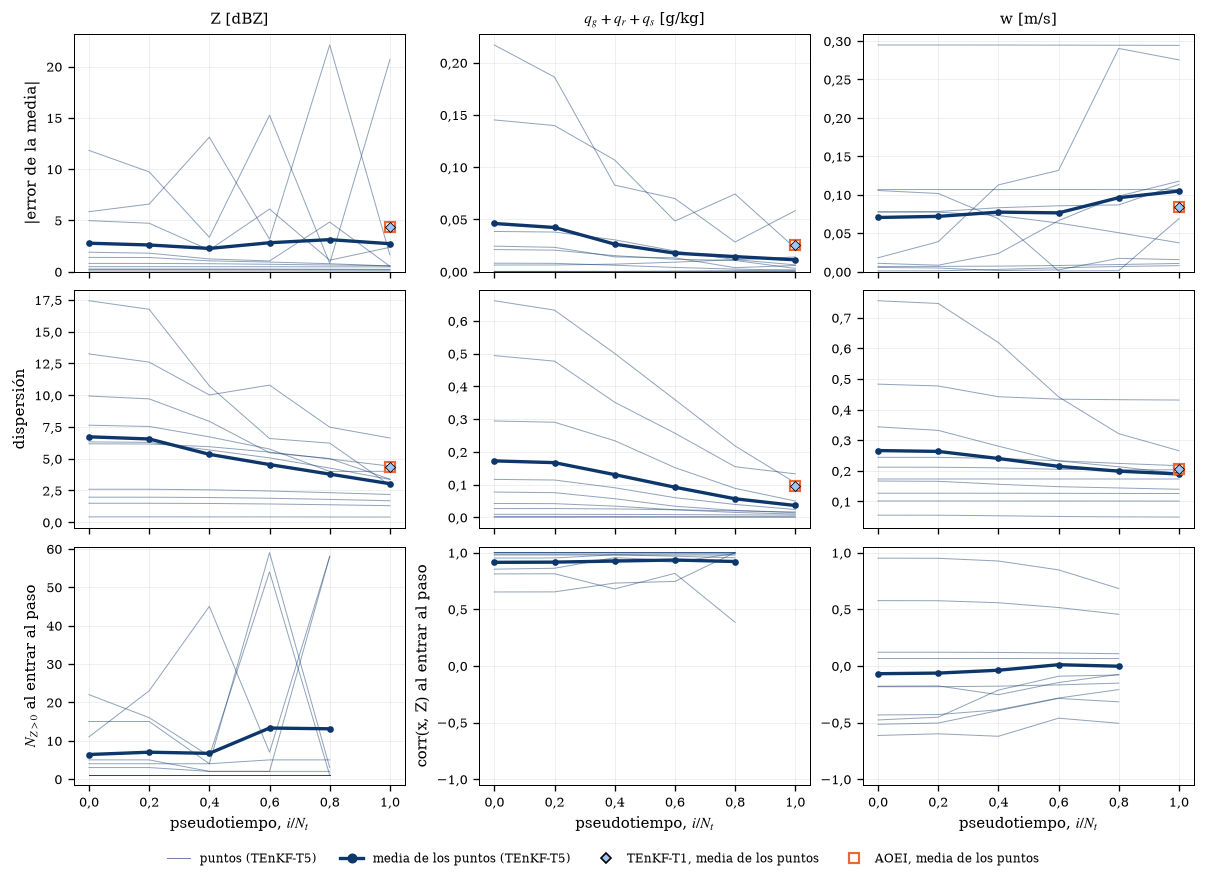

In [18]:
for c in CONDITIONS:
    nb.save(lambda lang, c=c: draw_summary(lang, c), f"N3s/{c}_summary", show=SHOW)
    plt.show()

## 7 · Tablas

Sobre los 60 puntos, con la censura en cada paso salvo en la comparación de censuras. Junto a cada condición de corriente vertical van, para comparar, sus puntos de la primera selección ($|w_t| \ge$ 1 m/s, en `old_w1/`), con «(w1)» en el nombre.

1. Miembros con eco y error de $Z$ por condición (TEnKF-T5): $N_{Z>0}$ del prior y después del primer paso; el error de la media de $Z$ (media − verdad) en el prior, después del paso 1 y al final, con signo y en valor absoluto, promediado sobre los 10 puntos.
2. El cambio de la media de $Z$ en cada paso de TEnKF-T5, previsto y realizado. El previsto es el de un operador lineal con la ganancia del ensamble que entra al paso: $K\,d$, con $K = \sigma_Z^2 / (\sigma_Z^2 + R_\mathrm{eff})$. El realizado es el cambio de la media de $H(\mathbf{x})$. También lo que aportan los miembros que entran al paso en el piso, $\sum_{H \le 0} \Delta H / 59$, y su parte del realizado (vacía si el realizado es menor que 0,1 dBZ).
3. La alternancia de signo del error de $Z$ entre pasos consecutivos: de los pares (paso $i$, paso $i+1$), incluido el par (prior, paso 1), cuántos cambian de signo. Un error con $|e| \le$ 10⁻³ dBZ no tiene signo y su par se cuenta aparte.
4. La comparación de censuras: la media final con la censura solo al final menos con la censura en cada paso, por condición y esquema, para $Z$, $q_g+q_r+q_s$ y $w$; y lo mismo para el error absoluto de la media.

In [19]:
SIGN_TOL = 1e-3     # dBZ


def z_steps(P_, method, ntemp, mode="per_step"):
    """Z del ensamble en el prior y después de cada paso, (pasos + 1, 59), y lo de cada paso."""
    c = [q for q in range(len(P_[f"{mode}/method"]))
         if str(P_[f"{mode}/method"][q]) == method and int(P_[f"{mode}/ntemp"][q]) == ntemp][0]
    H = np.concatenate([P_["hxf_point"][None], P_[f"{mode}/c{c:02d}_hx"]]).astype(float)
    return H, P_[f"{mode}/c{c:02d}_steps_dep"].astype(float), P_[f"{mode}/c{c:02d}_steps_R_eff"].astype(float)


# Los puntos de corriente vertical de la primera selección, para ponerlos junto a los nuevos
SEL_OLD = pd.read_csv(OLD / "selection.csv").query("condition in @W_CONDS")
STEPS_OLD = {point_name(r): dict(np.load(OLD / "steps" / f"{point_name(r)}.npz"))
             for r in SEL_OLD.itertuples(index=False)}
PTS7 = ([(r.condition, STEPS[point_name(r)]) for r in SEL.itertuples(index=False)]
        + [(f"{r.condition} (w1)", STEPS_OLD[point_name(r)]) for r in SEL_OLD.itertuples(index=False)])
GROUPS7 = [g for c in CONDITIONS for g in ((c, f"{c} (w1)") if c in W_CONDS else (c,))]

rows, steprows, signrows = [], [], []
for cond, P_ in PTS7:
    yc = float(P_["yo_clean"])
    H, dep, Reff = z_steps(P_, "TEnKF", 5)
    e = H.mean(1) - yc
    rows.append(dict(condition=cond, n_prior=int((H[0] > DBZ_MIN).sum()), n_step1=int((H[1] > DBZ_MIN).sum()),
                     e_prior=e[0], e_step1=e[1], e_final=e[-1]))
    for it in range(len(dep)):
        h_in, h_out = H[it], H[it + 1]
        var = h_in.var(ddof=1)
        floor = h_in <= DBZ_MIN
        steprows.append(dict(condition=cond, step=it + 1, d=dep[it], pred=var / (var + Reff[it]) * dep[it],
                             real=h_out.mean() - h_in.mean(), floor=(h_out - h_in)[floor].sum() / h_in.size,
                             n_floor_in=int(floor.sum())))
    for nt in (2, 3, 4, 5):
        Hn, _, _ = z_steps(P_, "TEnKF", nt)
        en = Hn.mean(1) - yc
        for a, b in zip(en[:-1], en[1:]):
            signed = abs(a) > SIGN_TOL and abs(b) > SIGN_TOL
            signrows.append(dict(condition=cond, ntemp=nt, signed=signed, flip=signed and a * b < 0))
ZT = pd.DataFrame(rows)
order = {g: q for q, g in enumerate(GROUPS7)}
t = ZT.groupby("condition").agg(
    N_prior=("n_prior", "mean"), N_paso1=("n_step1", "mean"),
    e_prior=("e_prior", "mean"), e_paso1=("e_step1", "mean"), e_final=("e_final", "mean"),
    abs_e_prior=("e_prior", lambda v: v.abs().mean()), abs_e_paso1=("e_step1", lambda v: v.abs().mean()),
    abs_e_final=("e_final", lambda v: v.abs().mean())).sort_index(key=lambda i: i.map(order))
print("TEnKF-T5, media sobre los 10 puntos de cada condición («(w1)»: los de la primera selección). N_Z>0 de 59; error de Z [dBZ] = media − verdad")
print(t.to_string(float_format=lambda v: f"{v:.2f}"))

TEnKF-T5, media sobre los 10 puntos de cada condición («(w1)»: los de la primera selección). N_Z>0 de 59; error de Z [dBZ] = media − verdad
                N_prior  N_paso1  e_prior  e_paso1  e_final  abs_e_prior  abs_e_paso1  abs_e_final
condition                                                                                         
core              15.10    53.20   -41.03   -25.26   -10.11        41.03        25.26        10.11
edge              10.80    33.20    -4.76    -0.09     2.21         8.26         4.83         3.72
updraft           10.60    53.20   -48.15   -33.03   -16.07        48.15        33.03        16.07
updraft (w1)      14.60    48.70   -16.09    -9.12     0.73        17.50        10.34         2.61
downdraft          6.60    53.80   -43.94   -30.34   -12.18        43.94        30.34        12.18
downdraft (w1)     4.10    18.70   -17.27   -11.15    -5.05        17.51        11.39         5.26
weak               4.90     4.80     1.76     1.71     0.88         

In [20]:
ST7 = pd.DataFrame(steprows)
g = ST7.groupby(["condition", "step"]).agg(d=("d", "mean"), previsto=("pred", "mean"), realizado=("real", "mean"),
                                           desde_el_piso=("floor", "mean"), miembros_en_el_piso=("n_floor_in", "mean"))
# La parte del piso solo tiene sentido si hay un cambio que repartir.
g["parte_del_piso"] = (g.desde_el_piso / g.realizado).where(g.realizado.abs() >= 0.1)
g = g.sort_index(level=0, key=lambda i: i.map(order) if i.name == "condition" else i)
print("TEnKF-T5: cambio de la media de Z en cada paso [dBZ], media sobre los 10 puntos")
print(g.to_string(float_format=lambda v: f"{v:.2f}"))

TEnKF-T5: cambio de la media de Z en cada paso [dBZ], media sobre los 10 puntos
                        d  previsto  realizado  desde_el_piso  miembros_en_el_piso  parte_del_piso
condition      step                                                                               
core           1    40.19      3.01      15.77          14.95                43.90            0.95
               2    24.42      4.65       8.58           0.39                 5.80            0.05
               3    15.84      2.06       2.30           0.00                 0.00            0.00
               4    13.54      1.96       2.96           0.00                 0.00            0.00
               5    10.58      2.43       1.31           0.00                 0.00            0.00
edge           1     4.95      0.28       4.67           4.68                48.20            1.00
               2     0.28     -0.42       1.82           0.00                25.80            0.00
               3    -1.54    

In [21]:
SG = pd.DataFrame(signrows)
sg = SG.groupby(["condition", "ntemp"]).agg(pares=("flip", "size"), con_signo=("signed", "sum"), cambian=("flip", "sum"))
sg["fracción que cambia"] = sg.cambian / sg.con_signo
sg = sg.sort_index(level=0, key=lambda i: i.map(order) if i.name == "condition" else i)
print("Cambio de signo del error de Z entre pasos consecutivos (incluido prior → paso 1)")
print(sg.to_string(float_format=lambda v: f"{v:.2f}"))
tot = SG[SG.ntemp == 5].groupby("condition").agg(con_signo=("signed", "sum"), cambian=("flip", "sum"))
print("\nTEnKF-T5:", ", ".join(f"{c} {tot.loc[c, 'cambian']}/{tot.loc[c, 'con_signo']}" for c in GROUPS7))

Cambio de signo del error de Z entre pasos consecutivos (incluido prior → paso 1)
                      pares  con_signo  cambian  fracción que cambia
condition      ntemp                                                
core           2         20         20        0                 0.00
               3         30         30        0                 0.00
               4         40         40        0                 0.00
               5         50         50        0                 0.00
edge           2         20         20        7                 0.35
               3         30         30       11                 0.37
               4         40         40       16                 0.40
               5         50         50       16                 0.32
updraft        2         20         20        0                 0.00
               3         30         30        0                 0.00
               4         40         40        0                 0.00
               5     

In [22]:
# Censura solo al final menos censura en cada paso, en la media final y en el error absoluto de la media.
rows = []
for cond, P_ in PTS7:
    tru = truth_of(P_)
    for c, (meth, nt) in enumerate((str(a), int(b)) for a, b in zip(P_["per_step/method"], P_["per_step/ntemp"])):
        row = dict(condition=cond, scheme="AOEI" if meth == "AOEI" else f"TEnKF-T{nt}")
        for mode in CLAMP_MODES:
            X = P_[f"{mode}/c{c:02d}_state_post_clamp"][-1].astype(float)
            vals = {"Z": P_[f"{mode}/c{c:02d}_hx"][-1].astype(float).mean(),
                    "qtot": X[:, IQ].sum(1).mean() * 1e3, "w": X[:, nb.VI["w"]].mean()}
            for v, x_ in vals.items():
                row[f"{v}_{mode}"] = x_
        for v in TVARS:
            row[f"Δ {v}"] = row[f"{v}_final"] - row[f"{v}_per_step"]
            row[f"Δ|e| {v}"] = abs(row[f"{v}_final"] - tru[v]) - abs(row[f"{v}_per_step"] - tru[v])
        rows.append(row)
CL = pd.DataFrame(rows)
cols = [f"Δ {v}" for v in TVARS] + [f"Δ|e| {v}" for v in TVARS]
cl = CL.groupby(["condition", "scheme"], sort=False)[cols].mean()
cl = cl.sort_index(level=0, key=lambda i: i.map(order) if i.name == "condition" else i, sort_remaining=False)
print("Censura al final − censura en cada paso, media sobre los 10 puntos (Z [dBZ], q_g+q_r+q_s [g/kg], w [m/s])")
print(cl.to_string(float_format=lambda v: f"{v:+.4f}"))
assert (CL[CL.scheme.isin(["TEnKF-T1", "AOEI"])][cols] == 0).all().all(), "un paso: las dos censuras difieren"

Censura al final − censura en cada paso, media sobre los 10 puntos (Z [dBZ], q_g+q_r+q_s [g/kg], w [m/s])
                            Δ Z  Δ qtot     Δ w  Δ|e| Z  Δ|e| qtot  Δ|e| w
condition      scheme                                                     
core           TEnKF-T1 +0.0000 +0.0000 +0.0000 +0.0000    +0.0000 +0.0000
               TEnKF-T2 +0.0000 -0.0000 +0.0000 +0.0000    +0.0000 +0.0000
               TEnKF-T3 +0.0000 +0.0000 +0.0000 +0.0000    -0.0000 +0.0000
               TEnKF-T4 +0.0000 +0.0000 +0.0000 +0.0000    -0.0000 +0.0000
               TEnKF-T5 +0.0002 -0.0001 -0.0000 -0.0002    +0.0001 -0.0000
               AOEI     +0.0000 +0.0000 +0.0000 +0.0000    +0.0000 +0.0000
edge           TEnKF-T1 +0.0000 +0.0000 +0.0000 +0.0000    +0.0000 +0.0000
               TEnKF-T2 -0.3857 -0.0027 +0.0000 +0.3840    -0.0027 +0.0000
               TEnKF-T3 -1.6087 -0.0213 +0.0022 -1.0775    -0.0213 +0.0022
               TEnKF-T4 +1.8989 +0.0087 +0.0075 +0.3113    +0.0080 +0

## 8 · Hidrometeoros en aire claro: ¿el análisis despega miembros del cero?

En las observaciones múltiples (N4, sección 6), en el aire claro alcanzado, $q_g$, $q_r$ y $q_s$ mejoran en $\mathrm{SS}_\mathrm{RMSE}$ con TEnKF-T1 y AOEI pero empeoran mucho en $\mathrm{SS}_\mathrm{CRPS}$. La hipótesis: muchos miembros del prior están exactamente en cero, junto a la verdad, y el análisis los despega del cero; la media se acerca a la verdad mientras el ensamble deja de estar concentrado en ella.

Se prueba en los 20 puntos de aire claro y viento vertical débil, en la celda observada, con la censura en cada paso (la de las corridas de N4): los miembros exactamente en cero (de 59), la media del ensamble y el CRPS contra la verdad, en el prior y después de TEnKF-T1, T2 y T5. El CRPS es el estimador del runner y reproduce el guardado en cada archivo. Son experimentos de observación única: muestran el mecanismo en la celda observada, no en las celdas alcanzadas sin observación de N4.

In [23]:
from da.metrics import crps_ensemble_sorted

HYD = ("qg", "qr", "qs")
MECH_CONDS = ("clear", "weak")
MECH_SCHEMES = (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5))
L_COND = {c: LABELS[SHOW][f"cond_{c}"] for c in CONDITIONS}


def crps_point(x, truth):
    """CRPS de los 59 miembros contra la verdad, con el estimador del runner (float32 de entrada)."""
    return float(crps_ensemble_sorted(np.asarray(x, np.float32)[None], np.asarray([truth], np.float32), axis=1)[0])


rows = []
for r in SEL[SEL.condition.isin(MECH_CONDS)].itertuples(index=False):
    P_ = STEPS[point_name(r)]
    tru = P_["truth_point_state"]
    for v in HYD:
        iv = nb.VI[v]
        xf = P_["xf_point"][:, iv]
        stages = [("prior", xf, None)]
        for meth, nt in MECH_SCHEMES:
            c = combo_index(P_, meth, nt)
            stages.append((f"T{nt}", P_[f"{FIG_MODE}/c{c:02d}_state_post_clamp"][-1][:, iv], c))
        for st, x, c in stages:
            cr = crps_point(x, tru[iv])
            # el mismo CRPS que guardó el runner para ese esquema
            ref = P_[f"{FIG_MODE}/crps_f_point_{v}"][0] if c is None else P_[f"{FIG_MODE}/crps_a_point_{v}"][c]
            assert np.isclose(cr, ref, rtol=1e-5, atol=0), f"{point_name(r)} {v} {st}: CRPS {cr} contra {ref}"
            assert (x >= 0).all(), "hidrometeoro negativo después de la censura"
            rows.append(dict(condition=r.condition, point=point_name(r), var=v, stage=st, truth=float(tru[iv]),
                             n_zero=int((x == 0).sum()), mean=float(x.astype(np.float64).mean()), crps=cr))
HZ = pd.DataFrame(rows)
HZ["abs_e"] = (HZ["mean"] - HZ.truth).abs()
print("verdad exactamente en cero, puntos de 10:",
      ", ".join(f"{c} {v} {int((g.truth == 0).sum())}" for (c, v), g in HZ[HZ.stage == "prior"].groupby(["condition", "var"], sort=False)))

verdad exactamente en cero, puntos de 10: weak qg 4, weak qr 3, weak qs 4, clear qg 2, clear qr 1, clear qs 2


In [24]:
# Media sobre los 10 puntos de cada condición, en g/kg; y en cuántos puntos, respecto del
# prior, la media se acerca a la verdad, el CRPS empeora, las dos cosas, y bajan los
# miembros en cero (el análisis despega miembros del cero).
pr = HZ[HZ.stage == "prior"].set_index(["condition", "point", "var"])
rows = []
for (c, v, st), g in HZ.groupby(["condition", "var", "stage"], sort=False):
    row = {"condición": L_COND[c], "var": v, "etapa": "prior" if st == "prior" else f"TEnKF-{st}",
           "en cero (de 59)": g.n_zero.mean(), "media [g/kg]": 1e3 * g["mean"].mean(),
           "|media − verdad| [g/kg]": 1e3 * g.abs_e.mean(), "CRPS [g/kg]": 1e3 * g.crps.mean()}
    if st != "prior":
        a, f = g.set_index(["condition", "point", "var"]), pr.loc[g.set_index(["condition", "point", "var"]).index]
        better, worse = a.abs_e < f.abs_e, a.crps > f.crps
        row |= {"media mejora": int(better.sum()), "CRPS empeora": int(worse.sum()),
                "las dos": int((better & worse).sum()), "menos en cero": int((a.n_zero < f.n_zero).sum())}
    rows.append(row)
MT = pd.DataFrame(rows).set_index(["condición", "var", "etapa"])
print("Media sobre los 10 puntos; las cuatro últimas columnas cuentan puntos de 10, respecto del prior")
print(MT.to_string(float_format=lambda x: f"{x:.3g}", na_rep=""))

Media sobre los 10 puntos; las cuatro últimas columnas cuentan puntos de 10, respecto del prior
                                    en cero (de 59)  media [g/kg]  |media − verdad| [g/kg]  CRPS [g/kg]  media mejora  CRPS empeora  las dos  menos en cero
condición             var etapa                                                                                                                            
viento vertical débil qg  prior                22.2        0.0237                   0.0237     0.000897                                                    
                          TEnKF-T1             40.2       0.00929                  0.00929     0.000192             8             1        0              2
                          TEnKF-T2             30.7       0.00635                  0.00635      0.00023             8             1        0              4
                          TEnKF-T5             30.4       0.00379                  0.00379     0.000303             8       

In [25]:
# Por punto: miembros exactamente en cero (de 59) en el prior y después de cada esquema.
nz = HZ.pivot_table(index=["condition", "point"], columns=["var", "stage"], values="n_zero", sort=False)
nz = nz.reindex(columns=pd.MultiIndex.from_product([HYD, ["prior"] + [f"T{n}" for _, n in MECH_SCHEMES]]))
nz.index = [f"{L_COND[c]} · {p}" for c, p in nz.index]
print("Miembros exactamente en cero, por punto")
print(nz.astype(int).to_string())

Miembros exactamente en cero, por punto
                                                qg                qr                qs            
                                             prior  T1  T2  T5 prior  T1  T2  T5 prior  T1  T2  T5
viento vertical débil · weak_300_360_7_tm49     18  57   4   2    25  56   4  53    13  53   3   1
viento vertical débil · weak_100_310_2_tm52     30  38  38  38     7   0   0   0    30  39  39  39
viento vertical débil · weak_160_50_4_tm44      29  44  45  46    14   0   0   0    29  35  35  35
viento vertical débil · weak_220_0_6_tm26       11  51   8   6    25   0   0   0     8  46   3   3
viento vertical débil · weak_170_140_6_tm44     13  57  57  57    20  58  58  58    14  56  54  55
viento vertical débil · weak_290_0_3_tm55       29  58  58  58    11  58  58  58    28  39  39  40
viento vertical débil · weak_260_60_7_tm57      17   0   0   0    30   0   0   0    14   0   0   0
viento vertical débil · weak_180_50_1_tm51      30  39  39  39    16 

## 9 · Diagnósticos paso a paso por punto

Sin corridas nuevas: todo sale de los ensambles guardados en la sección 4 (TEnKF-T1 a T5 y AOEI, en cada paso, con la censura en cada paso) y de las funciones de producción. Cuatro figuras por punto para los 60 puntos, en los dos idiomas, junto a la de la sección 6: `figures/<idioma>/N3s/points/<condición>/<punto>_A1.png` (trayectoria), `_A2` (las nueve variables), `_A4` (el plano $Z$–$w$) y `_A6` (los miembros por física); y una figura para las seis condiciones, `figures/<idioma>/N3s/A5_corr_Z_w.png`. En línea se muestran solo los dos puntos de ejemplo.

**Puntos de ejemplo.** El núcleo de tormenta que usa la tesis, `core_180_150_2_tm10`, y un borde de tormenta cuyo error de $Z$ con TEnKF-T5 cambia de signo entre pasos (zigzag): entre los 10 bordes, el de más cambios de signo entre pasos consecutivos (incluido prior → paso 1, con la tolerancia `SIGN_TOL` de la sección 7) y, a igualdad, el de mayor $|e|$ medio en los cinco pasos.

**Etapas y pseudotiempo.** El prior va en 0 y es el mismo para todos los esquemas; los pasos de TEnKF-T5, en $i/5$. Los posteriores de los tres esquemas están en el mismo pseudotiempo, 1; para que no se tapen, TEnKF-T5 va en 1,0, TEnKF-T1 en 1,1 y AOEI en 1,2, dentro de una franja sombreada (0,95–1,25) rotulada «post.», con el nombre de cada esquema adentro.

**Hidrometeoros «en cero».** Un miembro está en cero para una especie si su $q$ está por debajo del umbral $q_0$ que fija `Q0_MODE`:
- `"single"` (el de las figuras y tablas): $q_0$ = $10^{-4}$ g/kg ($10^{-7}$ kg/kg, la tolerancia de empate del capítulo, `nb.TOL`) para $q_g$, $q_r$ y $q_s$. Se dice una vez en el título de cada figura, no en cada eje.
- `"species"`: la $q$ de cada especie que, sola, da 0 dBZ con el operador de producción a la densidad del aire de la celda ($T$ y $P$ de la verdad; la nieve por la rama seca o la húmeda según esa $T$). Su valor va entonces en la etiqueta de cada eje.

In [26]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import matplotlib.ticker as mticker

EX_CORE = "core_180_150_2_tm10"    # el núcleo de la tesis
NE = NM - 1
Q0_MODE = "single"                 # "single" o "species" (ver arriba)
Q0_SINGLE = 1e-4                   # g/kg
assert all(np.isclose(Q0_SINGLE, nb.TOL[s] * 1e3) for s in nb.HYDRO)       # 1e-7 kg/kg
assert np.log10(Q0_SINGLE) == int(np.log10(Q0_SINGLE))                     # se escribe 10^n

LABELS9 = {
    "es": {
        "post": "post.", "members": "miembros (59)", "mean": "media",
        "Z0": "Z = 0 dBZ (límite de detección)", "Zpos": "Z > 0 dBZ",
        "step": "paso", "final": "posterior", "undef": "no definida",
        "same": "AOEI idéntico a TEnKF-T1",
        "qg": "$q_g$ [g/kg]", "qr": "$q_r$ [g/kg]", "qs": "$q_s$ [g/kg]",
        "T": "T [K]", "P": "P [hPa]", "u": "u [m/s]", "v": "v [m/s]",
        "below": "$< q_0$", "cfg": "física", "mean_k": "media",
        "sign_box": "recuadro: el prior tiene el signo opuesto al de corr(Z, w) en los campos de la verdad a esa altura",
    },
    "en": {
        "post": "post.", "members": "members (59)", "mean": "mean",
        "Z0": "Z = 0 dBZ (detection limit)", "Zpos": "Z > 0 dBZ",
        "step": "step", "final": "posterior", "undef": "undefined",
        "same": "AOEI identical to TEnKF-T1",
        "qg": "$q_g$ [g/kg]", "qr": "$q_r$ [g/kg]", "qs": "$q_s$ [g/kg]",
        "T": "T [K]", "P": "P [hPa]", "u": "u [m/s]", "v": "v [m/s]",
        "below": "$< q_0$", "cfg": "physics", "mean_k": "mean",
        "sign_box": "box: prior sign opposite to the truth-field corr(Z, w) at that height",
    },
}
assert set(LABELS9["es"]) == set(LABELS9["en"])

# El borde: el de más cambios de signo del error de Z con T5; a igualdad, el de mayor |e| medio en los pasos.
rows = []
for r in SEL[SEL.condition == "edge"].itertuples(index=False):
    H, _, _ = z_steps(STEPS[point_name(r)], "TEnKF", 5)
    e = H.mean(1) - float(STEPS[point_name(r)]["yo_clean"])
    s = np.where(np.abs(e) > SIGN_TOL, np.sign(e), 0.0)
    rows.append(dict(point=point_name(r), cambios=int((s[:-1] * s[1:] < 0).sum()), abs_e_pasos=np.abs(e[1:]).mean(),
                     e=" ".join(f"{v:+6.2f}" for v in e)))
ZZ = pd.DataFrame(rows).sort_values(["cambios", "abs_e_pasos"], ascending=False, kind="stable")
EX_EDGE = ZZ.point.iloc[0]
EX_POINTS = (EX_CORE, EX_EDGE)
PT = {point_name(r): r for r in SEL.itertuples(index=False)}      # nombre del punto -> su fila de SEL
EX_ROWS = {p: PT[p] for p in EX_POINTS}
print("bordes: error de Z de TEnKF-T5 (media − verdad) en el prior y después de cada paso [dBZ]")
print(ZZ.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\npuntos de ejemplo: {EX_CORE}, {EX_EDGE}")

# Etapas. El prior es el mismo para todos; T5 en i/5; los posteriores en 1,0 (T5), 1,1 (T1) y 1,2 (AOEI).
Y_POST = {"T5": 1.0, "T1": 1.1, "AOEI": 1.2}
POST_BAND = (0.95, 1.25)
Y_TICKS = (0.0, 0.2, 0.4, 0.6, 0.8, 1.1)
COL9 = {"prior": nb.METHOD_COLORS["prior"], "T5": COL[5], "T1": COL[1], "AOEI": COL["AOEI"]}
NAME9 = {"prior": "prior", "T5": "TEnKF-T5", "T1": "TEnKF-T1", "AOEI": "AOEI"}


def stages(P_):
    """Las etapas de un punto en orden: prior, T5 pasos 1..5, T1, AOEI.

    Cada una con su Z (59,) y su estado (59, 8) en la celda, tal como se guardaron (después de la censura).
    """
    out = [dict(key="prior", scheme="prior", y=0.0, Z=P_["hxf_point"], X=P_["xf_point"])]
    c = combo_index(P_, "TEnKF", 5)
    hx, post = P_[f"{FIG_MODE}/c{c:02d}_hx"], P_[f"{FIG_MODE}/c{c:02d}_state_post_clamp"]
    n = len(hx)
    out += [dict(key=f"T5_{s + 1}", scheme="T5", y=(s + 1) / n, Z=hx[s], X=post[s]) for s in range(n)]
    for key, meth in (("T1", "TEnKF"), ("AOEI", "AOEI")):
        c = combo_index(P_, meth, 1)
        out.append(dict(key=key, scheme=key, y=Y_POST[key], Z=P_[f"{FIG_MODE}/c{c:02d}_hx"][-1],
                        X=P_[f"{FIG_MODE}/c{c:02d}_state_post_clamp"][-1]))
    assert out[n]["y"] == Y_POST["T5"]
    return out


def aoei_is_t1(P_):
    """True si el posterior de AOEI es idéntico al de TEnKF-T1 (AOEI no infló R)."""
    c1, ca = combo_index(P_, "TEnKF", 1), combo_index(P_, "AOEI", 1)
    return all(np.array_equal(P_[f"{FIG_MODE}/c{c1:02d}_{k}"], P_[f"{FIG_MODE}/c{ca:02d}_{k}"])
               for k in ("state_post_clamp", "hx"))


SCALE9 = {"qg": 1e3, "qr": 1e3, "qs": 1e3, "T": 1.0, "P": 1e-2, "u": 1.0, "v": 1.0, "w": 1.0}


def val(X, Zv, v):
    """La variable v en unidades de figura (g/kg, K, hPa, m/s; dBZ para Z) desde el estado y Z."""
    if v == "Z":
        return np.asarray(Zv, float)
    X = np.asarray(X, float)
    if v == "qtot":
        return X[..., IQ].sum(-1) * 1e3
    return X[..., nb.VI[v]] * SCALE9[v]


def corr(a, b):
    """Correlación de Pearson entre los miembros; NaN si una de las dos es constante."""
    a, b = np.asarray(a, float) - np.mean(a), np.asarray(b, float) - np.mean(b)
    den = np.sqrt((a ** 2).sum() * (b ** 2).sum())
    return float((a * b).sum() / den) if den > 0 else np.nan


def stage_title(key, lang):
    L9 = LABELS9[lang]
    if key.startswith("T5_"):
        i = int(key[3:])
        return f"TEnKF-T5 · {L9['step']} {i}/5" + (f" ({L9['final']})" if i == 5 else "")
    return "prior" if key == "prior" else f"{NAME9[key]} ({L9['final']})"


def title_of(r, lang):
    """El título de una figura por punto, con la nota si AOEI y T1 dan lo mismo."""
    V, L = nb.VOCAB[lang], LABELS[lang]
    t = f"{L['cond_' + r.condition]} · {L['cell']} ({r.i}, {r.j}, {r.k}) · {V['truth']} {r.m}"
    return t + (f" · {LABELS9[lang]['same']}" if aoei_is_t1(STEPS[point_name(r)]) else "")


# El umbral «en cero» de cada especie
def q0_species(T, P):
    """La q [g/kg] de q_g, q_r y q_s que, sola, da 0 dBZ con el operador de producción a T [K] y P [Pa]
    (la nieve por la rama seca o la húmeda según T). Bisección en log10 q."""
    lo, hi = np.full(3, -16.0), np.full(3, 0.0)                   # log10 q [kg/kg]
    X = np.zeros((3, 8), np.float32)
    X[:, nb.VI["T"]], X[:, nb.VI["P"]] = T, P
    cols = [nb.VI[s] for s in nb.HYDRO]
    for _ in range(64):
        mid = (lo + hi) / 2
        X[np.arange(3), cols] = 10.0 ** mid
        z = rx._calc_hx_domain(X[None, None, None], VAR_IDX, dbz_min=-1e30)[0, 0, 0]
        hi, lo = np.where(z >= 0, mid, hi), np.where(z >= 0, lo, mid)
    return dict(zip(nb.HYDRO, 10.0 ** hi * 1e3))


def q0_of(P_, mode=None):
    """Umbral «en cero» [g/kg] de cada especie en la celda de un punto, según Q0_MODE (o mode)."""
    mode = Q0_MODE if mode is None else mode
    if mode == "single":
        return dict.fromkeys(nb.HYDRO, Q0_SINGLE)
    assert mode == "species", mode
    t = P_["truth_point_state"]
    return q0_species(float(t[nb.VI["T"]]), float(t[nb.VI["P"]]))


if Q0_MODE == "single":
    print(f"\nQ0_MODE = 'single': q_0 = {Q0_SINGLE:g} g/kg para q_g, q_r y q_s")
else:
    rows = []
    for r in SEL.itertuples(index=False):
        t = STEPS[point_name(r)]["truth_point_state"].astype(float)
        T_, P__ = t[nb.VI["T"]], t[nb.VI["P"]]
        rows.append({"condición": r.condition, "punto": point_name(r), "z [km]": float(POS[r.i, r.j, r.k, 2]),
                     "T [K]": T_, "P [hPa]": P__ / 100, "ρ [kg/m3]": P__ / (nb.RD * T_),
                     "nieve": "seca" if T_ <= 273.16 else "húmeda",
                     **{f"q0_{s[1]} [g/kg]": q for s, q in q0_of(STEPS[point_name(r)]).items()}})
    Q0T = pd.DataFrame(rows)
    print("\nQ0_MODE = 'species': umbral de cada especie con la T y la P de la verdad en la celda")
    print(Q0T.to_string(index=False, formatters={c: (lambda v: f"{v:.2e}") for c in Q0T if c.startswith("q0_")},
                        float_format=lambda v: f"{v:.2f}"))

bordes: error de Z de TEnKF-T5 (media − verdad) en el prior y después de cada paso [dBZ]
               point  cambios  abs_e_pasos                                         e
 edge_190_160_4_tm01        4        11.33  +2.50  +9.87  -5.36 +16.62  -8.96 +15.81
 edge_190_340_8_tm53        4         6.18  -5.39  -1.16  +7.56  -7.97 +10.27  -3.93
 edge_300_280_6_tm22        4         2.77 -19.53  -4.90  +0.22  -2.81  +2.31  -3.63
edge_200_300_10_tm45        3         8.82 -13.86  -5.60  +6.45 -11.51 +12.40  +8.16
 edge_200_300_6_tm43        1         3.20 -26.33 -12.96  -1.64  -0.37  +0.35  +0.70
 edge_200_430_6_tm34        0         2.81  +4.72  +4.07  +2.78  +2.60  +2.41  +2.19
 edge_230_300_6_tm36        0         1.81  +2.85  +2.76  +2.77  +1.29  +1.16  +1.06
 edge_130_330_3_tm38        0         1.55  +3.43  +3.32  +1.73  +1.28  +0.88  +0.57
 edge_270_160_3_tm00        0         1.20  +2.68  +2.56  +1.72  +0.75  +0.51  +0.46
 edge_140_420_6_tm48        0         0.91  +1.30  +1.10  +1.

### 9.1 · Trayectoria del punto (A1)

La figura por punto de la sección 6 con la fila de abajo nueva ($Z$, $q_g+q_r+q_s$, $w$). En cada etapa, los 59 miembros como puntos del color del esquema (con una dispersión vertical solo visual) y su media como rombo; la línea de TEnKF-T5 une sus medias desde el prior hasta 1,0. La fila de arriba (los cortes) no cambia: es la de `draw_point`. Si AOEI no infla $R$, su posterior es idéntico al de TEnKF-T1 y el título lo dice.

figures/es/N3s/points/core/core_180_150_2_tm10_A1.png  figures/en/N3s/points/core/core_180_150_2_tm10_A1.png


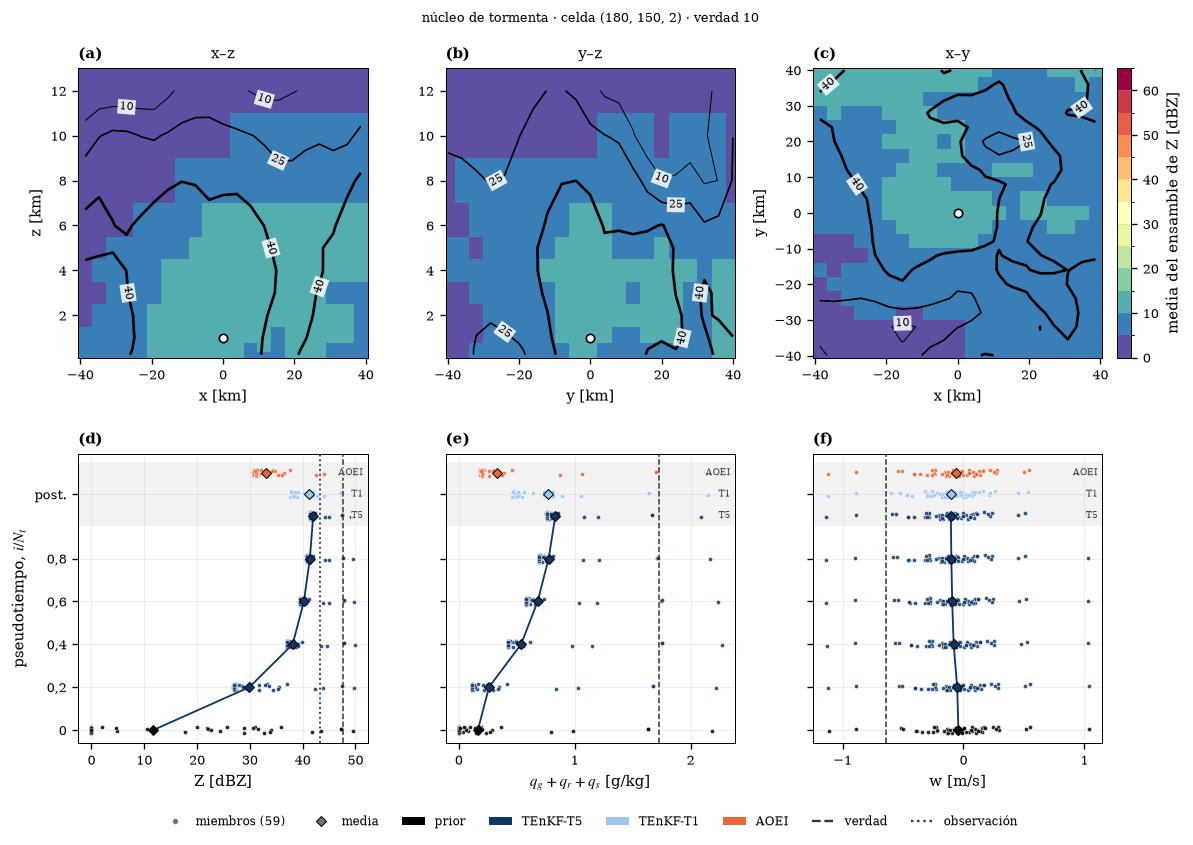

figures/es/N3s/points/edge/edge_190_160_4_tm01_A1.png  figures/en/N3s/points/edge/edge_190_160_4_tm01_A1.png


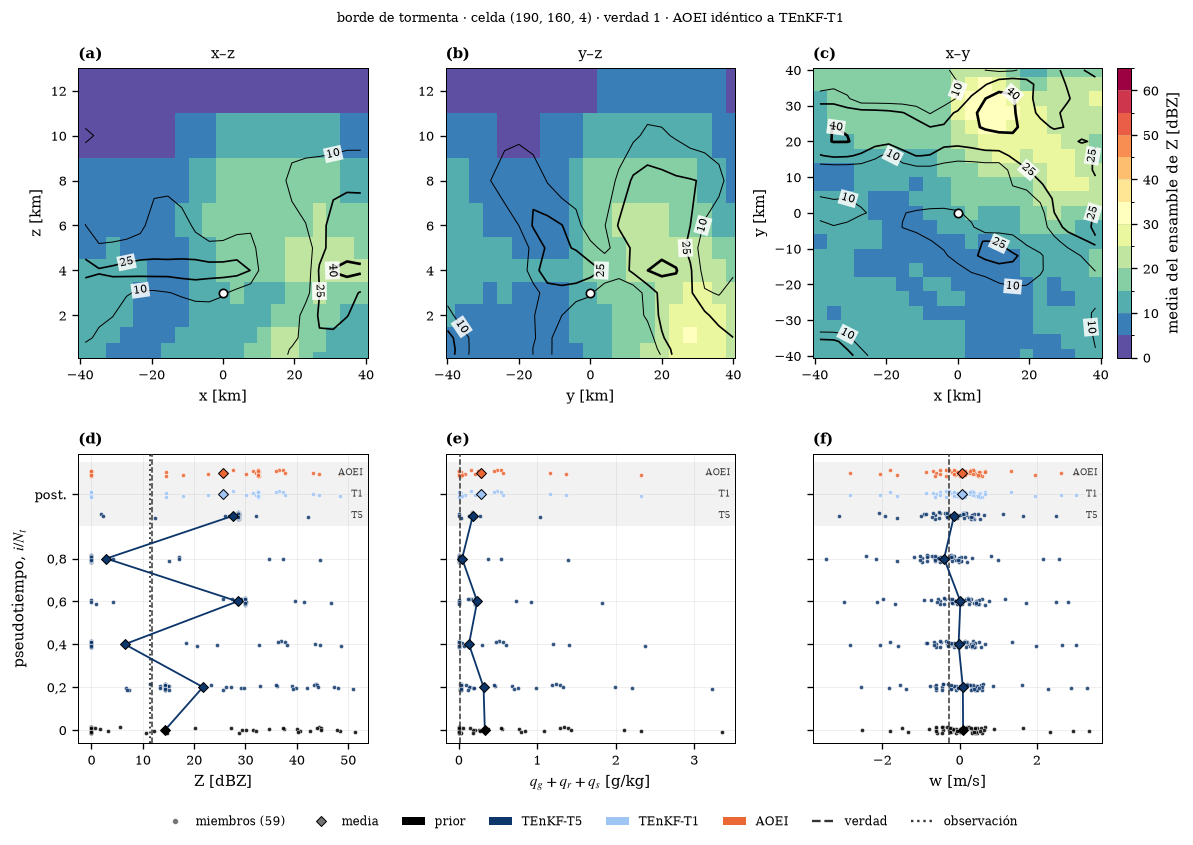

120 figuras _A1 en figures/<idioma>/N3s/points/, 56 s


In [27]:
JIT = 0.015                 # dispersión vertical de los puntos, solo visual
FLOOR_DEX = 0.8             # décadas entre la línea del piso (q < q_0) y q_0
BAND = "#f2f2f2"


def sci(x, lang):
    """x como a·10^b en mathtext, con coma decimal en español ({,}: sin el espacio que mathtext pone tras la coma)."""
    e = int(np.floor(np.log10(x)))
    return f"${nb.fmt(x / 10 ** e, lang, '.1f').replace(',', '{,}')}\\cdot10^{{{e}}}$"


def qlabel(P_, v, lang):
    """La etiqueta del eje de un hidrometeoro; con Q0_MODE = 'species' lleva su q_0."""
    return LABELS9[lang][v] if Q0_MODE == "single" else f"{LABELS9[lang][v]}, $q_0$ = {sci(q0_of(P_)[v], lang)}"


def q0_note():
    """Con Q0_MODE = 'single', el q_0 común, una vez en el título de la figura."""
    return f" · $q_0$ = $10^{{{int(np.log10(Q0_SINGLE))}}}$ g/kg" if Q0_MODE == "single" else ""


def save_all(draw, suffix):
    """Una figura por punto para los 60 puntos, en los dos idiomas, en
    figures/<idioma>/N3s/points/<condición>/<punto>_<suffix>.png; en línea, solo los puntos de ejemplo."""
    import contextlib, io, sys
    t0 = time.time()
    for r in SEL.itertuples(index=False):
        ex = point_name(r) in EX_POINTS
        with contextlib.redirect_stdout(sys.stdout if ex else io.StringIO()):      # las rutas, solo de los ejemplos
            nb.save(lambda lang, r=r: draw(lang, r), f"N3s/points/{r.condition}/{point_name(r)}_{suffix}",
                    show=SHOW if ex else False)
        if ex:
            plt.show()
    print(f"{len(nb.LANGS) * len(SEL)} figuras _{suffix} en figures/<idioma>/N3s/points/, {time.time() - t0:.0f} s")


def traj_panel(ax, P_, v, lang, log=False, colors=None, scheme_ticks=False):
    """v contra el pseudotiempo: los 59 miembros de cada etapa, su media, la verdad y (para Z) la observación.

    log=True (hidrometeoros): eje x logarítmico desde el umbral q_0 de la especie (Q0_MODE). Los miembros por
    debajo van en la línea del piso, FLOOR_DEX décadas a la izquierda, con su número al lado; la media y la
    verdad siguen la misma regla. colors: un color por miembro, y entonces las medias en negro.
    scheme_ticks: el eje y rotulado con las etapas en vez del pseudotiempo.
    """
    st = stages(P_)
    vals = [val(s["X"], s["Z"], v) for s in st]
    tru = float(val(P_["truth_point_state"], P_["yo_clean"], v))
    q0 = q0_of(P_)[v] if log else None
    floor = q0 / 10 ** FLOOR_DEX if log else None

    def place(x):
        x = np.asarray(x, float)
        return np.where(x < q0, floor, x) if log else x

    jit = np.random.default_rng(0).uniform(-JIT, JIT, NE)
    ax.axhspan(*POST_BAND, color=BAND, lw=0, zorder=0)
    for s, x in zip(st, vals):
        y, scol = s["y"], COL9[s["scheme"]]
        ax.scatter(place(x), y + jit, s=6, c=scol if colors is None else colors, edgecolors="white",
                   linewidths=0.3, alpha=0.85, zorder=2)
        if log and (x < q0).any():
            ax.annotate(f"{int((x < q0).sum())}", (floor, y), xytext=(4, 0), textcoords="offset points",
                        fontsize=5.5, va="center", color=scol if colors is None else "k")
        if colors is None:
            ax.plot(place(x.mean()), y, "D", ms=4.5, color=scol, mec="k", mew=0.6, zorder=5)
        else:
            ax.plot(place(x.mean()), y, "D", ms=4.5, color="k", mec="white", mew=0.6, zorder=5)
    # T5: del prior a su posterior en 1,0
    t5 = [(place(x.mean()), s["y"]) for s, x in zip(st, vals) if s["scheme"] in ("prior", "T5")]
    ax.plot(*zip(*t5), "-", lw=1.1, color=COL9["T5"] if colors is None else "k", zorder=4)
    ax.axvline(place(tru), color="0.2", ls="--", lw=0.9, zorder=3)
    if v == "Z":
        ax.axvline(float(P_["yo"]), color="0.2", ls=":", lw=1.1, zorder=3)
    for key, yb in Y_POST.items():          # el nombre de cada esquema dentro de la franja
        ax.text(0.985, yb, NAME9[key].replace("TEnKF-", ""), transform=ax.get_yaxis_transform(), ha="right",
                va="center", fontsize=5.5, color="0.25", zorder=6,
                bbox=dict(fc=BAND, ec="none", alpha=0.85, pad=0.4))
    ax.set_ylim(-0.06, 1.29)
    if scheme_ticks:
        ax.set_yticks(Y_TICKS, ["prior"] + [f"T5 · {i}/5" for i in range(1, 5)] + [LABELS9[lang]["post"]])
    else:
        ax.set_yticks(Y_TICKS, [f"{t:g}" for t in Y_TICKS[:-1]] + [LABELS9[lang]["post"]])
    if log:
        hi = max(max(float(x.max()) for x in vals), tru, 10 * q0)
        ax.set_xscale("log")
        ax.set_xlim(floor / 10 ** 0.35, hi * 2)
        ax.axvline(floor, color="0.55", lw=0.7, zorder=1)
        e_lo, e_hi = int(np.ceil(np.log10(q0))), int(np.floor(np.log10(hi * 2)))
        ax.set_xticks([floor] + [10.0 ** e for e in range(e_lo, e_hi + 1)],
                      [LABELS9[lang]["below"]] + [f"$10^{{{e}}}$" for e in range(e_lo, e_hi + 1)])
        ax.set_xticks([m * 10.0 ** e for e in range(e_lo - 1, e_hi + 1) for m in range(2, 10)
                       if q0 <= m * 10.0 ** e <= hi * 2], minor=True)
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())


def legend9(lang, obs=True):
    V, L9 = nb.VOCAB[lang], LABELS9[lang]
    h = [Line2D([], [], ls="", marker="o", ms=3.5, color="0.45", mec="white", mew=0.3, label=L9["members"]),
         Line2D([], [], ls="", marker="D", ms=4.5, color="0.45", mec="k", mew=0.6, label=L9["mean"])]
    h += [Patch(fc=COL9[k], ec="none", label=NAME9[k]) for k in ("prior", "T5", "T1", "AOEI")]
    h += [Line2D([], [], ls="--", color="0.2", label=V["truth"])]
    if obs:
        h += [Line2D([], [], ls=":", color="0.2", label=V["obs"])]
    return h


def draw_point_a1(lang, r):
    """La figura por punto de la sección 6 (draw_point) con la fila de abajo hecha con traj_panel."""
    L = LABELS[lang]
    fig = draw_point(lang, r)
    top, bottom = fig.axes[:3], fig.axes[3:6]
    assert len(fig.axes) == 7 and all(b.get_position().y1 < t.get_position().y0 for b, t in zip(bottom, top))
    for lg in list(fig.legends):
        lg.remove()
    for c, (ax, v) in enumerate(zip(bottom, TVARS)):
        ax.clear()
        traj_panel(ax, STEPS[point_name(r)], v, lang)
        ax.set_xlabel(L[v])
        if v != "Z":
            ax.locator_params(axis="x", nbins=4)
        if c == 0:
            ax.set_ylabel(L["ptime"])
        else:
            ax.tick_params(labelleft=False)          # el mismo eje que (d)
        ax.set_title(f"({'def'[c]})", loc="left", fontweight="bold")
    x_mid = (PT_ML + 1.5 * PT_SIDE + PT_GW) / PT_W
    fig.legend(handles=legend9(lang), loc="lower center", bbox_to_anchor=(x_mid, 0.0), ncol=8, frameon=False,
               fontsize=7)
    fig.suptitle(title_of(r, lang), x=x_mid, y=1 - 0.08 / PT_H, va="top", fontsize=8)
    return fig


save_all(draw_point_a1, "A1")

### 9.2 · Las nueve variables (A2)

La misma disposición para $Z$, $q_g$, $q_r$, $q_s$, $T$, $P$, $u$, $v$ y $w$. Los hidrometeoros, en eje logarítmico desde el umbral $q_0$ (`Q0_MODE`; su valor, en el título): los miembros por debajo van en la línea del piso, rotulada $< q_0$, con su número al lado. La media y la verdad siguen la misma regla.

figures/es/N3s/points/core/core_180_150_2_tm10_A2.png  figures/en/N3s/points/core/core_180_150_2_tm10_A2.png


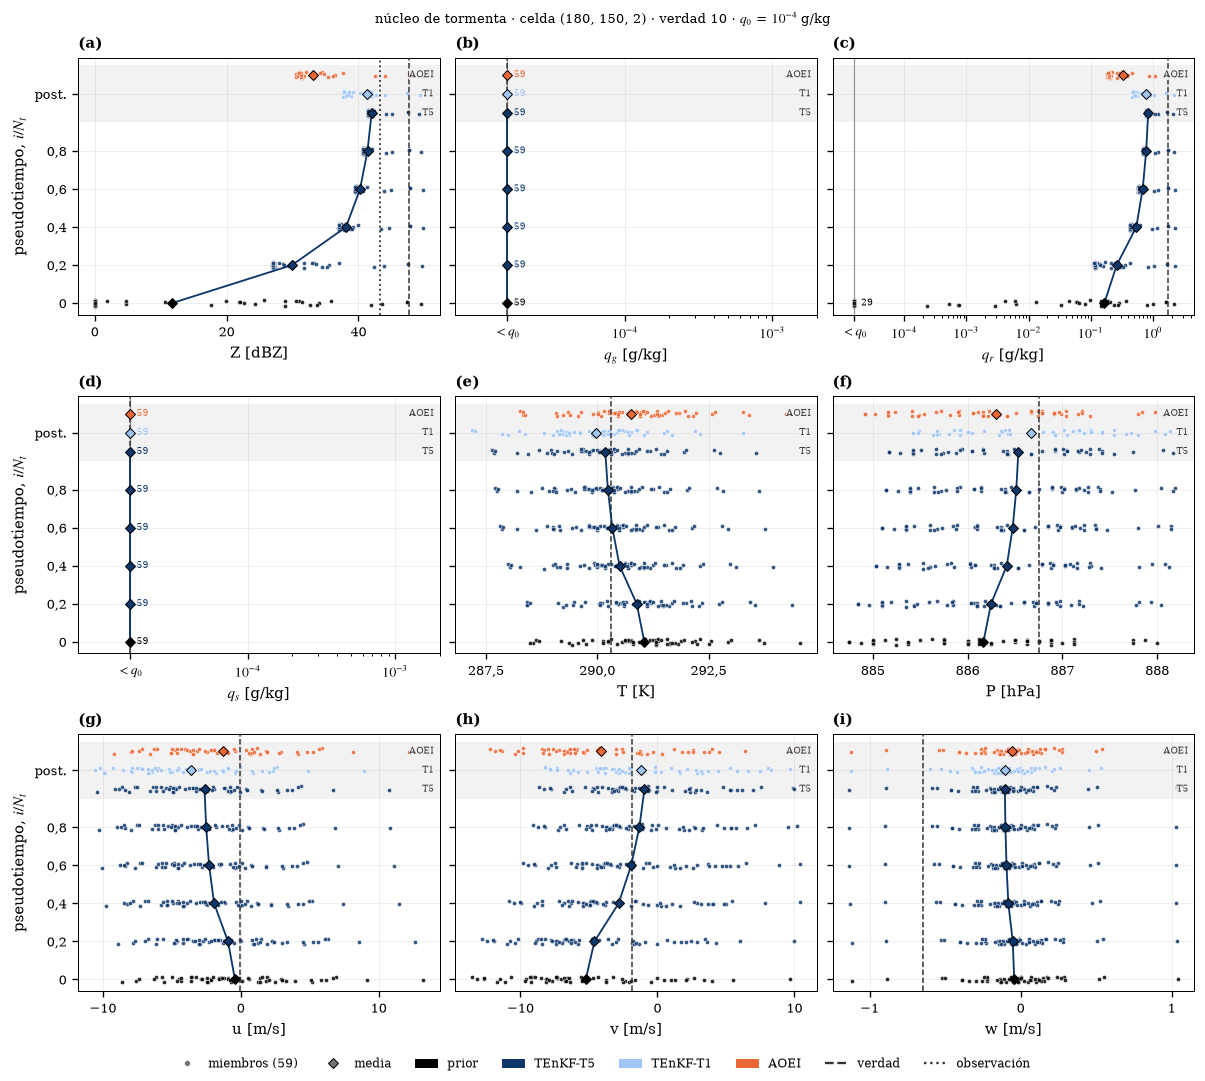

figures/es/N3s/points/edge/edge_190_160_4_tm01_A2.png  figures/en/N3s/points/edge/edge_190_160_4_tm01_A2.png


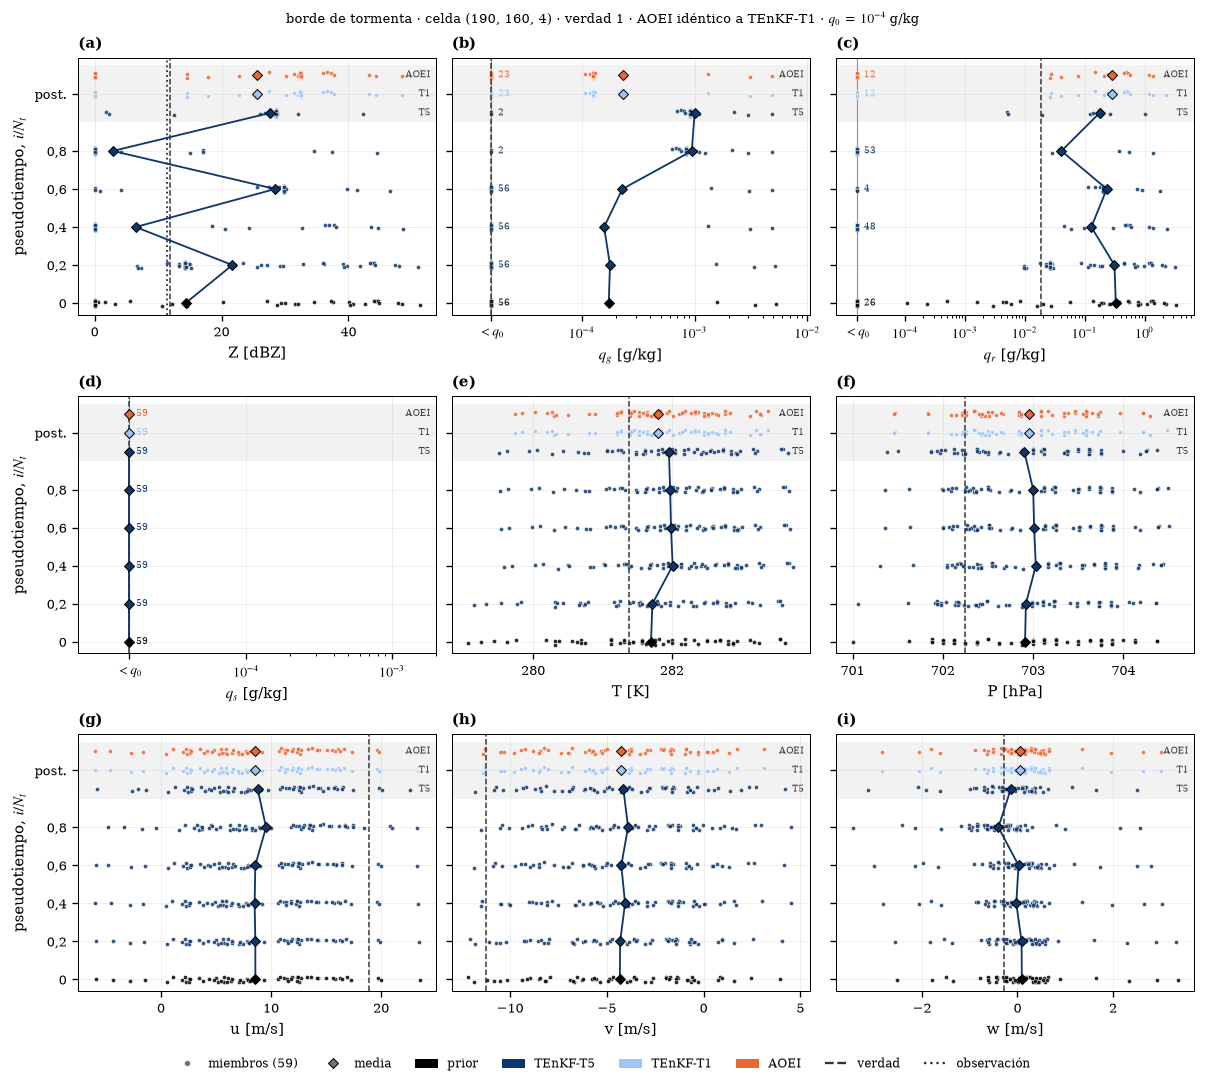

120 figuras _A2 en figures/<idioma>/N3s/points/, 87 s


In [28]:
A2_VARS = ("Z", "qg", "qr", "qs", "T", "P", "u", "v", "w")


def draw_vars_a2(lang, r):
    L, L9 = LABELS[lang], LABELS9[lang]
    P_ = STEPS[point_name(r)]
    fig, axes = plt.subplots(3, 3, figsize=(nb.PAGE_W * 1.45, nb.PAGE_W * 1.3), sharey=True,
                             constrained_layout=True)
    for q, (ax, v) in enumerate(zip(axes.flat, A2_VARS)):
        log = v in nb.HYDRO
        traj_panel(ax, P_, v, lang, log=log)
        ax.set_xlabel(qlabel(P_, v, lang) if log else (L[v] if v in ("Z", "w") else L9[v]))
        if not log:
            ax.locator_params(axis="x", nbins=4)
        ax.set_title(f"({'abcdefghi'[q]})", loc="left", fontweight="bold")
    for ax in axes[:, 0]:
        ax.set_ylabel(L["ptime"])
    fig.legend(handles=legend9(lang), loc="outside lower center", ncol=8, frameon=False, fontsize=7)
    fig.suptitle(title_of(r, lang) + q0_note(), fontsize=8)
    return fig


save_all(draw_vars_a2, "A2")

### 9.3 · Control de la reflectividad (A3)

En cada etapa, $h(\mathbf{x})$ recalculado del $q$ y la $T$ guardados con el operador de producción (`run_experiment._calc_hx_domain`, que llama al Fortran `calc_ref_ens`, como `StepRecorder`) y con el de NumPy (`nb.hx`), contra la $Z$ guardada. Después, $Z$ separada en $Z_r$, $Z_s$ y $Z_g$: el mismo operador con una sola especie y sin piso. La nieve va por la rama seca si $T \le$ 273,16 K y por la húmeda si no, con la $T$ de cada miembro. Para cada etapa: en cuántos miembros con $Z > 0$ domina cada especie, la mediana de cada $Z_x$ sobre los miembros con eco que tienen esa especie, cuántos miembros tienen nieve y cuántos de ellos van por la rama húmeda, y la $T$ de los miembros en la celda. La fila «verdad» es la del miembro verdad.

In [29]:
def hx_prod(X):
    """h(x) de producción de los miembros en la celda: _calc_hx_domain sobre un estado (1, 1, 1, n, 8)."""
    return rx._calc_hx_domain(np.asarray(X, np.float32).reshape(1, 1, 1, -1, 8), VAR_IDX, dbz_min=DBZ_MIN)[0, 0, 0]


def hx_species(X):
    """Z_r, Z_s y Z_g [dBZ] de cada miembro, (3, n): el operador de producción con una sola especie y sin
    piso; −inf donde la especie es 0."""
    out = []
    for spec in ("qr", "qs", "qg"):
        Xs = np.array(X, np.float32).reshape(-1, 8)
        for other in set(nb.HYDRO) - {spec}:
            Xs[:, nb.VI[other]] = 0.0
        z = rx._calc_hx_domain(Xs.reshape(1, 1, 1, -1, 8), VAR_IDX, dbz_min=-1e30)[0, 0, 0].astype(float)
        out.append(np.where(z <= -1e29, -np.inf, z))
    return np.array(out)


SPEC = ("r", "s", "g")
rows = []
for p in EX_POINTS:
    P_ = STEPS[p]
    for s in stages(P_):
        Zst = np.asarray(s["Z"], np.float32)
        Zc = hx_species(s["X"])
        with np.errstate(divide="ignore"):
            z_sum = 10 * np.log10((10.0 ** (Zc / 10)).sum(0))          # sin piso
        echo = Zst > DBZ_MIN
        rows.append(dict(point=p, etapa=s["key"], N_Z0=int(echo.sum()),
                         fortran=float(np.abs(hx_prod(s["X"]) - Zst).max()),
                         numpy=float(np.abs(nb.hx(s["X"], min_dbz=DBZ_MIN).astype(np.float32) - Zst).max()),
                         suma_especies=float(np.abs(z_sum[echo] - Zst[echo]).max()) if echo.any() else np.nan))
HXC = pd.DataFrame(rows)
print("max |h(x) recalculado − Z guardada| [dBZ], por etapa; 'suma_especies': 10 log10(z_r + z_s + z_g) contra "
      "Z en los miembros con eco")
print(HXC.pivot(index="etapa", columns="point", values=["fortran", "numpy", "suma_especies"])
      .reindex([s["key"] for s in stages(STEPS[EX_CORE])]).to_string(float_format=lambda v: f"{v:.1e}"))
assert (HXC.fortran == 0).all(), "el operador de producción no reproduce la Z guardada"

max |h(x) recalculado − Z guardada| [dBZ], por etapa; 'suma_especies': 10 log10(z_r + z_s + z_g) contra Z en los miembros con eco
                  fortran                                   numpy                           suma_especies                    
point core_180_150_2_tm10 edge_190_160_4_tm01 core_180_150_2_tm10 edge_190_160_4_tm01 core_180_150_2_tm10 edge_190_160_4_tm01
etapa                                                                                                                        
prior             0.0e+00             0.0e+00             0.0e+00             0.0e+00             2.3e-07             2.4e-06
T5_1              0.0e+00             0.0e+00             0.0e+00             0.0e+00             1.2e-06             3.1e-06
T5_2              0.0e+00             0.0e+00             0.0e+00             0.0e+00             9.3e-08             1.6e-06
T5_3              0.0e+00             0.0e+00             0.0e+00             0.0e+00             5.3e-08         

In [30]:
T_WET = 273.16      # K: la rama de la nieve del operador (seca si T <= T_WET)


def decompose(X, Zv):
    X = np.asarray(X, np.float64).reshape(-1, 8)
    Zv = np.atleast_1d(np.asarray(Zv, np.float32))
    Zc = hx_species(X)
    echo = Zv > DBZ_MIN
    dom = np.argmax(Zc, axis=0)
    qs, T_ = X[:, nb.VI["qs"]], X[:, nb.VI["T"]]
    row = {"N_Z>0": int(echo.sum())}
    row |= {f"domina {sp}": int((echo & (dom == q)).sum()) for q, sp in enumerate(SPEC)}
    for q, sp in enumerate(SPEC):
        x = Zc[q][echo & np.isfinite(Zc[q])]
        row[f"Z_{sp} mediana"] = float(np.median(x)) if x.size else np.nan
    row |= {"con nieve": int((qs > 0).sum()), "nieve húmeda": int(((qs > 0) & (T_ > T_WET)).sum()),
            "T mín": T_.min(), "T media": T_.mean(), "T máx": T_.max()}
    return row


for p in EX_POINTS:
    P_ = STEPS[p]
    tab = {s["key"]: decompose(s["X"], s["Z"]) for s in stages(P_)}
    tab["verdad"] = decompose(P_["truth_point_state"], P_["yo_clean"])
    t_ = P_["truth_point_state"]
    Zc_t = hx_species(t_)[:, 0]
    print(f"\n{p}: Z verdad {float(P_['yo_clean']):.2f} dBZ = Z_r {Zc_t[0]:.2f}, Z_s {Zc_t[1]:.2f}, Z_g {Zc_t[2]:.2f} dBZ; "
          f"T verdad {t_[nb.VI['T']]:.2f} K (rama de la nieve: {'húmeda' if t_[nb.VI['T']] > T_WET else 'seca'})")
    print("Z_x [dBZ]: mediana sobre los miembros con eco que tienen la especie; T [K] de los 59 miembros")
    tab = pd.DataFrame(tab).T
    ints = [c for c in tab if not c.startswith(("Z_", "T "))]
    print(tab.astype({c: int for c in ints}).to_string(float_format=lambda v: f"{v:.2f}", na_rep="—"))


core_180_150_2_tm10: Z verdad 47.72 dBZ = Z_r 47.72, Z_s -60.38, Z_g -98.07 dBZ; T verdad 290.31 K (rama de la nieve: húmeda)
Z_x [dBZ]: mediana sobre los miembros con eco que tienen la especie; T [K] de los 59 miembros
        N_Z>0  domina r  domina s  domina g  Z_r mediana  Z_s mediana  Z_g mediana  con nieve  nieve húmeda  T mín  T media  T máx
prior      25        25         0         0        28.80       -84.14       -73.32         29            29 288.50   291.06 294.56
T5_1       59        59         0         0        27.10       -53.70       -67.06         13            13 288.42   290.89 294.37
T5_2       59        59         0         0        37.05       -52.56       -63.57         12            12 287.99   290.50 293.94
T5_3       59        59         0         0        39.48       -55.38       -66.46         15            15 287.81   290.34 293.76
T5_4       59        59         0         0        40.76       -55.73       -64.27         15            15 287.70   290.24 

### 9.4 · Los miembros en el plano ($Z$, $w$) (A4)

Un panel por etapa: el prior, los pasos 1 a 4 de TEnKF-T5 y los tres posteriores (T5, que es su paso 5; T1; AOEI). Llenos, los miembros con $Z > 0$; huecos, los que están en el límite de detección ($Z$ = 0 dBZ). Rombo: la media; estrella: la verdad; línea de puntos: la observación. En cada panel, corr($Z$, $w$) de los 59 miembros. Con una sola observación, el paso siguiente mueve la media de $w$ en $\mathrm{cov}(w, Z)/\sigma_Z^2$ veces el incremento lineal de $Z$ ($K d$), con la covarianza de este ensamble: el signo de la correlación de un panel es el del incremento de $w$ respecto del de $Z$ en el paso que sigue.

figures/es/N3s/points/core/core_180_150_2_tm10_A4.png  figures/en/N3s/points/core/core_180_150_2_tm10_A4.png


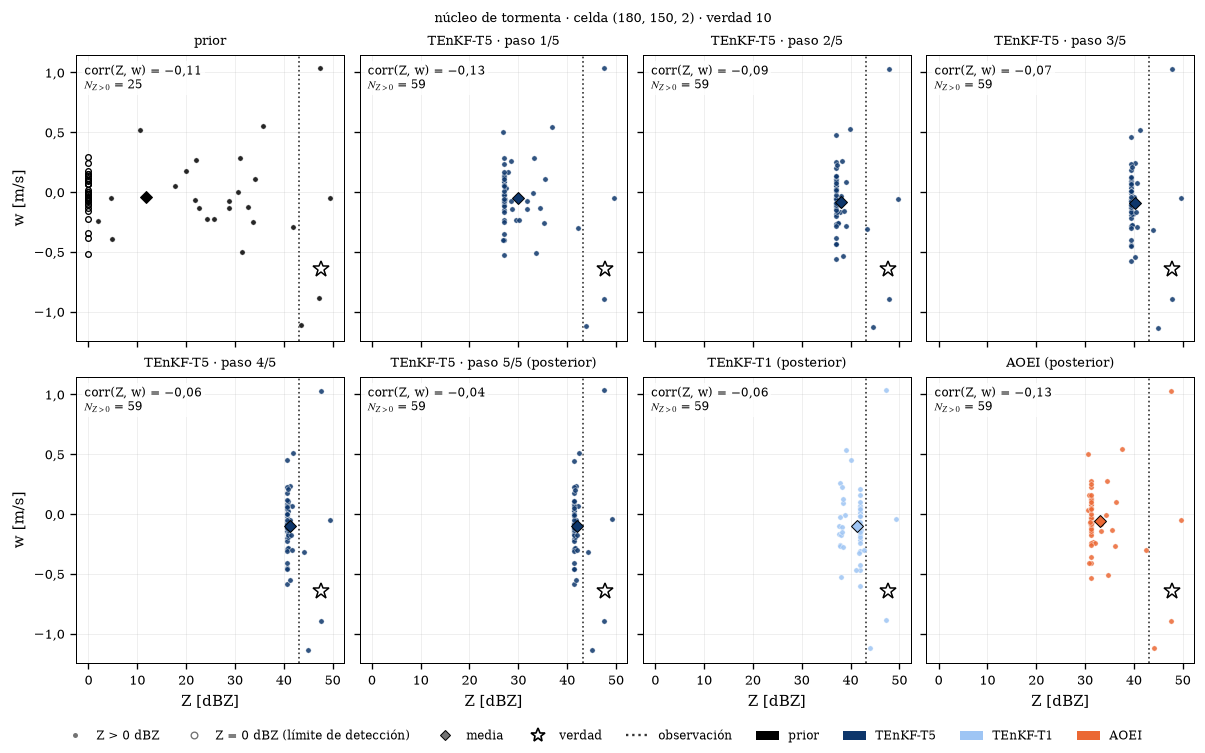

figures/es/N3s/points/edge/edge_190_160_4_tm01_A4.png  figures/en/N3s/points/edge/edge_190_160_4_tm01_A4.png


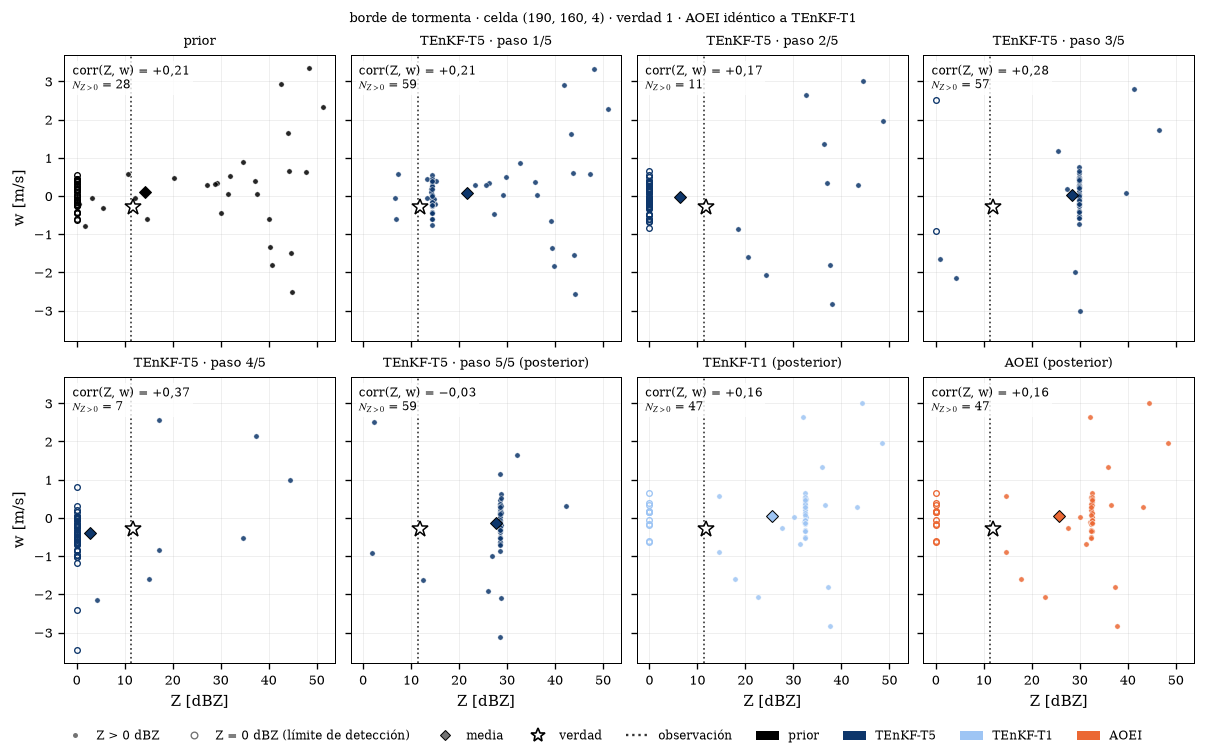

120 figuras _A4 en figures/<idioma>/N3s/points/, 61 s


In [31]:
A4_ORDER = ("prior", "T5_1", "T5_2", "T5_3", "T5_4", "T5_5", "T1", "AOEI")


def draw_zw_a4(lang, r):
    V, L, L9 = nb.VOCAB[lang], LABELS[lang], LABELS9[lang]
    P_ = STEPS[point_name(r)]
    st = {s["key"]: s for s in stages(P_)}
    zt, wt = float(P_["yo_clean"]), float(P_["truth_point_state"][nb.VI["w"]])
    fig, axes = plt.subplots(2, 4, figsize=(nb.PAGE_W * 1.45, nb.PAGE_W * 0.9), sharex=True, sharey=True,
                             constrained_layout=True)
    for ax, key in zip(axes.flat, A4_ORDER):
        s = st[key]
        col = COL9[s["scheme"]]
        Zs, ws = val(s["X"], s["Z"], "Z"), val(s["X"], s["Z"], "w")
        at0 = Zs <= DBZ_MIN
        ax.plot(Zs[~at0], ws[~at0], "o", ms=3.2, color=col, mec="white", mew=0.3, alpha=0.85, zorder=2)
        ax.plot(Zs[at0], ws[at0], "o", ms=3.4, mfc="none", mec=col, mew=0.8, zorder=2)
        ax.plot(Zs.mean(), ws.mean(), "D", ms=5, color=col, mec="k", mew=0.6, zorder=5)
        ax.plot(zt, wt, "*", ms=10, mfc="white", mec="k", mew=0.9, zorder=6)
        ax.axvline(float(P_["yo"]), color="0.2", ls=":", lw=1.0, zorder=1)
        rho = corr(Zs, ws)
        txt = L9["undef"] if np.isnan(rho) else nb.fmt(rho, lang, "+.2f")
        ax.text(0.03, 0.97, f"corr(Z, w) = {txt}\n$N_{{Z>0}}$ = {int((~at0).sum())}", transform=ax.transAxes,
                va="top", ha="left", fontsize=7, bbox=dict(fc="white", ec="none", alpha=0.8, pad=1.5))
        ax.set_title(stage_title(key, lang), fontsize=7.5)
    for ax in axes[-1]:
        ax.set_xlabel(L["Z"])
    for ax in axes[:, 0]:
        ax.set_ylabel(L["w"])
    h = [Line2D([], [], ls="", marker="o", ms=4, color="0.45", mec="white", label=L9["Zpos"]),
         Line2D([], [], ls="", marker="o", ms=4, mfc="none", mec="0.45", mew=0.8, label=L9["Z0"]),
         Line2D([], [], ls="", marker="D", ms=4.5, color="0.45", mec="k", mew=0.6, label=L9["mean"]),
         Line2D([], [], ls="", marker="*", ms=9, mfc="white", mec="k", label=V["truth"]),
         Line2D([], [], ls=":", color="0.2", label=V["obs"])]
    h += [Patch(fc=COL9[k], ec="none", label=NAME9[k]) for k in ("prior", "T5", "T1", "AOEI")]
    fig.legend(handles=h, loc="outside lower center", ncol=9, frameon=False, fontsize=7)
    fig.suptitle(title_of(r, lang), fontsize=8)
    return fig


save_all(draw_zw_a4, "A4")

### 9.5 · $w$ de la verdad en los pares elegibles (B1) y el signo físico de corr($Z$, $w$) (B2)

Dataset A (4 km–5 min), las cuatro horas. Cada hora se carga sola (el subset ocupa unos 3 GB en memoria) y se procesa como en la sección 1: $Z$ con `nb.hx`, pares elegibles los que tienen al menos un miembro del prior con $Z > 0$ dBZ, en celdas finitas. A las 20 UTC se exige que salgan los mismos $Z$, $w$ y pares elegibles que en la sección 1.

- **B1.** Cuántos pares elegibles tienen $w_t \ge$ 5, 10, 15 y 20 m/s, y $w_t \le$ −5, −10, −15 y −20 m/s: por hora y por nivel, en todas las celdas y solo en las del barrido (`stride` 10).
- **B2.** En el campo de cada uno de los 60 miembros (cada uno es la verdad de algún experimento), la correlación espacial entre $Z$ y $w$ en cada nivel, sobre las celdas de tormenta ($Z \ge$ 20 dBZ, celda a celda; no son las columnas de `domain_masks`) y sobre todas las celdas con $Z > 0$. Media y dispersión sobre los 60 miembros. El perfil de las 20 UTC sobre $Z > 0$ es la referencia de signo de la sección 9.6.

In [32]:
W_THR = (5, 10, 15, 20)           # m/s
B_HOURS = nb.N2_HOURS
SWEEP2D = SWEEP_CELL[:, :, 0, 0]


def hour_fields(hour):
    """Z (nb.hx), w, pares elegibles y celdas finitas de una hora, con los pasos de la sección 1."""
    p = nb.subset_path(hour, S_DS)
    nb.assert_dataset(p, S_DS)
    dbz_min = nb.dbz_min_of(f"WS_{S_DS}_sweep_{hour}00_LOC0.1_ALLMEM")
    with np.load(p) as f:
        ens = f["state_ensemble"]
    assert ens.shape == ENS.shape
    z = np.empty(ens.shape[:4], np.float32)
    for i0 in range(0, ens.shape[0], 32):
        z[i0:i0 + 32] = nb.hx(ens[i0:i0 + 32], min_dbz=dbz_min)
    w = ens[..., nb.VI["w"]].copy()
    finite = np.isfinite(ens).all(axis=(3, 4))
    del ens
    echo = z > dbz_min
    n_echo = (echo.sum(axis=3, dtype=np.int16)[..., None] - echo).astype(np.int16)
    return z, w, (n_echo >= 1) & finite[..., None], finite, dbz_min


t0 = time.time()
rows_w, rows_c = [], []
for hour in B_HOURS:
    z, w, elig, finite, dbz_min = hour_fields(hour)
    if hour == S_HOUR:
        assert np.array_equal(elig, ELIG) and np.array_equal(z, Z, equal_nan=True) \
            and np.array_equal(w, W, equal_nan=True), "no reproduce la sección 1"
    for k in range(NZ):
        wk, ek = w[:, :, k], elig[:, :, k]
        for cells, sel in (("todas", ek), ("barrido", ek & SWEEP2D[:, :, None])):
            x = wk[sel]
            row = dict(hora=hour, k=k, celdas=cells, pares=x.size, w_max=x.max(), w_min=x.min())
            row |= {f"≥{t}": int((x >= t).sum()) for t in W_THR}
            row |= {f"≤−{t}": int((x <= -t).sum()) for t in W_THR}
            rows_w.append(row)
        # B2: correlación espacial de Z y w de cada miembro en el nivel k
        zk, wk64, fin = z[:, :, k].astype(np.float64), wk.astype(np.float64), finite[:, :, k][..., None]
        for dom, M in (("Z ≥ 20", fin & (zk >= nb.STORM_THRESH_DBZ)), ("Z > 0", fin & (zk > dbz_min))):
            n = M.sum((0, 1))
            with np.errstate(invalid="ignore", divide="ignore"):
                dz = np.where(M, zk - np.where(M, zk, 0).sum((0, 1)) / n, 0.0)
                dw = np.where(M, wk64 - np.where(M, wk64, 0).sum((0, 1)) / n, 0.0)
                rho = (dz * dw).sum((0, 1)) / np.sqrt((dz ** 2).sum((0, 1)) * (dw ** 2).sum((0, 1)))
            rows_c += [dict(hora=hour, k=k, dominio=dom, m=m, celdas=int(n[m]), corr=float(rho[m])) for m in range(NM)]
    del z, w, elig, finite
    print(f"{hour} UTC listo, {time.time() - t0:.0f} s")
BW, BC = pd.DataFrame(rows_w), pd.DataFrame(rows_c)
assert nb.STORM_THRESH_DBZ == 20.0

18 UTC listo, 21 s
19 UTC listo, 43 s
20 UTC listo, 65 s
21 UTC listo, 88 s


In [33]:
THR_COLS = [f"≥{t}" for t in W_THR] + [f"≤−{t}" for t in W_THR]
LEV = pd.Series(Z_LEV, name="z [km]")


def w_table(df, by):
    t = df.groupby(by, sort=False).agg(pares=("pares", "sum"), **{c: (c, "sum") for c in THR_COLS},
                                       w_max=("w_max", "max"), w_min=("w_min", "min"))
    return t


for cells, name in (("todas", "todas las celdas"), ("barrido", "celdas del barrido (stride 10)")):
    d = BW[BW.celdas == cells]
    t = w_table(d, "hora")
    t.loc["4 h"] = w_table(d.assign(hora="4 h"), "hora").iloc[0]
    t = t.astype({c: int for c in ["pares", *THR_COLS]})
    print(f"\nB1 · pares elegibles por umbral de w_t [m/s], {name}")
    print(t.to_string(float_format=lambda v: f"{v:.1f}"))
for hours, hname in (([S_HOUR], f"{S_HOUR} UTC"), (list(B_HOURS), "las 4 horas")):
    for cells, name in (("todas", "todas las celdas"), ("barrido", "celdas del barrido")):
        d = BW[(BW.celdas == cells) & BW.hora.isin(hours)]
        t = w_table(d, "k")
        t.insert(0, "z [km]", LEV.loc[t.index].to_numpy())
        print(f"\nB1 · por nivel, {hname}, {name}")
        print(t.to_string(float_format=lambda v: f"{v:.1f}"))


B1 · pares elegibles por umbral de w_t [m/s], todas las celdas
          pares      ≥5    ≥10    ≥15   ≥20   ≤−5  ≤−10  ≤−15  ≤−20  w_max  w_min
hora                                                                             
18     49780901   38470  10435   3537  1352  1313     0     0     0   48.8   -9.9
19     52520042   47643  13085   4392  1616  1687     2     0     0   44.9  -11.6
20     55214640   50783  13891   4725  1711  2164    12     0     0   57.4  -14.8
21     56023121   57441  15468   5218  1845  2221     6     0     0   45.5  -11.7
4 h   213538704  194337  52879  17872  6524  7385    20     0     0   57.4  -14.8

B1 · pares elegibles por umbral de w_t [m/s], celdas del barrido (stride 10)
        pares    ≥5  ≥10  ≥15  ≥20  ≤−5  ≤−10  ≤−15  ≤−20  w_max  w_min
hora                                                                   
18     509438   356  121   43   18   15     0     0     0   33.7   -8.0
19     539179   477  144   57   24   21     0     0     0   40.8   -

In [34]:
def corr_table(df):
    g = df.groupby(["k", "dominio"], sort=False)
    t = g.agg(celdas_mediana=("celdas", "median"), media=("corr", "mean"), desv=("corr", "std"),
              mín=("corr", "min"), P10=("corr", lambda v: v.quantile(0.1)), P90=("corr", lambda v: v.quantile(0.9)),
              máx=("corr", "max"), miembros=("corr", "count"))
    t["celdas_mediana"] = t.celdas_mediana.round().astype(int)
    t = t.unstack("dominio")
    t = t.reorder_levels([1, 0], axis=1)[["Z ≥ 20", "Z > 0"]]
    t.insert(0, "z [km]", LEV.loc[t.index].to_numpy())
    return t


print(f"B2 · corr(Z, w) espacial en el campo de cada miembro, {S_HOUR} UTC: sobre los 60 miembros "
      "(miembros = los que tienen al menos 2 celdas en el dominio)")
print(corr_table(BC[BC.hora == S_HOUR]).to_string(float_format=lambda v: f"{v:.2f}"))
print("\nB2 · media sobre los miembros de corr(Z, w), por hora")
print(BC.pivot_table(index="k", columns=["dominio", "hora"], values="corr", aggfunc="mean")[["Z ≥ 20", "Z > 0"]]
      .to_string(float_format=lambda v: f"{v:+.2f}"))

B2 · corr(Z, w) espacial en el campo de cada miembro, 20 UTC: sobre los 60 miembros (miembros = los que tienen al menos 2 celdas en el dominio)
dominio z [km]         Z ≥ 20                                                      Z > 0                                            
               celdas_mediana media desv   mín   P10   P90   máx miembros celdas_mediana media desv   mín   P10   P90   máx miembros
k                                                                                                                                   
0         0.25           4155 -0.23 0.04 -0.33 -0.27 -0.17 -0.13       60           8820 -0.18 0.03 -0.27 -0.23 -0.14 -0.11       60
1         0.50           4374 -0.21 0.04 -0.33 -0.26 -0.16 -0.11       60           9320 -0.17 0.04 -0.26 -0.21 -0.13 -0.10       60
2         1.00           4762 -0.14 0.05 -0.27 -0.21 -0.08 -0.03       60          10334 -0.11 0.04 -0.21 -0.15 -0.04 -0.01       60
3         2.00           4779  0.01 0.06 -0.14 -0.06  0.08

### 9.6 · corr($Z$, $w$) en los diez puntos de cada condición (A5)

Un panel por condición. Filas: sus 10 puntos, de la celda más alta a la más baja, con su altura; columnas: el prior, los pasos 1 a 5 de TEnKF-T5 (5/5 es su posterior) y los posteriores de TEnKF-T1 y AOEI. Gris: correlación no definida ($Z$ igual en los 59 miembros). En cada fila, $N_{Z>0}$ del prior; ▸ marca los puntos de ejemplo. Un recuadro en la columna del prior marca las filas cuyo signo es el opuesto al del perfil de la verdad a esa altura (B2, 20 UTC, celdas con $Z > 0$: negativo por debajo de unos 2 km, positivo por encima); donde el perfil está entre −`PROFILE_TOL` y `PROFILE_TOL` no tiene signo y no se marca.

corr(Z, w) de los 59 miembros en la celda observada; 'perfil': B2 a la altura del punto
condition                     point   z_km  N_prior  perfil  prior  T5_1  T5_2  T5_3  T5_4  T5_5    T1  AOEI  opuesto
     core       core_140_380_8_tm06  +8.00        5   +0.34  -0.18 -0.31 -0.47 -0.49 -0.49 -0.49 -0.75 -0.28     True
     core       core_120_370_8_tm47  +8.00        7   +0.34  +0.03 +0.02 -0.10 -0.13 -0.15 -0.16 -0.33 +0.02    False
     core       core_150_370_7_tm40  +6.00        9   +0.27  -0.57 -0.54 -0.42 -0.38 -0.34 -0.32 +0.03 -0.55     True
     core       core_160_310_7_tm23  +6.00       13   +0.27  +0.22 +0.29 +0.37 +0.40 +0.43 +0.45 +0.48 +0.27    False
     core       core_210_180_6_tm48  +5.00       59   +0.20  +0.31 +0.31 +0.28 +0.25 +0.22 +0.20 +0.16 +0.23    False
     core       core_170_420_6_tm25  +5.00        7   +0.20  -0.19 +0.08 +0.16 -0.00 +0.18 -0.07 -0.08 -0.06     True
     core       core_150_350_3_tm08  +2.00       13   +0.03  -0.12 -0.19 -0.24 -0.25 -

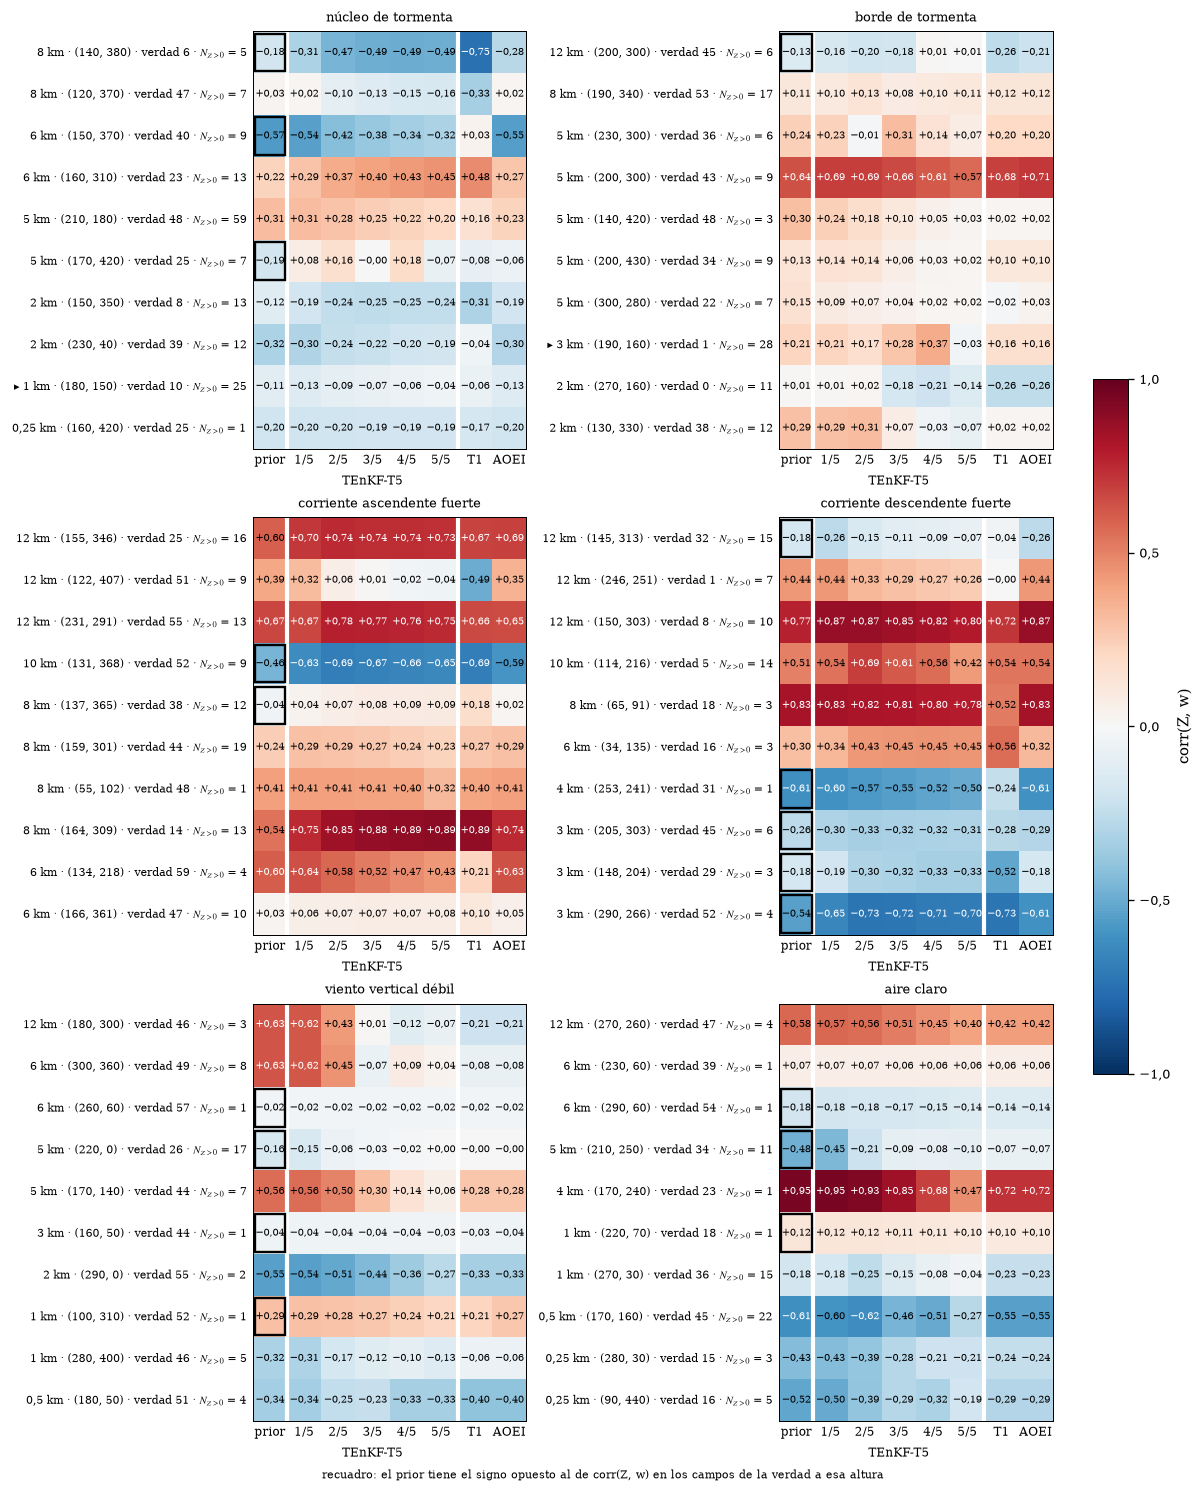

In [35]:
A5_COLS = ("prior", "T5_1", "T5_2", "T5_3", "T5_4", "T5_5", "T1", "AOEI")
PROFILE = BC[(BC.hora == S_HOUR) & (BC.dominio == "Z > 0")].groupby("k")["corr"].mean()   # B2
PROFILE_TOL = 0.05
rows = []
for r in SEL.itertuples(index=False):
    st = {s["key"]: s for s in stages(STEPS[point_name(r)])}
    row = dict(condition=r.condition, point=point_name(r), z_km=float(POS[r.i, r.j, r.k, 2]),
               N_prior=int((st["prior"]["Z"] > DBZ_MIN).sum()), perfil=float(PROFILE[r.k]))
    row |= {k: corr(val(st[k]["X"], st[k]["Z"], "Z"), val(st[k]["X"], st[k]["Z"], "w")) for k in A5_COLS}
    rows.append(row)
CZW = pd.DataFrame(rows)
CZW["opuesto"] = (CZW.perfil.abs() >= PROFILE_TOL) & (np.sign(CZW.prior) == -np.sign(CZW.perfil))
CZW = CZW.sort_values(["condition", "z_km"], ascending=[True, False],
                      key=lambda s: s.map({c: q for q, c in enumerate(CONDITIONS)}) if s.name == "condition" else s,
                      kind="stable", ignore_index=True)
print("corr(Z, w) de los 59 miembros en la celda observada; 'perfil': B2 a la altura del punto")
print(CZW.to_string(index=False, float_format=lambda v: f"{v:+.2f}"))
print("\nprior con el signo opuesto al perfil:", ", ".join(f"{c} {int(g.opuesto.sum())}/{len(g)}"
                                                       for c, g in CZW.groupby("condition", sort=False)))
print("prior sin correlación definida:", ", ".join(f"{c} {int(g.prior.isna().sum())}/{len(g)}"
                                                  for c, g in CZW.groupby("condition", sort=False)))


def draw_corr_a5(lang):
    V, L, L9 = nb.VOCAB[lang], LABELS[lang], LABELS9[lang]
    fig, axes = plt.subplots(3, 2, figsize=(nb.PAGE_W * 1.45, nb.PAGE_W * 1.8), constrained_layout=True)
    cmap = plt.get_cmap(nb.CMAP_DIV).copy()
    cmap.set_bad("#d4d4d4")
    for ax, c in zip(axes.flat, CONDITIONS):
        g = CZW[CZW.condition == c]
        M = g[list(A5_COLS)].to_numpy(float)
        im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
        for (q, k), x in np.ndenumerate(M):
            ax.text(k, q, "—" if np.isnan(x) else nb.fmt(x, lang, "+.2f"), ha="center", va="center", fontsize=6,
                    color="white" if abs(x) > 0.6 else "k")
        for q, opp in enumerate(g.opuesto):
            if opp:
                ax.add_patch(Rectangle((-0.45, q - 0.45), 0.9, 0.9, fill=False, ec="k", lw=1.4, zorder=5))
        labels = []
        for r in g.itertuples(index=False):
            s = PT[r.point]
            mark = "▸ " if r.point in EX_POINTS else ""
            labels.append(f"{mark}{nb.fmt(r.z_km, lang, 'g')} km · ({s.i}, {s.j}) · {V['truth']} {s.m} · "
                          f"$N_{{Z>0}}$ = {r.N_prior}")
        ax.set_yticks(range(len(g)), labels, fontsize=6.5)
        ax.set_xticks(range(len(A5_COLS)), ["prior", "1/5", "2/5", "3/5", "4/5", "5/5", "T1", "AOEI"], fontsize=7)
        ax.annotate("TEnKF-T5", xy=(3.0, 0.0), xycoords=("data", "axes fraction"), xytext=(0, -16),
                    textcoords="offset points", ha="center", va="top", fontsize=7)
        for xb in (0.5, 5.5):
            ax.axvline(xb, color="white", lw=2.5)
        ax.set_title(L[f"cond_{c}"], fontsize=8)
        ax.tick_params(length=0)
        ax.grid(False)
    fig.colorbar(im, ax=axes, label="corr(Z, w)", shrink=0.5, ticks=[-1, -0.5, 0, 0.5, 1])
    fig.supxlabel(L9["sign_box"], fontsize=6.5)
    return fig


nb.save(draw_corr_a5, "N3s/A5_corr_Z_w", show=SHOW)
plt.show()

### 9.7 · Los miembros por física (A6)

Los paneles $Z$, $q_g$, $q_r$ y $q_s$ de A2 (los mismos ejes) con cada miembro coloreado por su configuración física, la namelist $m \bmod 6 + 1$ (la convención de N3; los subsets no guardan la física de cada miembro): azules para WSM6 (1–3), naranjas para Lin (4–6). Los esquemas se reconocen solo por la posición en el pseudotiempo, rotulada; las medias van en negro.

figures/es/N3s/points/core/core_180_150_2_tm10_A6.png  figures/en/N3s/points/core/core_180_150_2_tm10_A6.png


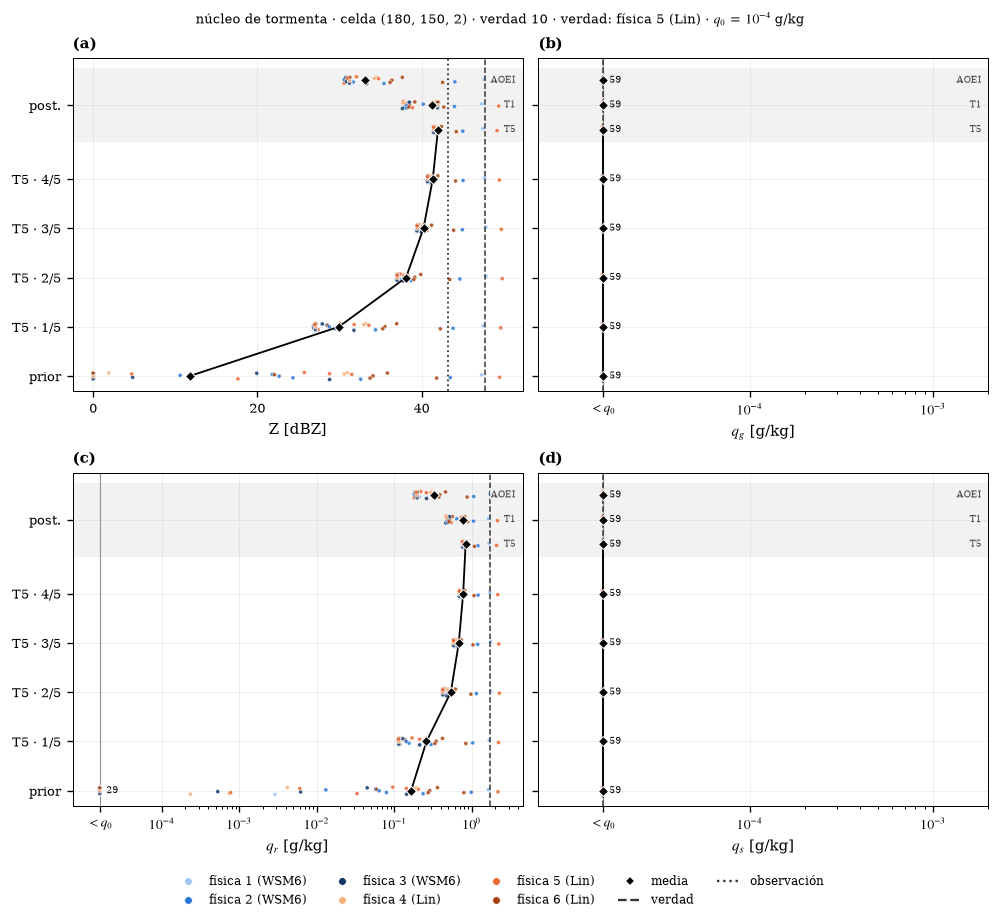

figures/es/N3s/points/edge/edge_190_160_4_tm01_A6.png  figures/en/N3s/points/edge/edge_190_160_4_tm01_A6.png


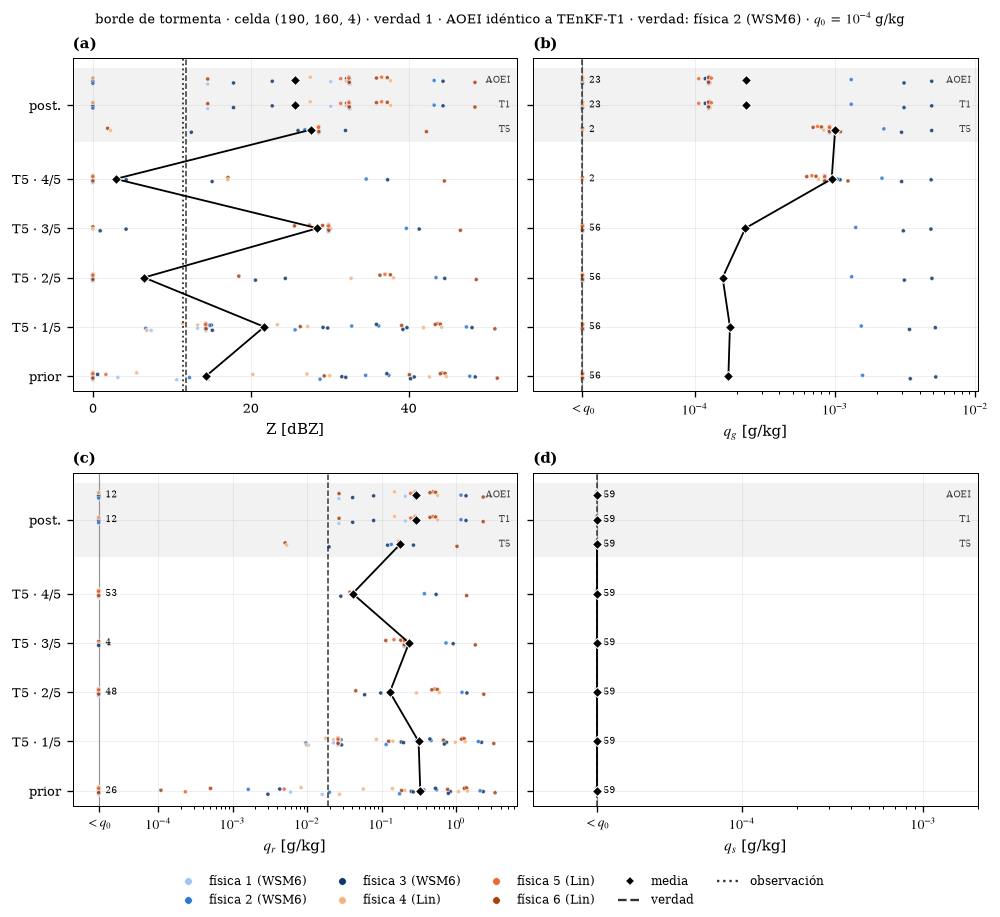

120 figuras _A6 en figures/<idioma>/N3s/points/, 61 s


In [36]:
A6_VARS = ("Z", "qg", "qr", "qs")
CFG_COL = {1: "#9ec5f4", 2: "#2a78d6", 3: "#0d366b", 4: "#f7b37e", 5: "#eb6834", 6: "#a8410f"}


def micro(cfg):
    return "WSM6" if cfg <= 3 else "Lin"


def physics_of(m_truth):
    """La configuración física (namelist m mod 6 + 1) de los 59 miembros del prior de un punto, en su orden."""
    return np.array([n % 6 + 1 for n in range(NM) if n != m_truth])


def draw_physics_a6(lang, r):
    V, L, L9 = nb.VOCAB[lang], LABELS[lang], LABELS9[lang]
    P_ = STEPS[point_name(r)]
    colors = [CFG_COL[c] for c in physics_of(r.m)]
    fig, axes = plt.subplots(2, 2, figsize=(nb.PAGE_W * 1.2, nb.PAGE_W * 1.1), sharey=True,
                             constrained_layout=True)
    for q, (ax, v) in enumerate(zip(axes.flat, A6_VARS)):
        log = v in nb.HYDRO
        traj_panel(ax, P_, v, lang, log=log, colors=colors, scheme_ticks=True)
        ax.set_xlabel(qlabel(P_, v, lang) if log else L["Z"])
        if not log:
            ax.locator_params(axis="x", nbins=5)
        ax.set_title(f"({'abcd'[q]})", loc="left", fontweight="bold")
    h = [Line2D([], [], ls="", marker="o", ms=4.5, color=CFG_COL[c], mec="white", mew=0.3,
                label=f"{L9['cfg']} {c} ({micro(c)})") for c in CFG_COL]
    h += [Line2D([], [], ls="", marker="D", ms=4.5, color="k", mec="white", label=L9["mean_k"]),
          Line2D([], [], ls="--", color="0.2", label=V["truth"]), Line2D([], [], ls=":", color="0.2", label=V["obs"])]
    fig.legend(handles=h, loc="outside lower center", ncol=5, frameon=False, fontsize=7)
    fig.suptitle(title_of(r, lang) + f" · {V['truth']}: {L9['cfg']} {r.m % 6 + 1} ({micro(r.m % 6 + 1)})"
                 + q0_note(), fontsize=8)
    return fig


save_all(draw_physics_a6, "A6")

### 9.8 · La sección 8 con el umbral «en cero»

El recuento de la sección 8 (aire claro y viento vertical débil, en la celda observada) con «en cero» = $q < q_0$ (`Q0_MODE`), junto al original ($q$ exactamente 0). Solo cambia el recuento; la media, el error y el CRPS son los de la sección 8. «Menos en cero»: en cuántos puntos de 10 el esquema deja menos miembros en cero que el prior.

In [37]:
ZERO_MODES = ("exacto", Q0_MODE)
rows = []
for r in SEL[SEL.condition.isin(MECH_CONDS)].itertuples(index=False):
    P_ = STEPS[point_name(r)]
    q0s = {Q0_MODE: q0_of(P_)}
    tru = P_["truth_point_state"].astype(np.float64) * 1e3
    for v in HYD:
        iv = nb.VI[v]
        xs = [("prior", P_["xf_point"][:, iv])] + [
            (f"T{nt}", P_[f"{FIG_MODE}/c{combo_index(P_, meth, nt):02d}_state_post_clamp"][-1][:, iv])
            for meth, nt in MECH_SCHEMES]
        for st, x in xs:
            x = x.astype(np.float64) * 1e3
            row = dict(condition=r.condition, point=point_name(r), var=v, stage=st)
            for m_ in ZERO_MODES:
                below = (x == 0) if m_ == "exacto" else (x < q0s[m_][v])
                row[m_] = int(below.sum())
                row[f"verdad {m_}"] = bool(tru[iv] == 0) if m_ == "exacto" else bool(tru[iv] < q0s[m_][v])
            rows.append(row)
HZ0 = pd.DataFrame(rows)
assert (HZ0["exacto"].to_numpy() == HZ.n_zero.to_numpy()).all(), "no es el recuento de la sección 8"
print(f"«en cero»: exacto = q exactamente 0; {Q0_MODE} = q < q_0" + (f" = {Q0_SINGLE:g} g/kg" if Q0_MODE == "single" else ""))

print("\nverdad en cero, puntos de 10:")
print(HZ0[HZ0.stage == "prior"].groupby(["condition", "var"], sort=False)[[f"verdad {m_}" for m_ in ZERO_MODES]]
      .sum().rename(index=L_COND, level=0).to_string())

pr0 = HZ0[HZ0.stage == "prior"].set_index(["point", "var"])
rows = []
for (c, v, st), g in HZ0.groupby(["condition", "var", "stage"], sort=False):
    row = {"condición": L_COND[c], "var": v, "etapa": "prior" if st == "prior" else f"TEnKF-{st}"}
    for m_ in ZERO_MODES:
        gi = g.set_index(["point", "var"])
        row[(m_, "en cero (de 59)")] = g[m_].mean()
        row[(m_, "menos en cero")] = int((gi[m_] < pr0.loc[gi.index, m_]).sum()) if st != "prior" else np.nan
    rows.append(row)
MT0 = pd.DataFrame(rows).set_index(["condición", "var", "etapa"])
MT0.columns = pd.MultiIndex.from_tuples(MT0.columns)
print("\nMedia sobre los 10 puntos de los miembros en cero; «menos en cero»: puntos de 10, respecto del prior")
print(MT0.to_string(float_format=lambda x: f"{x:.3g}", na_rep=""))

STAGES8 = ["prior"] + [f"T{n}" for _, n in MECH_SCHEMES]
for v in HYD:
    t = HZ0[HZ0["var"] == v].pivot_table(index=["condition", "point"], columns="stage", values=list(ZERO_MODES),
                                         sort=False)
    t = t.reorder_levels([1, 0], axis=1).reindex(columns=pd.MultiIndex.from_product([STAGES8, ZERO_MODES]))
    t.index = [f"{L_COND[c]} · {p}" for c, p in t.index]
    print(f"\n{v}: miembros en cero por punto (de 59), en los dos recuentos")
    print(t.astype(int).to_string())

«en cero»: exacto = q exactamente 0; single = q < q_0 = 0.0001 g/kg

verdad en cero, puntos de 10:
                           verdad exacto  verdad single
condition             var                              
viento vertical débil qg               4             10
                      qr               3             10
                      qs               4             10
aire claro            qg               2             10
                      qr               1             10
                      qs               2              9

Media sobre los 10 puntos de los miembros en cero; «menos en cero»: puntos de 10, respecto del prior
                                            exacto                        single              
                                   en cero (de 59) menos en cero en cero (de 59) menos en cero
condición             var etapa                                                               
viento vertical débil qg  prior               22.2                

### 9.9 · El zigzag en los 60 puntos

Para cada punto, los cambios de signo del error de $Z$ de TEnKF-T5 entre pasos consecutivos (incluido prior → paso 1, con `SIGN_TOL`, de 0 a 5), junto a la observación $y_o$ con su banda y los miembros del prior en el límite de detección ($Z$ = 0 dBZ). La relación con $y_o$ no es monótona ($y_o$ = 0 y $y_o$ alta dan 0 cambios): por eso las bandas. Los puntos de corriente vertical son los de $w_t \ge$ 15 y $w_t \le$ −8 m/s.

In [38]:
YO_BANDS = ["0 (límite)", "(0, 10)", "[10, 20)", "[20, 30)", "[30, 40)", "≥ 40"]
rows = []
for r in SEL.itertuples(index=False):
    P_ = STEPS[point_name(r)]
    H, _, _ = z_steps(P_, "TEnKF", 5)
    e = H.mean(1) - float(P_["yo_clean"])
    s = np.where(np.abs(e) > SIGN_TOL, np.sign(e), 0.0)
    zval, cnt = np.unique(P_["hxf_point"], return_counts=True)
    rows.append({"condición": r.condition, "punto": point_name(r), "y_o": float(P_["yo"]),
                 "cambios": int((s[:-1] * s[1:] < 0).sum()), "N_Z=0 prior": int((P_["hxf_point"] <= DBZ_MIN).sum()),
                 "Z_t": float(P_["yo_clean"]), "bloque_en_0": bool(zval[cnt.argmax()] <= DBZ_MIN)})
ZG = pd.DataFrame(rows)
yo_ = ZG.y_o
ZG.insert(2, "banda y_o", pd.Categorical(np.select([yo_ <= DBZ_MIN, yo_ < 10, yo_ < 20, yo_ < 30, yo_ < 40],
                                                   YO_BANDS[:-1], YO_BANDS[-1]), categories=YO_BANDS, ordered=True))
ZG = ZG.sort_values(["banda y_o", "cambios", "condición"], ascending=[True, False, True], kind="stable")
print("Zigzag de TEnKF-T5 en los 60 puntos; N_Z=0 prior: miembros del prior en el límite de detección (de 59)")
print(ZG.drop(columns="bloque_en_0").to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\npor banda de y_o [dBZ]")
print(ZG.groupby("banda y_o", observed=True).agg(
    puntos=("punto", "size"), con_cambios=("cambios", lambda v: int((v > 0).sum())),
    cambios_medios=("cambios", "mean"), N_Z0_mediana=("N_Z=0 prior", "median"),
    condiciones=("condición", lambda v: ", ".join(sorted(set(v))))).to_string(float_format=lambda v: f"{v:.2f}"))
print(f"\nel bloque más grande de miembros con la misma Z del prior es el de Z = 0 en {int(ZG.bloque_en_0.sum())} "
      f"de {len(ZG)} puntos; en los demás, N_Z=0 prior =",
      ", ".join(f"{p} {n}" for p, n in ZG.loc[~ZG.bloque_en_0, ["punto", "N_Z=0 prior"]].itertuples(index=False)))

Zigzag de TEnKF-T5 en los 60 puntos; N_Z=0 prior: miembros del prior en el límite de detección (de 59)
condición                     punto  banda y_o   y_o  cambios  N_Z=0 prior   Z_t
    clear       clear_230_60_7_tm39 0 (límite)  0.00        0           58  0.00
    clear       clear_280_30_0_tm15 0 (límite)  0.00        0           56  0.00
    clear       clear_220_70_2_tm18 0 (límite)  0.00        0           58  0.00
    clear      clear_170_240_5_tm23 0 (límite)  0.00        0           58  0.00
     edge       edge_230_300_6_tm36 0 (límite)  0.00        0           53  0.00
     edge       edge_140_420_6_tm48 0 (límite)  0.00        0           56  0.00
     edge       edge_270_160_3_tm00 0 (límite)  0.00        0           48  0.00
     edge       edge_200_430_6_tm34 0 (límite)  0.00        0           50  0.00
     edge       edge_130_330_3_tm38 0 (límite)  0.00        0           47  0.00
     weak       weak_170_140_6_tm44 0 (límite)  0.00        0           52  0.00
     w

### 9.10 · Tablas adicionales

Solo tablas, de los ensambles guardados:

1. Los cambios de signo del error de $Z$ entre pasos consecutivos (incluido prior → paso 1) con TEnKF-T$N_t$, $N_t$ = 2 a 5, por condición: cuántos pares de pasos cambian y qué porcentaje de los pares son (10 puntos × $N_t$ pares). Es la tabla 3 de la sección 7, con la misma tolerancia `SIGN_TOL`, sin los puntos de la primera selección.
2. corr($Z$, $w$) y corr($q_g+q_r+q_s$, $Z$) de los 59 miembros en la celda observada, por condición: media, mínimo y máximo sobre los 10 puntos, en el prior y en los posteriores de TEnKF-T5, TEnKF-T1 y AOEI; y cuántos puntos tienen |corr($Z$, $w$)| del prior mayor que 0,13 (≈ $1/\sqrt{59}$, la desviación típica de la correlación de 59 miembros sin relación entre las dos variables).
3. Corrientes verticales fuertes: el error absoluto de la media de $w$ y la dispersión de $w$ (desviación típica de los 59 miembros), media sobre los 10 puntos, en el prior, después del paso 1 de TEnKF-T5 y en los posteriores de TEnKF-T5, TEnKF-T1 y AOEI; y el rango de $w$ de la verdad.

In [39]:
# 1 · Cambios de signo: la tabla SG de la sección 7, solo con los puntos actuales.
sg9 = (SG[SG.condition.isin(CONDITIONS)].groupby(["condition", "ntemp"])
       .agg(pares=("flip", "size"), con_signo=("signed", "sum"), cambian=("flip", "sum")))
sg9["% de los pares"] = 100 * sg9.cambian / sg9.pares
assert (sg9.pares == 10 * sg9.index.get_level_values("ntemp")).all()
print(f"Cambios de signo del error de Z entre pasos consecutivos (incluido prior → paso 1), por N_t; "
      f"pares = 10 puntos × N_t; pares sin signo (|e| ≤ {SIGN_TOL:g} dBZ): {int((sg9.pares - sg9.con_signo).sum())}")
print(sg9[["cambian", "% de los pares"]].unstack("ntemp").reindex(CONDITIONS)
      .to_string(float_format=lambda v: f"{v:.0f}"))

Cambios de signo del error de Z entre pasos consecutivos (incluido prior → paso 1), por N_t; pares = 10 puntos × N_t; pares sin signo (|e| ≤ 0.001 dBZ): 0
          cambian             % de los pares         
ntemp           2   3   4   5              2  3  4  5
condition                                            
core            0   0   0   0              0  0  0  0
edge            7  11  16  16             35 37 40 32
updraft         0   0   0   0              0  0  0  0
downdraft       2   3   4   4             10 10 10  8
weak            0   0   0   0              0  0  0  0
clear           0   0   0   0              0  0  0  0


In [40]:
# 2 · corr(Z, w) y corr(q_g+q_r+q_s, Z) por condición. Una correlación no definida (Z o la otra variable igual en
# los 59 miembros) no entra en la media; «puntos» cuenta las definidas.
C_STAGES = {"prior": "prior", "T5_5": "TEnKF-T5", "T1": "TEnKF-T1", "AOEI": "AOEI"}
CORR_NOISE = 0.13      # ≈ 1/√59
rows = []
for r in SEL.itertuples(index=False):
    st = {s["key"]: s for s in stages(STEPS[point_name(r)])}
    for k, name in C_STAGES.items():
        X_, Z_ = st[k]["X"], st[k]["Z"]
        rows.append(dict(condition=r.condition, point=point_name(r), etapa=name,
                         zw=corr(val(X_, Z_, "Z"), val(X_, Z_, "w")), qz=corr(val(X_, Z_, "qtot"), val(X_, Z_, "Z"))))
CR = pd.DataFrame(rows)
t = CR.groupby(["condition", "etapa"], sort=False)[["zw", "qz"]].agg(["mean", "min", "max", "count"])
t = t.rename(columns={"zw": "corr(Z, w)", "qz": "corr(q_g+q_r+q_s, Z)", "mean": "media", "min": "mín",
                      "max": "máx", "count": "puntos"})
print("Correlaciones de los 59 miembros en la celda observada, sobre los 10 puntos de cada condición")
print(t.to_string(float_format=lambda v: f"{v:+.2f}"))
pr = CR[CR.etapa == "prior"]
print(f"\npuntos con |corr(Z, w)| del prior > {CORR_NOISE:g}:",
      ", ".join(f"{c} {int((g.zw.abs() > CORR_NOISE).sum())}/{len(g)}" for c, g in pr.groupby("condition", sort=False)))

Correlaciones de los 59 miembros en la celda observada, sobre los 10 puntos de cada condición
                   corr(Z, w)                    corr(q_g+q_r+q_s, Z)                   
                        media   mín   máx puntos                media   mín   máx puntos
condition etapa                                                                         
core      prior         -0.11 -0.57 +0.31     10                +0.83 +0.63 +1.00     10
          TEnKF-T5      -0.11 -0.49 +0.45     10                +0.98 +0.93 +1.00     10
          TEnKF-T1      -0.11 -0.75 +0.48     10                +0.87 +0.00 +0.99     10
          AOEI          -0.12 -0.55 +0.27     10                +0.89 +0.48 +1.00     10
edge      prior         +0.20 -0.13 +0.64     10                +0.87 +0.75 +0.97     10
          TEnKF-T5      +0.06 -0.14 +0.57     10                +0.87 +0.61 +1.00     10
          TEnKF-T1      +0.08 -0.26 +0.68     10                +0.82 +0.21 +1.00     10
          AOEI  

In [41]:
# 3 · Corrientes verticales fuertes: error absoluto de la media de w y dispersión de w (ddof = 1, como en las
# figuras de resumen), media sobre los 10 puntos.
W_STAGES = {"prior": "prior", "T5_1": "T5, paso 1", "T5_5": "TEnKF-T5", "T1": "TEnKF-T1", "AOEI": "AOEI"}
rows = []
for r in SEL[SEL.condition.isin(W_CONDS)].itertuples(index=False):
    P_ = STEPS[point_name(r)]
    wt = float(P_["truth_point_state"][nb.VI["w"]])
    st = {s["key"]: s for s in stages(P_)}
    for k, name in W_STAGES.items():
        w_ = val(st[k]["X"], st[k]["Z"], "w")
        rows.append(dict(condition=r.condition, etapa=name, abs_err=abs(w_.mean() - wt), spread=w_.std(ddof=1)))
WE = pd.DataFrame(rows)
t = WE.groupby(["condition", "etapa"], sort=False)[["abs_err", "spread"]].mean().unstack("etapa")
t = t.reindex(columns=pd.MultiIndex.from_product([["abs_err", "spread"], list(W_STAGES.values())]))
t = t.rename(columns={"abs_err": "|error de la media de w| [m/s]", "spread": "dispersión de w [m/s]"}, level=0)
print("Corrientes verticales fuertes, media sobre los 10 puntos")
print(t.reindex(list(W_CONDS)).to_string(float_format=lambda v: f"{v:.2f}"))
print("\nw de la verdad [m/s]:", "; ".join(
    f"{c} de {g.w_t.min():+.2f} a {g.w_t.max():+.2f} (media {g.w_t.mean():+.2f})"
    for c, g in SEL[SEL.condition.isin(W_CONDS)].groupby("condition", sort=False)))

Corrientes verticales fuertes, media sobre los 10 puntos
          |error de la media de w| [m/s]                                    dispersión de w [m/s]                                  
                                   prior T5, paso 1 TEnKF-T5 TEnKF-T1  AOEI                 prior T5, paso 1 TEnKF-T5 TEnKF-T1 AOEI
condition                                                                                                                          
updraft                            18.65      18.52    17.00    17.10 18.54                  1.02       1.01     0.89     0.90 1.01
downdraft                           9.11       9.16     9.35     9.86  9.26                  0.76       0.75     0.61     0.62 0.72

w de la verdad [m/s]: updraft de +15.09 a +24.18 (media +18.76); downdraft de -11.69 a -8.14 (media -9.05)


## 10 · Comprobación: el error absoluto de $Z$ de las corrientes verticales fuertes

La tabla 1 de la sección 7 da, para cada condición, la media sobre los 10 puntos del error de la media de $Z$ con signo (`e_*`) y con valor absoluto (`abs_e_*`). Acá se rehace, solo para la ascendente y la descendente fuertes, la media sobre los puntos de $|e|$ (no el valor absoluto de la media de los $e$ con signo), con TEnKF-T5 en el prior, después del paso 1 y al final, punto por punto y comparada con la de la sección 7.

In [42]:
rows = []
for r in SEL[SEL.condition.isin(W_CONDS)].itertuples(index=False):
    P_ = STEPS[point_name(r)]
    H, _, _ = z_steps(P_, "TEnKF", 5)
    e = H.mean(1) - float(P_["yo_clean"])                 # error de la media de Z [dBZ]
    rows.append(dict(condition=r.condition, point=point_name(r), e_prior=e[0], e_paso1=e[1], e_final=e[-1]))
E10 = pd.DataFrame(rows)
E_COLS = ["e_prior", "e_paso1", "e_final"]
# los mismos errores, punto por punto, que usa la tabla 1 de la sección 7
zt = ZT[ZT.condition.isin(W_CONDS)]
assert np.array_equal(zt[["e_prior", "e_step1", "e_final"]].to_numpy(), E10[E_COLS].to_numpy())

g = E10.groupby("condition", sort=False)[E_COLS]
print("TEnKF-T5, error de la media de Z [dBZ], 10 puntos por condición")
print(pd.concat({"media de |e|": g.agg(lambda v: v.abs().mean()), "|media de e|": g.mean().abs(),
                 "puntos con e > 0": g.agg(lambda v: int((v > 0).sum()))}, axis=1)
      .to_string(float_format=lambda v: f"{v:.2f}"))
print("\npor punto:")
print(E10.to_string(index=False, float_format=lambda v: f"{v:+.2f}"))

TEnKF-T5, error de la media de Z [dBZ], 10 puntos por condición
          media de |e|                 |media de e|                 puntos con e > 0                
               e_prior e_paso1 e_final      e_prior e_paso1 e_final          e_prior e_paso1 e_final
condition                                                                                           
updraft          48.15   33.03   16.07        48.15   33.03   16.07                0       0       0
downdraft        43.94   30.34   12.18        43.94   30.34   12.18                0       0       0

por punto:
condition                     point  e_prior  e_paso1  e_final
  updraft    updraft_134_218_7_tm59   -49.54   -33.98   -12.70
  updraft   updraft_155_346_10_tm25   -45.77   -31.14   -10.78
  updraft   updraft_122_407_10_tm51   -47.13   -35.39   -13.25
  updraft    updraft_137_365_8_tm38   -50.17   -28.17   -10.56
  updraft    updraft_159_301_8_tm44   -40.34   -15.91    -4.81
  updraft     updraft_55_102_8_tm48   -52

## 11 · Dónde falla el LETKF de un paso: clasificación y puntos propuestos

Con la salida guardada de los experimentos de observación única (4 km–5 min, 20 UTC, los 60 miembros verdad, celdas del barrido), cada experimento se clasifica por lo que hace TEnKF-T1 con $Z$. Con $e_f$ y $e_a$ los errores de la media de $Z$ del prior y del posterior respecto de la verdad ($Z_t$, sin ruido) y $d = y_o - \overline{H(\mathbf{x}_f)}$ la innovación:

- **sobrepaso:** $e_a$ y $e_f$ de signo opuesto y $|e_a| > |e_f|$;
- **corrección corta:** $|d| \ge$ 10 dBZ y $|e_a| > 0{,}8\,|e_f|$;
- **dirección equivocada:** $e_a$ y $e_f$ del mismo signo y $|e_a| > |e_f|$;
- **mayor diferencia T1–T5:** el 1 % de los experimentos con mayor $|e_a(\mathrm{T1})| - |e_a(\mathrm{T5})|$.

Un error con $|e| \le$ 10⁻³ dBZ no tiene signo, y $|e_a| > |e_f|$ quiere decir mayor por más de 10⁻³ dBZ (`nb.TOL["obs"]`, la tolerancia de empate del capítulo). Las clases se superponen (la corrección corta, tal como está definida, incluye sobrepasos con $|d| \ge$ 10): se imprimen los cruces. Se excluye la celda no finita (60 experimentos), como en la sección 1.

**Puntos propuestos (sin correr).** 10 por clase, al azar con semilla fija, de la clase con menos candidatos a la de más. Un punto por región: como los candidatos están en la grilla del barrido (una celda de cada 10), las regiones son los grupos de columnas candidatas vecinas en esa grilla (con diagonales, juntando los miembros); primero miembros verdad distintos y, si no alcanza, sin esa condición; ninguna celda de los 60 puntos actuales ni de otra clase. Si una clase tiene menos regiones que puntos (las clases dominadas por aire claro ocupan casi toda la grilla y forman pocas regiones enormes), el resto se toma en regiones ya usadas, a más de `SEP_KM` de los puntos ya elegidos de la clase. Para que cada clase muestre su comportamiento, los de corrección corta se eligen entre los que no son sobrepaso ni dirección equivocada.

In [43]:
from scipy import ndimage

TOLZ = nb.TOL["obs"]          # dBZ
TOP_Q = 0.99                  # la clase T1–T5: por encima de este cuantil
FAIL_CLASSES = ("sobrepaso", "corta", "equivocada", "T1-T5")
cols = ["i", "j", "k", "x_km", "y_km", "z_km", "yo", "yo_clean", "hxf_mean_obs", "dep_b", "n_active_f_point", "spread_f_point_obs"]
parts = []
for tm in range(NM):
    with np.load(nb.sweep_files(TAG_SWEEP, [tm])[0]) as z:
        meth, nt = z["method"], z["ntemp"]
        t1, t5 = (meth == "TEnKF") & (nt == 1), (meth == "TEnKF") & (nt == 5)
        assert all(np.array_equal(z[c][t1], z[c][t5]) for c in ("i", "j", "k"))
        parts.append(pd.DataFrame({c: z[c][t1] for c in cols}).assign(
            tm=tm, hxa_T1=z["hxa_mean_obs"][t1], hxa_T5=z["hxa_mean_obs"][t5]))
EXP = pd.concat(parts, ignore_index=True)
n_all = len(EXP)
EXP = EXP[FINITE[EXP.i, EXP.j, EXP.k]].reset_index(drop=True)
assert (N_ECHO[EXP.i, EXP.j, EXP.k, EXP.tm] == EXP.n_active_f_point).all()      # N_Z>0 del prior, como en la sección 1
for c in ("yo", "yo_clean", "hxf_mean_obs", "hxa_T1", "hxa_T5", "dep_b", "spread_f_point_obs"):
    EXP[c] = EXP[c].astype(np.float64)
EXP["e_f"] = EXP.hxf_mean_obs - EXP.yo_clean
EXP["e_a1"] = EXP.hxa_T1 - EXP.yo_clean
EXP["e_a5"] = EXP.hxa_T5 - EXP.yo_clean
af, a1 = EXP.e_f.abs(), EXP.e_a1.abs()
sf = np.where(af > TOLZ, np.sign(EXP.e_f), 0.0)
s1 = np.where(a1 > TOLZ, np.sign(EXP.e_a1), 0.0)
EXP["peor"] = a1 - af                                         # |e_a| − |e_f| de T1
EXP["T1-T5_dif"] = a1 - EXP.e_a5.abs()
EXP["sobrepaso"] = (sf * s1 < 0) & (EXP.peor > TOLZ)
EXP["corta"] = (EXP.dep_b.abs() >= 10) & (a1 > 0.8 * af)
EXP["equivocada"] = (sf * s1 > 0) & (EXP.peor > TOLZ)
TOP_THR = float(EXP["T1-T5_dif"].quantile(TOP_Q))
EXP["T1-T5"] = EXP["T1-T5_dif"] >= TOP_THR
print(f"{len(EXP):,} experimentos (de {n_all:,}; fuera la celda no finita); clase T1–T5: |e_a(T1)| − |e_a(T5)| ≥ "
      f"{TOP_THR:.2f} dBZ")
print("\nexperimentos por clase y cruces (filas ∩ columnas):")
print(pd.DataFrame([[int((EXP[a] & EXP[b]).sum()) for b in FAIL_CLASSES] for a in FAIL_CLASSES],
                   index=FAIL_CLASSES, columns=FAIL_CLASSES).to_string())
c_ = EXP.corta
print(f"\ncorrección corta: {int(c_.sum())} = {int((c_ & EXP.sobrepaso).sum())} sobrepasos + "
      f"{int((c_ & EXP.equivocada).sum())} en dirección equivocada + "
      f"{int((c_ & (sf * s1 > 0) & (EXP.peor <= TOLZ)).sum())} del mismo signo que corrigen poco + "
      f"{int((c_ & (sf * s1 < 0) & (EXP.peor <= TOLZ)).sum())} que cruzan la verdad sin pasar |e_f| + "
      f"{int((c_ & ((sf == 0) | (s1 == 0))).sum())} sin signo")

565,366 experimentos (de 565,426; fuera la celda no finita); clase T1–T5: |e_a(T1)| − |e_a(T5)| ≥ 21.01 dBZ

experimentos por clase y cruces (filas ∩ columnas):
            sobrepaso  corta  equivocada  T1-T5
sobrepaso       14309   3247           0    127
corta            3247   5647          81     45
equivocada          0     81      126901   5526
T1-T5             127     45        5526   5654

corrección corta: 5647 = 3247 sobrepasos + 81 en dirección equivocada + 720 del mismo signo que corrigen poco + 1599 que cruzan la verdad sin pasar |e_f| + 0 sin signo


In [44]:
# Cómo son los experimentos de cada clase, junto a todos
def q_table(v):
    rows = {}
    for c in FAIL_CLASSES + ("todos",):
        x = EXP[v] if c == "todos" else EXP.loc[EXP[c], v]
        rows[c] = {"media": x.mean(), **{f"P{p}": x.quantile(p / 100) for p in (10, 25, 50, 75, 90)}}
    return pd.DataFrame(rows).T


prof = {}
for c in FAIL_CLASSES + ("todos",):
    g = EXP if c == "todos" else EXP[EXP[c]]
    prof[c] = {"experimentos": len(g), "% del total": 100 * len(g) / len(EXP), "|e_f| P50": g.e_f.abs().median(),
               "|e_a|−|e_f| P50": g.peor.median(), "% Z_t = 0": 100 * (g.yo_clean <= DBZ_MIN).mean(),
               "% y_o = 0": 100 * (g.yo <= DBZ_MIN).mean(), "% |d| < 1": 100 * (g.dep_b.abs() < 1).mean()}
print("Perfil de cada clase [dBZ]")
print(pd.DataFrame(prof).T.to_string(float_format=lambda v: f"{v:.2f}"))
for v, name in (("yo", "y_o [dBZ]"), ("dep_b", "innovación d [dBZ]"), ("n_active_f_point", "N_Z>0 del prior"),
                ("spread_f_point_obs", "dispersión del prior de Z [dBZ]"), ("z_km", "altura [km]")):
    print(f"\n{name}")
    print(q_table(v).to_string(float_format=lambda x: f"{x:.2f}"))
print("\naltura: % de los experimentos de cada clase por nivel [km]")
print(pd.DataFrame({c: (EXP if c == "todos" else EXP[EXP[c]]).z_km.value_counts(normalize=True).sort_index() * 100
                    for c in FAIL_CLASSES + ("todos",)}).T.to_string(float_format=lambda x: f"{x:.0f}"))

Perfil de cada clase [dBZ]
            experimentos  % del total  |e_f| P50  |e_a|−|e_f| P50  % Z_t = 0  % y_o = 0  % |d| < 1
sobrepaso       14309.00         2.53       5.29             5.67       0.00       0.84       7.61
corta            5647.00         1.00      13.02             1.10       2.09       0.00       0.00
equivocada     126901.00        22.45       1.54             7.15      95.85       0.43      36.08
T1-T5            5654.00         1.00       1.64            21.60      97.10       0.00      24.74
todos          565366.00       100.00       1.37            -0.14      88.91      44.80      39.52

y_o [dBZ]
            media   P10   P25   P50   P75   P90
sobrepaso   11.82  4.18  6.93 10.78 15.57 20.41
corta       18.12 12.61 14.63 17.43 20.89 24.61
equivocada   2.84  1.13  1.64  2.44  3.45  4.55
T1-T5        3.71  1.94  2.52  3.35  4.41  5.54
todos        3.00  0.00  0.00  0.33  2.17  5.55

innovación d [dBZ]
            media   P10   P25   P50   P75   P90
sobrepaso   

In [45]:
# Puntos propuestos: 10 por clase. Regiones en la grilla del barrido (una celda de cada STRIDE).
POOL_OF = {"sobrepaso": EXP.sobrepaso, "equivocada": EXP.equivocada, "T1-T5": EXP["T1-T5"],
           "corta": EXP.corta & ~EXP.sobrepaso & ~EXP.equivocada}
USED_P = {(int(i), int(j), int(k)) for i, j, k in SEL[["i", "j", "k"]].itertuples(index=False)}
NXC, NYC = (NX - 1) // STRIDE + 1, (NY - 1) // STRIDE + 1
SEP_KM = 100.0         # si faltan regiones: separación mínima entre los puntos de una clase
# Pasadas, en orden: (región nueva, miembro verdad nuevo). Las dos últimas, solo si faltan regiones.
PASSES = ((True, True), (True, False), (False, True), (False, False))
rng_p = np.random.default_rng(SEED)
rows = []
for c in sorted(POOL_OF, key=lambda c: int(POOL_OF[c].sum())):          # de la reserva más chica a la más grande
    cand = EXP[POOL_OF[c]]
    cand = cand[[(i, j, k) not in USED_P for i, j, k in cand[["i", "j", "k"]].itertuples(index=False)]]
    ci, cj, ck, ctm = (cand[v].to_numpy() for v in ("i", "j", "k", "tm"))
    cx, cy = cand.x_km.to_numpy(float), cand.y_km.to_numpy(float)
    cols_c = np.zeros((NXC, NYC), bool)
    cols_c[ci // STRIDE, cj // STRIDE] = True
    lab, n_reg = ndimage.label(cols_c, structure=EIGHT)
    creg = lab[ci // STRIDE, cj // STRIDE]
    perm = rng_p.permutation(len(cand))
    got, regs, mems, xy = [], set(), set(), []
    for new_region, new_member in PASSES:
        for q in perm:
            cell, g, m = (int(ci[q]), int(cj[q]), int(ck[q])), int(creg[q]), int(ctm[q])
            if cell in USED_P or (new_member and m in mems):
                continue
            if new_region and g in regs:
                continue
            if not new_region and any(np.hypot(cx[q] - x, cy[q] - y) < SEP_KM for x, y in xy):
                continue
            regs.add(g)
            mems.add(m)
            xy.append((cx[q], cy[q]))
            USED_P.add(cell)
            got.append(cand.iloc[q].to_dict() | {"clase": c, "región": g, "columnas de la región": int((lab == g).sum()),
                                                 "región nueva": new_region})
            if len(got) == N_POINTS:
                break
        if len(got) == N_POINTS:
            break
    assert len(got) == N_POINTS, f"{c}: solo {len(got)} puntos"
    print(f"{c}: {len(cand):,} candidatos en {n_reg} regiones; {sum(g_['región nueva'] for g_ in got)} puntos en "
          f"regiones distintas, {N_POINTS - sum(g_['región nueva'] for g_ in got)} a ≥ {SEP_KM:g} km; "
          f"{len(mems)} miembros verdad distintos")
    rows += got
PROP = pd.DataFrame(rows)
PROP["también"] = [", ".join(o for o in FAIL_CLASSES if o != c and r[o]) for c, r in zip(PROP.clase, PROP.to_dict("records"))]
PROP = PROP.astype({"i": int, "j": int, "k": int, "tm": int, "n_active_f_point": int})
print("\nPuntos propuestos (sin correr); errores de la media de Z [dBZ]")
print(PROP.rename(columns={"tm": "m", "yo": "y_o", "yo_clean": "Z_t", "dep_b": "d", "n_active_f_point": "N_Z>0",
                           "spread_f_point_obs": "disp. prior", "e_a1": "e_a T1", "e_a5": "e_a T5"})[
    ["clase", "i", "j", "k", "z_km", "m", "y_o", "Z_t", "d", "N_Z>0", "disp. prior", "e_f", "e_a T1", "e_a T5",
     "región", "columnas de la región", "también"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

corta: 2,304 candidatos en 17 regiones; 10 puntos en regiones distintas, 0 a ≥ 100 km; 10 miembros verdad distintos
T1-T5: 5,617 candidatos en 30 regiones; 10 puntos en regiones distintas, 0 a ≥ 100 km; 10 miembros verdad distintos
sobrepaso: 14,196 candidatos en 14 regiones; 10 puntos en regiones distintas, 0 a ≥ 100 km; 10 miembros verdad distintos
equivocada: 125,789 candidatos en 4 regiones; 4 puntos en regiones distintas, 6 a ≥ 100 km; 10 miembros verdad distintos

Puntos propuestos (sin correr); errores de la media de Z [dBZ]
     clase   i   j  k  z_km  m   y_o   Z_t     d  N_Z>0  disp. prior    e_f  e_a T1  e_a T5  región  columnas de la región    también
     corta 280 420  6  5.00  6 29.79 25.40 22.79     17        13.45 -18.40   16.48    3.15       6                    778           
     corta   0 170  1  0.50 38 23.91 21.51 23.77      1         1.05 -21.37  -18.06  -16.67       1                      4           
     corta 290  90  4  3.00 32 34.59 29.87 34.51      1     

## 12 · Puntos donde falla el LETKF de un paso: clases, corridas y figuras

Clases redefinidas sobre los mismos experimentos de la sección 11 (TEnKF-T1, 4 km–5 min, 20 UTC, celdas del barrido; error de la media de $Z$ respecto de la verdad, con la tolerancia de empate de 10⁻³ dBZ):

- **A · aire claro, el ruido levanta $Z$:** $Z_t$ = 0 y $|e_a| - |e_f| \ge$ 1 dBZ (T1 empeora).
- **B · sobrepaso en eco:** $Z_t > 0$, el error cambia de signo y $|e_a| > |e_f|$.
- **C · prior trabado:** $|d| \ge$ 10 dBZ, el mismo signo antes y después, y $|e_a| > 0{,}8\,|e_f|$. **C1** con $N_{Z>0} \le 2$ en el prior; **C2** con $N_{Z>0} \ge 3$.
- **D · el temperado ayuda en eco:** $Z_t > 0$ y el 1 % de mayor $|e_a(\mathrm{T1})| - |e_a(\mathrm{T5})|$ dentro de ese subconjunto.

**Selección.** 10 puntos en A, B y D y 5 en C1 y C2. Primero las cinco clases como en la sección 11: al azar con semilla fija, de la clase con menos candidatos a la de más; un punto por región (grupos de columnas candidatas vecinas en la grilla del barrido); primero miembros verdad distintos; ninguna celda de los 60 puntos de las secciones 2–9 ni de otra clase; si una clase tiene menos regiones que puntos, el resto a más de `SEP_KM` de los ya elegidos. De ahí quedan C1, C2 y D. A y B forman cada una una sola región con ~99 % de sus candidatos, y la regla sacaba 9 de sus 10 puntos de fragmentos chicos junto al borde oeste (sección 13c): se eligen de nuevo sin regiones, al azar con semilla fija, a más de `SEP_KM` entre los puntos de la clase, primero con miembros verdad distintos y sin celdas de los demás puntos. La selección por regiones, con las corridas y figuras de sus A y B, se guarda en `data/derived/N3s/failure/old_region/` y `figures/<idioma>/N3s/failure/old_region/`; la actual, en `data/derived/N3s/failure/selection.csv`.

**Corridas.** Como las de la sección 4: `run_point` (TEnKF-T1 a T5 y AOEI, con la censura en cada paso y solo al final), un archivo por punto en `data/derived/N3s/failure/steps/`. Todos los puntos están en celdas del barrido, así que se verifican contra el barrido como en la sección 5.

**Figuras**, en los dos idiomas, en `figures/<idioma>/N3s/failure/`: A1 y A2 por punto (`<clase>/<punto>_A1.png`, `_A2.png`) y un resumen por clase como el de las condiciones (`<clase>_summary.png`). Después, las tablas de la sección 7 y la del zigzag de la sección 9.9 para los 40 puntos.

In [46]:
F_CLASSES = ("A", "B", "C1", "C2", "D")
F_N = {"A": 10, "B": 10, "C1": 5, "C2": 5, "D": 10}
af, a1 = EXP.e_f.abs(), EXP.e_a1.abs()
sf = np.where(af > TOLZ, np.sign(EXP.e_f), 0.0)
s1 = np.where(a1 > TOLZ, np.sign(EXP.e_a1), 0.0)
echo_t = EXP.yo_clean > DBZ_MIN                               # Z de la verdad > 0
stuck = (EXP.dep_b.abs() >= 10) & (sf * s1 > 0) & (a1 > 0.8 * af)
D_THR = float(EXP.loc[echo_t, "T1-T5_dif"].quantile(TOP_Q))
FCLS = pd.DataFrame({
    "A": ~echo_t & (EXP.peor >= 1.0),
    "B": echo_t & (sf * s1 < 0) & (EXP.peor > TOLZ),
    "C1": stuck & (EXP.n_active_f_point <= 2),
    "C2": stuck & (EXP.n_active_f_point >= 3),
    "D": echo_t & (EXP["T1-T5_dif"] >= D_THR)})
print(f"{len(EXP):,} experimentos; D: |e_a(T1)| − |e_a(T5)| ≥ {D_THR:.2f} dBZ (1 % de los {int(echo_t.sum()):,} con Z_t > 0)")
print(f"C: {int(stuck.sum())} experimentos; de ellos con |e_a| > |e_f| (empeoran): {int((stuck & (EXP.peor > TOLZ)).sum())}")
print("\nexperimentos por clase y cruces (filas ∩ columnas):")
print(pd.DataFrame([[int((FCLS[a] & FCLS[b]).sum()) for b in F_CLASSES] for a in F_CLASSES],
                   index=F_CLASSES, columns=F_CLASSES).to_string())


def p50_range(x, fmt_="{:.1f}"):
    return f"{fmt_.format(x.median())} [{fmt_.format(x.quantile(0.1))}, {fmt_.format(x.quantile(0.9))}]"


rows = {}
for c in F_CLASSES + ("todos",):
    g = EXP if c == "todos" else EXP[FCLS[c]]
    rows[c] = {"experimentos": f"{len(g):,}", "y_o": p50_range(g.yo), "d": p50_range(g.dep_b),
               "N_Z>0": p50_range(g.n_active_f_point, "{:.0f}"), "dispersión prior": p50_range(g.spread_f_point_obs),
               "altura [km]": p50_range(g.z_km, "{:g}"), "% Z_t = 0": f"{100 * (g.yo_clean <= DBZ_MIN).mean():.0f}",
               "|e_a|−|e_f|": p50_range(g.peor)}
print("\nmediana [P10, P90]; y_o, d, dispersión y |e_a| − |e_f| en dBZ")
print(pd.DataFrame(rows).T.to_string())


def yo_band(y):
    y = np.asarray(y, float)
    return pd.Categorical(np.select([y <= DBZ_MIN, y < 10, y < 20, y < 30, y < 40], YO_BANDS[:-1], YO_BANDS[-1]),
                          categories=YO_BANDS, ordered=True)


print("\ny_o por banda del zigzag (sección 9.9), % de los experimentos de la clase")
print(pd.DataFrame({c: pd.Series(yo_band(EXP.loc[FCLS[c], "yo"])).value_counts(normalize=True, sort=False) * 100
                    for c in ("B", "D")}).T.to_string(float_format=lambda v: f"{v:.1f}"))

565,366 experimentos; D: |e_a(T1)| − |e_a(T5)| ≥ 17.89 dBZ (1 % de los 62,695 con Z_t > 0)
C: 801 experimentos; de ellos con |e_a| > |e_f| (empeoran): 81

experimentos por clase y cruces (filas ∩ columnas):
         A      B   C1   C2    D
A   103974      0    1   44    0
B        0  14309    0    0  481
C1       1      0  595    0    0
C2      44      0    0  206    1
D        0    481    0    1  627

mediana [P10, P90]; y_o, d, dispersión y |e_a| − |e_f| en dBZ
      experimentos                y_o                    d       N_Z>0  dispersión prior   altura [km] % Z_t = 0        |e_a|−|e_f|
A          103,974     2.4 [1.1, 4.4]      0.4 [-2.2, 2.9]   5 [1, 12]   6.9 [3.9, 11.3]   3 [0.5, 10]       100    8.7 [2.5, 18.5]
B           14,309   10.8 [4.2, 20.4]     5.7 [-0.0, 13.2]  10 [4, 49]   8.8 [5.1, 13.3]   4 [0.5, 10]         0    5.7 [0.8, 15.1]
C1             595  19.0 [11.4, 37.0]    18.9 [11.3, 36.9]    1 [1, 2]    0.7 [0.1, 1.2]  4 [0.25, 10]         0  -0.0 [-3.7, -0.0]
C2  

In [55]:
# Selección de los 40 puntos, con las reglas de la sección 11
OUT_F = OUT_S / "failure"
F_SEL_FILE = OUT_F / "selection.csv"
USED_F = {(int(i), int(j), int(k)) for i, j, k in SEL[["i", "j", "k"]].itertuples(index=False)}
rng_f = np.random.default_rng(SEED)
rows = []
for c in sorted(F_CLASSES, key=lambda c: int(FCLS[c].sum())):         # de la reserva más chica a la más grande
    cand = EXP[FCLS[c]]
    cand = cand[[(i, j, k) not in USED_F for i, j, k in cand[["i", "j", "k"]].itertuples(index=False)]]
    ci, cj, ck, ctm = (cand[v].to_numpy() for v in ("i", "j", "k", "tm"))
    cx, cy = cand.x_km.to_numpy(float), cand.y_km.to_numpy(float)
    cols_c = np.zeros((NXC, NYC), bool)
    cols_c[ci // STRIDE, cj // STRIDE] = True
    lab, n_reg = ndimage.label(cols_c, structure=EIGHT)
    creg = lab[ci // STRIDE, cj // STRIDE]
    perm = rng_f.permutation(len(cand))
    got, regs, mems, xy = [], set(), set(), []
    for new_region, new_member in PASSES:
        for q in perm:
            cell, g, m = (int(ci[q]), int(cj[q]), int(ck[q])), int(creg[q]), int(ctm[q])
            if cell in USED_F or (new_member and m in mems) or (new_region and g in regs):
                continue
            if not new_region and any(np.hypot(cx[q] - x, cy[q] - y) < SEP_KM for x, y in xy):
                continue
            regs.add(g)
            mems.add(m)
            xy.append((cx[q], cy[q]))
            USED_F.add(cell)
            got.append(dict(condition=c, i=cell[0], j=cell[1], k=cell[2], m=m, region=g, new_region=new_region,
                            exp=int(cand.index[q])))
            if len(got) == F_N[c]:
                break
        if len(got) == F_N[c]:
            break
    assert len(got) == F_N[c], f"{c}: solo {len(got)} puntos"
    n_new = sum(g_["new_region"] for g_ in got)
    print(f"{c}: {len(cand):,} candidatos en {n_reg} regiones; {n_new} puntos en regiones distintas"
          + (f", {F_N[c] - n_new} a ≥ {SEP_KM:g} km" if n_new < F_N[c] else "") + f"; {len(mems)} miembros verdad distintos")
    rows += got
SEL_F = pd.DataFrame(rows)
SEL_F = SEL_F.sort_values("condition", key=lambda s: s.map({c: q for q, c in enumerate(F_CLASSES)}), kind="stable",
                          ignore_index=True)
X_ = EXP.loc[SEL_F.exp]
SEL_F = SEL_F.assign(z_km=X_.z_km.to_numpy(), Z_t=X_.yo_clean.to_numpy(), y_o=X_.yo.to_numpy(), d=X_.dep_b.to_numpy(),
                     n_echo=X_.n_active_f_point.to_numpy().astype(int), spread=X_.spread_f_point_obs.to_numpy(),
                     e_f=X_.e_f.to_numpy(), e_a1=X_.e_a1.to_numpy(), e_a5=X_.e_a5.to_numpy(), seed=SEED)
SEL_F["también"] = [", ".join(o for o in F_CLASSES if o != c and FCLS.at[e, o]) for c, e in zip(SEL_F.condition, SEL_F.exp)]
F_COLS = ["condition", "i", "j", "k", "m"]
F_OLD = OUT_F / "old_region"          # esta selección; sus A y B se reemplazan en la celda siguiente
assert pd.read_csv(F_OLD / "selection.csv")[F_COLS].equals(SEL_F[F_COLS]), \
    "la selección por regiones no es la guardada en failure/old_region/selection.csv"
SEL_F1 = SEL_F
print(f"\nselección por regiones: igual a {(F_OLD / 'selection.csv').relative_to(nb.REPO)}; sus A y B se reemplazan "
      "en la celda siguiente. Errores de la media de Z [dBZ] en el barrido")
print(SEL_F1.rename(columns={"condition": "clase", "n_echo": "N_Z>0", "spread": "disp. prior", "e_a1": "e_a T1",
                            "e_a5": "e_a T5", "region": "región"})[
    ["clase", "i", "j", "k", "z_km", "m", "y_o", "Z_t", "d", "N_Z>0", "disp. prior", "e_f", "e_a T1", "e_a T5",
     "región", "también"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

C2: 196 candidatos en 49 regiones; 5 puntos en regiones distintas; 5 miembros verdad distintos
C1: 595 candidatos en 52 regiones; 5 puntos en regiones distintas; 5 miembros verdad distintos
D: 622 candidatos en 40 regiones; 10 puntos en regiones distintas; 10 miembros verdad distintos
B: 14,187 candidatos en 14 regiones; 10 puntos en regiones distintas; 10 miembros verdad distintos
A: 103,060 candidatos en 11 regiones; 10 puntos en regiones distintas; 10 miembros verdad distintos

selección por regiones: igual a data/derived/N3s/failure/old_region/selection.csv; sus A y B se reemplazan en la celda siguiente. Errores de la media de Z [dBZ] en el barrido
clase   i   j  k  z_km  m   y_o   Z_t      d  N_Z>0  disp. prior    e_f  e_a T1  e_a T5  región también
    A 170 310  5  4.00 50  3.22  0.00  -2.64     12        12.65   5.86   16.34    0.67       1        
    A  10 170  4  3.00 56  4.45  0.00   3.28      3         6.82   1.17   30.21   22.21       3        
    A   0 370  2  1.00 41  

In [56]:
# A y B de nuevo, sin regiones: al azar con semilla fija, a más de SEP_KM entre los puntos de la clase, primero con
# miembros verdad distintos, sin celdas de los 60 puntos ni de C1, C2 y D (ni de la otra clase).
import itertools

AB = ("A", "B")
SEL_F = SEL_F1[~SEL_F1.condition.isin(AB)].reset_index(drop=True)
USED_AB = {(int(i), int(j), int(k)) for i, j, k in pd.concat([SEL, SEL_F])[["i", "j", "k"]].itertuples(index=False)}
rng_ab = np.random.default_rng(SEED)
rows = []
for c in sorted(AB, key=lambda c: int(FCLS[c].sum())):            # de la reserva más chica a la más grande
    cand = EXP[FCLS[c]]
    cand = cand[[(i, j, k) not in USED_AB for i, j, k in cand[["i", "j", "k"]].itertuples(index=False)]]
    ci, cj, ck, ctm = (cand[v].to_numpy() for v in ("i", "j", "k", "tm"))
    cx, cy = cand.x_km.to_numpy(float), cand.y_km.to_numpy(float)
    perm = rng_ab.permutation(len(cand))
    got, mems, xy = [], set(), []
    for new_member in (True, False):
        for q in perm:
            cell, m = (int(ci[q]), int(cj[q]), int(ck[q])), int(ctm[q])
            if cell in USED_AB or (new_member and m in mems):
                continue
            if any(np.hypot(cx[q] - x, cy[q] - y) < SEP_KM for x, y in xy):
                continue
            mems.add(m)
            xy.append((cx[q], cy[q]))
            USED_AB.add(cell)
            got.append(dict(condition=c, i=cell[0], j=cell[1], k=cell[2], m=m, region=0, new_region=False,
                            exp=int(cand.index[q])))
            if len(got) == F_N[c]:
                break
        if len(got) == F_N[c]:
            break
    assert len(got) == F_N[c], f"{c}: solo {len(got)} puntos"
    dmin = min(np.hypot(a[0] - b[0], a[1] - b[1]) for a, b in itertools.combinations(xy, 2))
    print(f"{c}: {len(cand):,} candidatos; {len(mems)} miembros verdad distintos; distancia mínima entre puntos "
          f"{dmin:.0f} km; con i < 30: {sum(g_['i'] < 30 for g_ in got)}")
    rows += got
NEW_AB = pd.DataFrame(rows)
X_ = EXP.loc[NEW_AB.exp]
NEW_AB = NEW_AB.assign(z_km=X_.z_km.to_numpy(), Z_t=X_.yo_clean.to_numpy(), y_o=X_.yo.to_numpy(), d=X_.dep_b.to_numpy(),
                       n_echo=X_.n_active_f_point.to_numpy().astype(int), spread=X_.spread_f_point_obs.to_numpy(),
                       e_f=X_.e_f.to_numpy(), e_a1=X_.e_a1.to_numpy(), e_a5=X_.e_a5.to_numpy(), seed=SEED)
NEW_AB["también"] = [", ".join(o for o in F_CLASSES if o != c and FCLS.at[e, o]) for c, e in zip(NEW_AB.condition, NEW_AB.exp)]
SEL_F = pd.concat([SEL_F, NEW_AB], ignore_index=True).sort_values(
    "condition", key=lambda s: s.map({c: q for q, c in enumerate(F_CLASSES)}), kind="stable", ignore_index=True)
if F_SEL_FILE.exists():
    assert pd.read_csv(F_SEL_FILE)[F_COLS].equals(SEL_F[F_COLS]), f"la selección cambió respecto de {F_SEL_FILE.name}"
else:
    OUT_F.mkdir(parents=True, exist_ok=True)
    SEL_F.drop(columns=["exp", "new_region"]).to_csv(F_SEL_FILE, index=False)
    print(f"escrito {F_SEL_FILE.relative_to(nb.REPO)}")
print("\nlos nuevos puntos A y B (región 0: sin regla de regiones); errores de la media de Z [dBZ] en el barrido")
print(NEW_AB.rename(columns={"condition": "clase", "n_echo": "N_Z>0", "spread": "disp. prior", "e_a1": "e_a T1",
                             "e_a5": "e_a T5"})[
    ["clase", "i", "j", "k", "z_km", "m", "y_o", "Z_t", "d", "N_Z>0", "disp. prior", "e_f", "e_a T1", "e_a T5",
     "también"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

B: 14,187 candidatos; 10 miembros verdad distintos; distancia mínima entre puntos 120 km; con i < 30: 0
A: 103,084 candidatos; 10 miembros verdad distintos; distancia mínima entre puntos 154 km; con i < 30: 1
escrito data/derived/N3s/failure/selection.csv

los nuevos puntos A y B (región 0: sin regla de regiones); errores de la media de Z [dBZ] en el barrido
clase   i   j  k  z_km  m   y_o   Z_t     d  N_Z>0  disp. prior    e_f  e_a T1  e_a T5 también
    B 200 120  0  0.25 27 10.27  7.52  6.94     13         7.95  -4.18   12.24    1.69        
    B 140 180  2  1.00 37  8.33  8.14  6.03      8         6.50  -5.84    8.49   -2.89        
    B 260  30  1  0.50 24 10.73 11.21  7.64     10         8.24  -8.12   11.03    0.01        
    B 290 290  1  0.50 40  5.12  2.82  3.45      5         6.56  -1.15   13.07   -2.06        
    B 170 310 10 12.00 42 23.08 19.66 19.90     11         9.50 -16.47   17.56    0.62        
    B 250 410  6  5.00 33  5.89  8.78  2.75      6        10.40  -5.6

In [57]:
# Las corridas, como en la sección 4, y su verificación contra el barrido, como en la sección 5.
STEPS_DIR_F = OUT_F / "steps"
STEPS_DIR_F.mkdir(parents=True, exist_ok=True)
t0, n_run = time.time(), 0
for r in SEL_F.itertuples(index=False):
    f = STEPS_DIR_F / f"{point_name(r)}.npz"
    if RUN_STEPS or not f.exists():
        np.savez_compressed(f, **run_point(r))
        n_run += 1
STEPS_F = {point_name(r): dict(np.load(STEPS_DIR_F / f"{point_name(r)}.npz")) for r in SEL_F.itertuples(index=False)}
print(f"{n_run} puntos corridos en {time.time() - t0:.0f} s; {len(SEL_F)} en {STEPS_DIR_F.relative_to(nb.REPO)}")

rows = []
for r in SEL_F.itertuples(index=False):
    P_ = STEPS_F[point_name(r)]
    with np.load(nb.sweep_files(TAG_SWEEP, [r.m])[0]) as z:
        at = np.flatnonzero((z["i"] == r.i) & (z["j"] == r.j) & (z["k"] == r.k))
        sw = {key: z[key][at] for key in z.files if z[key].ndim == 1 and len(z[key]) == len(z["i"])}
    assert len(at) == 11 and P_["yo"] == sw["yo"][0] and P_["yo_clean"] == sw["yo_clean"][0], point_name(r)
    swk = {(str(a), int(b)): q for q, (a, b) in enumerate(zip(sw["method"], sw["ntemp"]))}
    scale = np.abs(np.vstack([P_["xf_point"], P_["truth_point_state"][None]])).max(axis=0)
    zscale = max(float(np.abs(P_["hxf_point"]).max()), float(P_["yo_clean"]), 1.0)
    for c, (meth, nt) in enumerate((a, int(b)) for a, b in zip(P_["per_step/method"], P_["per_step/ntemp"])):
        q = swk[(str(meth), nt)]
        last = P_[f"per_step/c{c:02d}_state_post_clamp"][-1].astype(np.float64).mean(axis=0)
        hx_last = P_[f"per_step/c{c:02d}_hx"][-1].astype(np.float64).mean()
        ulp = [abs(last[iv] - float(sw[f"mean_a_point_{v}"][q])) / (EPS32 * max(scale[iv], 1e-30)) for iv, v in enumerate(QV)]
        ulp.append(abs(hx_last - float(sw["hxa_mean_obs"][q])) / (EPS32 * zscale))
        one_step = all(np.array_equal(P_[f"per_step/c{c:02d}_{k_}"], P_[f"final/c{c:02d}_{k_}"])
                       for k_ in ("state_pre_clamp", "state_post_clamp", "hx")) if nt == 1 else np.nan
        rows.append(dict(point=point_name(r), scheme=f"{meth}-T{nt}" if meth == "TEnKF" else meth, ulp_max=max(ulp),
                         one_step_identical=one_step))
VER_F = pd.DataFrame(rows)
print(f"{len(VER_F)} comparaciones con el barrido (40 puntos × 6 esquemas), censura en cada paso: peor diferencia de "
      f"la media final {VER_F.ulp_max.max():.2f} ULP de float32; T1 y AOEI idénticos con censura al final: "
      f"{bool(VER_F.one_step_identical.dropna().all())}; y_o igual a la del barrido en los 40")
assert VER_F.ulp_max.max() <= ULP_TOL and VER_F.one_step_identical.dropna().all()

20 puntos corridos en 3 s; 40 en data/derived/N3s/failure/steps
240 comparaciones con el barrido (40 puntos × 6 esquemas), censura en cada paso: peor diferencia de la media final 6.29 ULP de float32; T1 y AOEI idénticos con censura al final: True; y_o igual a la del barrido en los 40


160 figuras A1 y A2 en figures/<idioma>/N3s/failure/<clase>/, 94 s
figures/es/N3s/failure/A_summary.png  figures/en/N3s/failure/A_summary.png


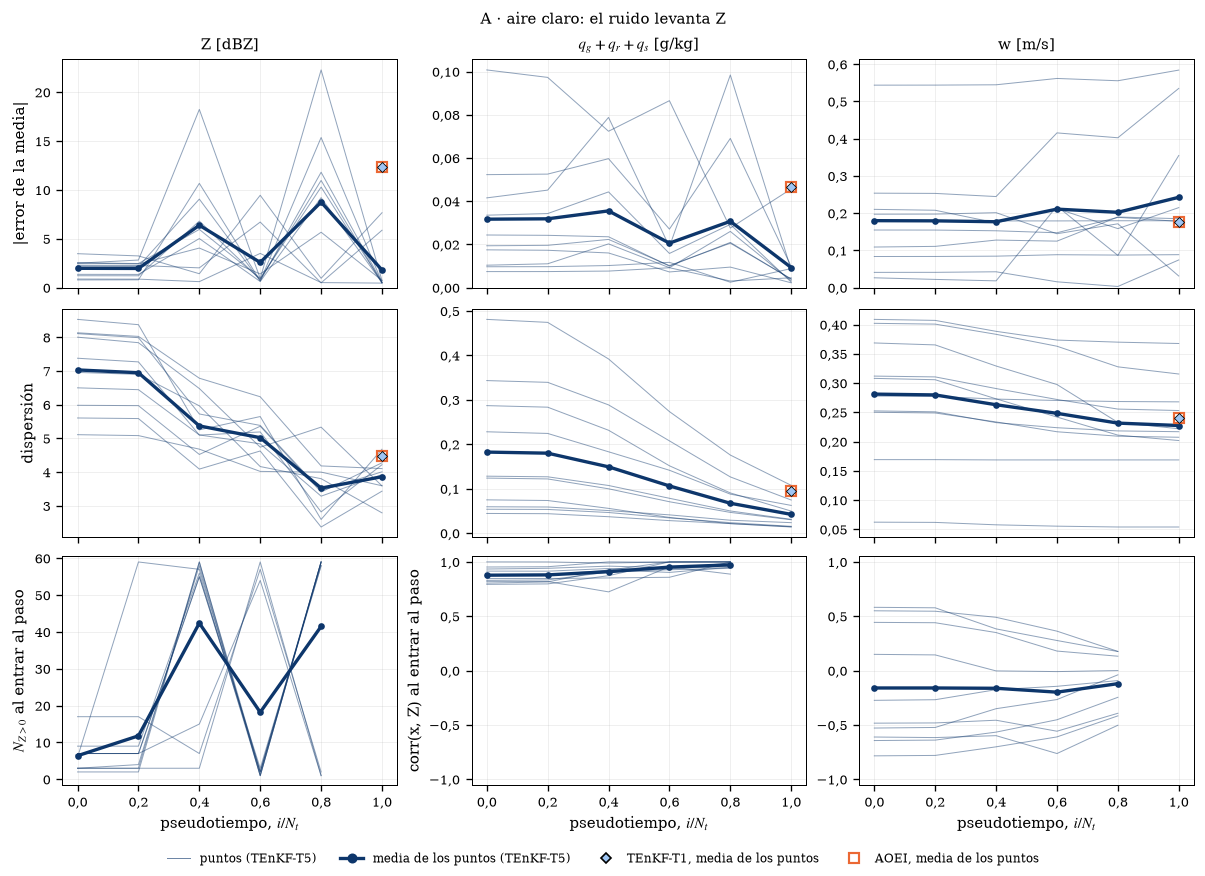

figures/es/N3s/failure/B_summary.png  figures/en/N3s/failure/B_summary.png


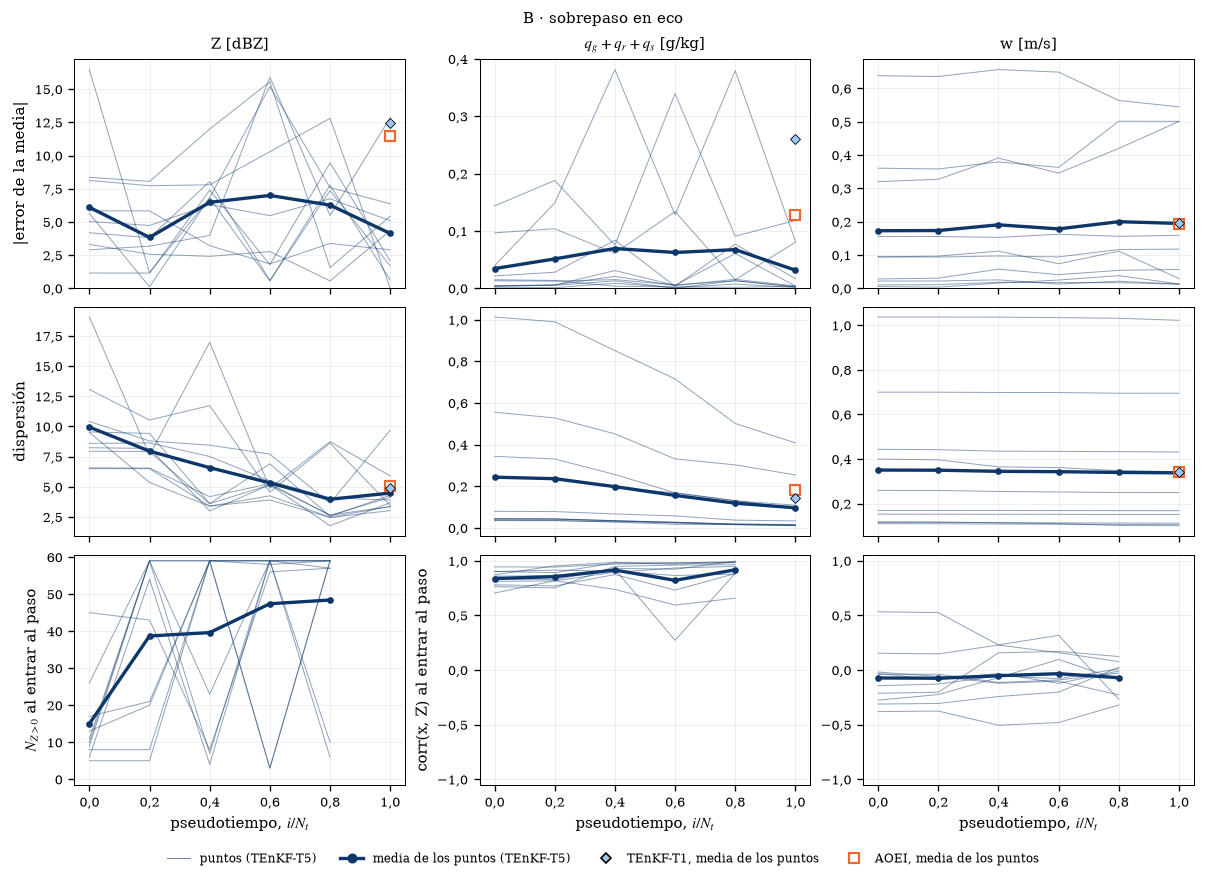

figures/es/N3s/failure/C1_summary.png  figures/en/N3s/failure/C1_summary.png


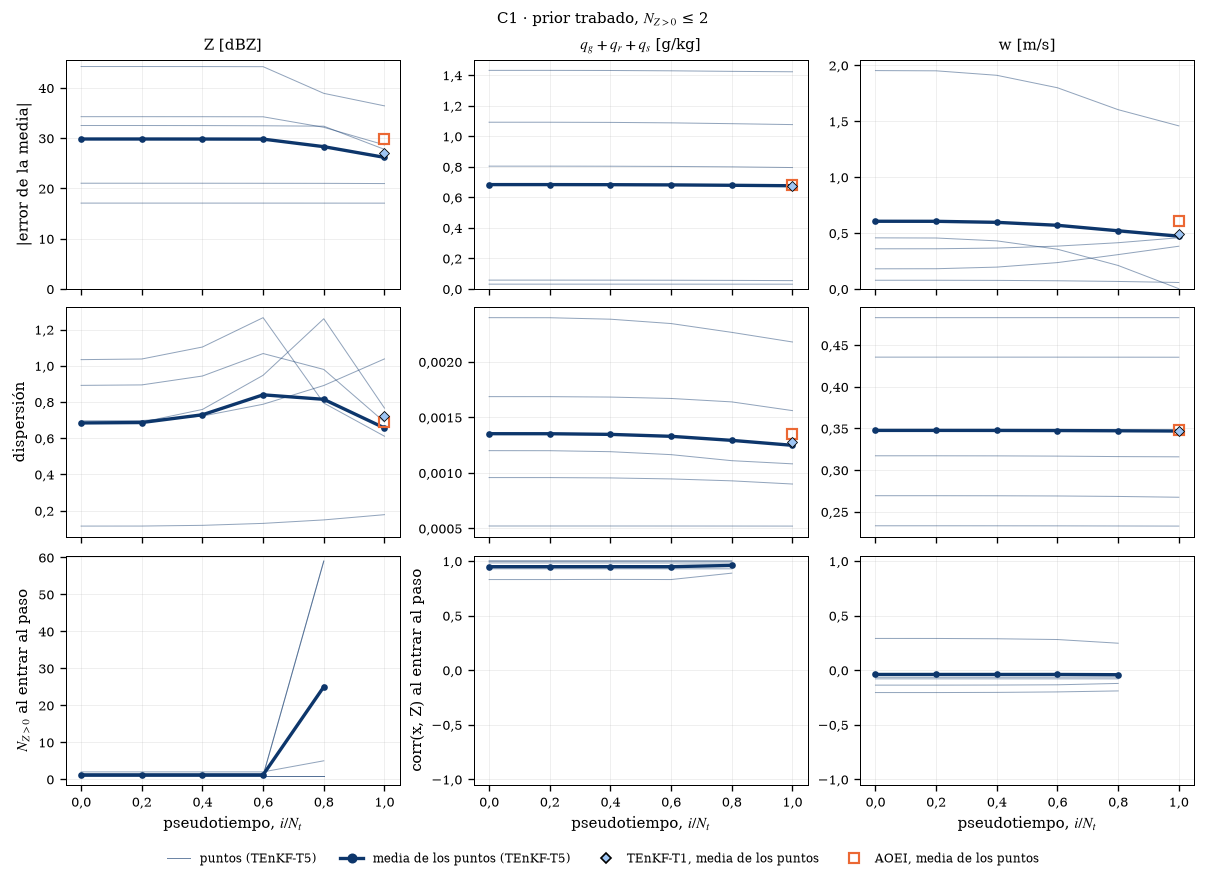

figures/es/N3s/failure/C2_summary.png  figures/en/N3s/failure/C2_summary.png


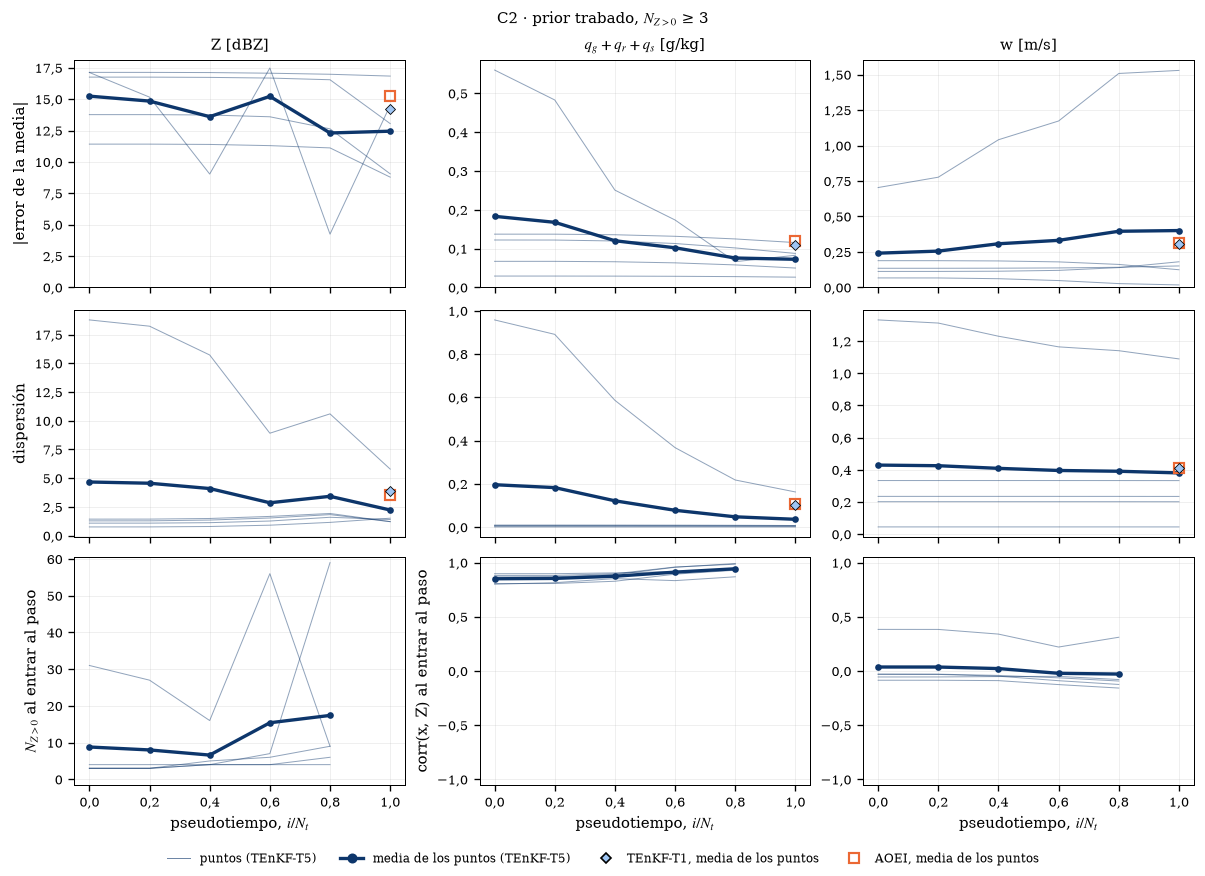

figures/es/N3s/failure/D_summary.png  figures/en/N3s/failure/D_summary.png


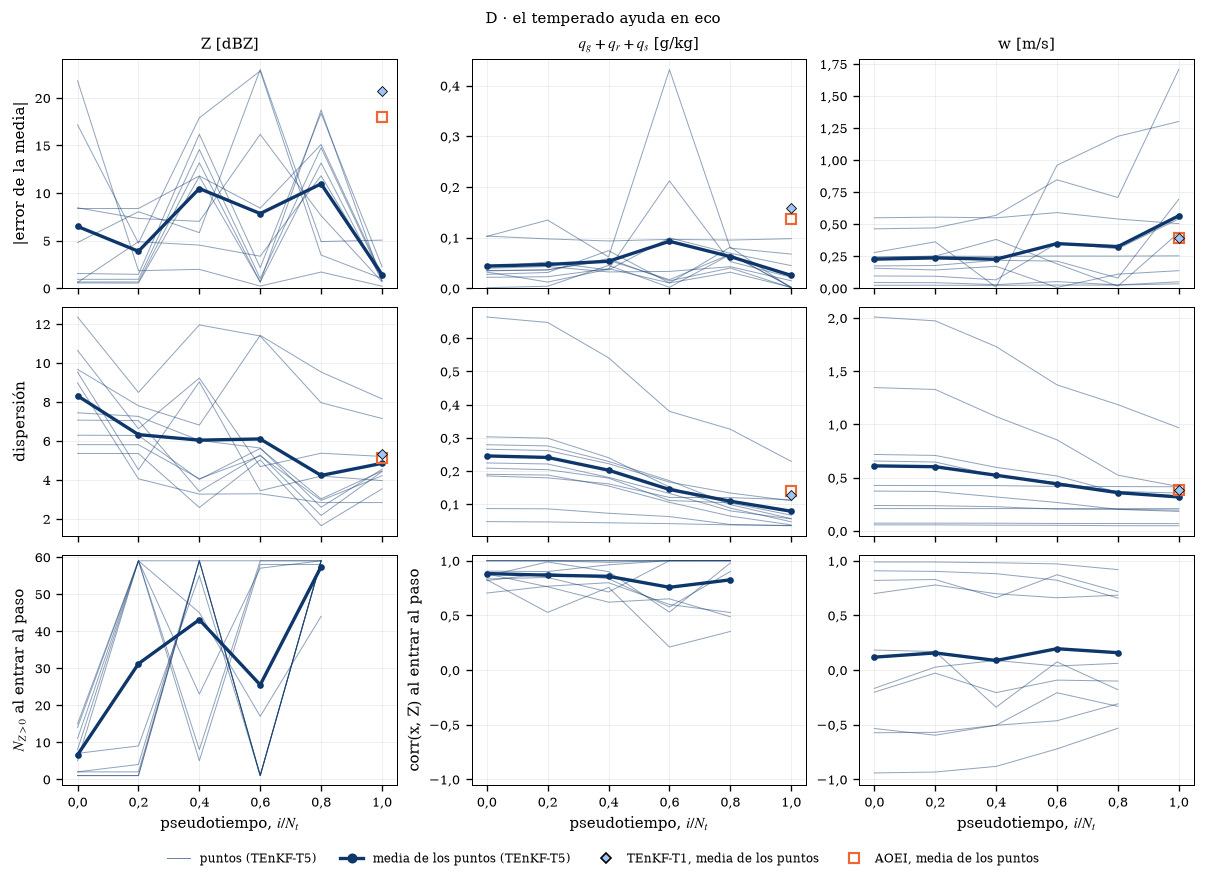

In [58]:
# Figuras: los nombres de las clases en LABELS (en memoria; la celda de LABELS no cambia), A1 y A2 por punto con las
# funciones de la sección 9 y un resumen por clase con draw_summary de la sección 6.
F_NAMES = {
    "es": {"A": "A · aire claro: el ruido levanta Z", "B": "B · sobrepaso en eco",
           "C1": "C1 · prior trabado, $N_{Z>0}$ ≤ 2", "C2": "C2 · prior trabado, $N_{Z>0}$ ≥ 3",
           "D": "D · el temperado ayuda en eco"},
    "en": {"A": "A · clear air: noise lifts Z", "B": "B · overshoot in echo",
           "C1": "C1 · stuck prior, $N_{Z>0}$ ≤ 2", "C2": "C2 · stuck prior, $N_{Z>0}$ ≥ 3",
           "D": "D · tempering helps in echo"},
}
for lang in nb.LANGS:
    LABELS[lang].update({f"cond_{c}": n for c, n in F_NAMES[lang].items()})
STEPS.update(STEPS_F)                     # draw_point y traj_panel buscan el punto en STEPS


def draw_summary_f(lang, cls):
    """El resumen de la sección 6 (draw_summary, que toma los puntos de SEL) para una clase de SEL_F."""
    global SEL
    keep, SEL = SEL, SEL_F
    try:
        fig = draw_summary(lang, cls)
    finally:
        SEL = keep
    fig.suptitle(LABELS[lang][f"cond_{cls}"], fontsize=9)
    return fig


import contextlib, io
t0 = time.time()
for r in SEL_F.itertuples(index=False):
    for suffix, draw in (("A1", draw_point_a1), ("A2", draw_vars_a2)):
        with contextlib.redirect_stdout(io.StringIO()):
            nb.save(lambda lang, r=r, draw=draw: draw(lang, r), f"N3s/failure/{r.condition}/{point_name(r)}_{suffix}",
                    show=False)
print(f"{len(nb.LANGS) * 2 * len(SEL_F)} figuras A1 y A2 en figures/<idioma>/N3s/failure/<clase>/, "
      f"{time.time() - t0:.0f} s")
for c in F_CLASSES:
    nb.save(lambda lang, c=c: draw_summary_f(lang, c), f"N3s/failure/{c}_summary", show=SHOW)
    plt.show()

In [59]:
# Las tablas de la sección 7 para los 40 puntos (las mismas cuentas, sobre SEL_F)
rows, steprows, signrows, clrows = [], [], [], []
for r in SEL_F.itertuples(index=False):
    cond, P_ = r.condition, STEPS_F[point_name(r)]
    yc = float(P_["yo_clean"])
    H, dep, Reff = z_steps(P_, "TEnKF", 5)
    e = H.mean(1) - yc
    rows.append(dict(condition=cond, n_prior=int((H[0] > DBZ_MIN).sum()), n_step1=int((H[1] > DBZ_MIN).sum()),
                     e_prior=e[0], e_step1=e[1], e_final=e[-1]))
    for it in range(len(dep)):
        h_in, h_out = H[it], H[it + 1]
        var = h_in.var(ddof=1)
        floor = h_in <= DBZ_MIN
        steprows.append(dict(condition=cond, step=it + 1, d=dep[it], pred=var / (var + Reff[it]) * dep[it],
                             real=h_out.mean() - h_in.mean(), floor=(h_out - h_in)[floor].sum() / h_in.size,
                             n_floor_in=int(floor.sum())))
    for nt in (2, 3, 4, 5):
        en = z_steps(P_, "TEnKF", nt)[0].mean(1) - yc
        for a, b in zip(en[:-1], en[1:]):
            signed = abs(a) > SIGN_TOL and abs(b) > SIGN_TOL
            signrows.append(dict(condition=cond, ntemp=nt, signed=signed, flip=signed and a * b < 0))
    tru = truth_of(P_)
    for c, (meth, nt) in enumerate((str(a), int(b)) for a, b in zip(P_["per_step/method"], P_["per_step/ntemp"])):
        row = dict(condition=cond, scheme="AOEI" if meth == "AOEI" else f"TEnKF-T{nt}")
        for mode in CLAMP_MODES:
            X = P_[f"{mode}/c{c:02d}_state_post_clamp"][-1].astype(float)
            vals = {"Z": P_[f"{mode}/c{c:02d}_hx"][-1].astype(float).mean(),
                    "qtot": X[:, IQ].sum(1).mean() * 1e3, "w": X[:, nb.VI["w"]].mean()}
            row |= {f"{v}_{mode}": x_ for v, x_ in vals.items()}
        for v in TVARS:
            row[f"Δ {v}"] = row[f"{v}_final"] - row[f"{v}_per_step"]
            row[f"Δ|e| {v}"] = abs(row[f"{v}_final"] - tru[v]) - abs(row[f"{v}_per_step"] - tru[v])
        clrows.append(row)
ford = {c: q for q, c in enumerate(F_CLASSES)}
key_ = lambda i: i.map(ford) if i.name == "condition" else i
t = pd.DataFrame(rows).groupby("condition").agg(
    puntos=("n_prior", "size"), N_prior=("n_prior", "mean"), N_paso1=("n_step1", "mean"),
    e_prior=("e_prior", "mean"), e_paso1=("e_step1", "mean"), e_final=("e_final", "mean"),
    abs_e_prior=("e_prior", lambda v: v.abs().mean()), abs_e_paso1=("e_step1", lambda v: v.abs().mean()),
    abs_e_final=("e_final", lambda v: v.abs().mean())).sort_index(key=key_)
print("TEnKF-T5, media sobre los puntos de cada clase. N_Z>0 de 59; error de Z [dBZ] = media − verdad")
print(t.to_string(float_format=lambda v: f"{v:.2f}"))
g = pd.DataFrame(steprows).groupby(["condition", "step"]).agg(
    d=("d", "mean"), previsto=("pred", "mean"), realizado=("real", "mean"), desde_el_piso=("floor", "mean"),
    miembros_en_el_piso=("n_floor_in", "mean"))
g["parte_del_piso"] = (g.desde_el_piso / g.realizado).where(g.realizado.abs() >= 0.1)
print("\nTEnKF-T5: cambio de la media de Z en cada paso [dBZ], media sobre los puntos")
print(g.sort_index(level=0, key=key_).to_string(float_format=lambda v: f"{v:.2f}"))
sgf = pd.DataFrame(signrows).groupby(["condition", "ntemp"]).agg(pares=("flip", "size"), con_signo=("signed", "sum"),
                                                                 cambian=("flip", "sum"))
sgf["% de los pares"] = 100 * sgf.cambian / sgf.pares
print("\nCambio de signo del error de Z entre pasos consecutivos (incluido prior → paso 1)")
print(sgf.sort_index(level=0, key=key_).to_string(float_format=lambda v: f"{v:.0f}"))
cols = [f"Δ {v}" for v in TVARS] + [f"Δ|e| {v}" for v in TVARS]
cl = pd.DataFrame(clrows).groupby(["condition", "scheme"], sort=False)[cols].mean()
print("\nCensura al final − censura en cada paso, media sobre los puntos (Z [dBZ], q_g+q_r+q_s [g/kg], w [m/s])")
print(cl.sort_index(level=0, key=key_, sort_remaining=False).to_string(float_format=lambda v: f"{v:+.4f}"))

TEnKF-T5, media sobre los puntos de cada clase. N_Z>0 de 59; error de Z [dBZ] = media − verdad
           puntos  N_prior  N_paso1  e_prior  e_paso1  e_final  abs_e_prior  abs_e_paso1  abs_e_final
condition                                                                                            
A              10     6.40    11.80     1.98     1.97     1.81         1.98         1.97         1.81
B              10    15.00    38.70    -5.44    -1.07     1.26         6.10         3.83         4.14
C1              5     1.20     1.20   -29.84   -29.84   -26.18        29.84        29.84        26.18
C2              5     8.80     8.00    -8.39    -8.78    -6.64        15.24        14.84        12.44
D              10     6.60    31.20    -6.24     1.25     0.02         6.50         3.89         1.45

TEnKF-T5: cambio de la media de Z en cada paso [dBZ], media sobre los puntos
                   d  previsto  realizado  desde_el_piso  miembros_en_el_piso  parte_del_piso
condition step     

In [60]:
# El zigzag (sección 9.9) en los 40 puntos
rows = []
for r in SEL_F.itertuples(index=False):
    P_ = STEPS_F[point_name(r)]
    H, _, _ = z_steps(P_, "TEnKF", 5)
    e = H.mean(1) - float(P_["yo_clean"])
    s = np.where(np.abs(e) > SIGN_TOL, np.sign(e), 0.0)
    rows.append({"clase": r.condition, "punto": point_name(r), "y_o": float(P_["yo"]),
                 "cambios": int((s[:-1] * s[1:] < 0).sum()), "N_Z=0 prior": int((P_["hxf_point"] <= DBZ_MIN).sum()),
                 "Z_t": float(P_["yo_clean"]), "e T5": " ".join(f"{v:+.1f}" for v in e)})
ZGF = pd.DataFrame(rows)
ZGF.insert(2, "banda y_o", yo_band(ZGF.y_o))
print("Zigzag de TEnKF-T5 en los 40 puntos; e T5: error de la media de Z en el prior y después de cada paso [dBZ]")
print(ZGF.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\npor clase")
print(ZGF.groupby("clase", sort=False).agg(puntos=("punto", "size"), con_cambios=("cambios", lambda v: int((v > 0).sum())),
                                           cambios_medios=("cambios", "mean"), N_Z0_mediana=("N_Z=0 prior", "median"))
      .to_string(float_format=lambda v: f"{v:.2f}"))
print("\npor banda de y_o [dBZ]")
print(ZGF.groupby("banda y_o", observed=True).agg(
    puntos=("punto", "size"), con_cambios=("cambios", lambda v: int((v > 0).sum())),
    cambios_medios=("cambios", "mean"), clases=("clase", lambda v: ", ".join(sorted(set(v)))))
      .to_string(float_format=lambda v: f"{v:.2f}"))

Zigzag de TEnKF-T5 en los 40 puntos; e T5: error de la media de Z en el prior y después de cada paso [dBZ]
clase              punto banda y_o   y_o  cambios  N_Z=0 prior   Z_t                                e T5
    A   A_130_420_5_tm12   (0, 10)  5.88        0           53  0.00     +2.5 +2.8 +18.2 +0.9 +22.3 +0.7
    A    A_20_350_4_tm24   (0, 10)  4.36        0           56  0.00      +1.2 +1.2 +6.8 +0.8 +11.0 +0.5
    A   A_120_220_5_tm59   (0, 10)  1.44        0           57  0.00     +0.8 +0.8 +10.7 +0.7 +11.8 +0.6
    A   A_150_130_0_tm33   (0, 10)  2.00        0           52  0.00       +2.5 +2.4 +4.1 +1.4 +5.7 +0.7
    A    A_50_120_1_tm52   (0, 10)  0.96        0           56  0.00       +0.9 +0.9 +0.6 +3.5 +0.5 +0.5
    A   A_300_300_4_tm38   (0, 10)  2.28        0           52  0.00      +2.5 +2.5 +6.0 +0.9 +10.3 +0.5
    A    A_150_70_4_tm03   (0, 10)  1.71        0           56  0.00       +1.4 +1.4 +5.0 +0.6 +9.2 +0.5
    A  A_160_340_10_tm36   (0, 10)  1.65        0    

## 13 · Tres comprobaciones sobre los 100 puntos (solo tablas)

Los 60 puntos de las secciones 2–9 y los 40 de la sección 12, con sus corridas guardadas; sin corridas nuevas.

- **a · Oscilación por cambios de dirección.** El cambio de signo del error de $Z$ (sección 7) no ve el zigzag en aire claro: con $Z_t$ = 0 el error de la media nunca es negativo. Acá se cuenta cuántas veces la media de $Z$ cambia de dirección entre pasos (sube y después baja, o al revés), sin mirar la verdad: de los cambios de la media entre pasos consecutivos de TEnKF-T$N_t$ (incluido prior → paso 1), se dejan los mayores que una tolerancia y se cuentan los pares seguidos de signo opuesto. Con dos tolerancias: 10⁻³ dBZ (`SIGN_TOL`) y 1 dBZ. Y el camino de más: $\sum_i |\Delta_i| - |\sum_i \Delta_i|$, lo que la media recorre de más respecto de ir derecho del prior al final [dBZ].
- **b · Error final por $N_t$ y lado del sobrepaso.** $|e|$ de la media de $Z$ al final con TEnKF-T1 a T5 y AOEI; y en cuántos puntos la media final queda del otro lado de la verdad que el prior (cruza), de cuál lado (arriba, $e > 0$, o abajo), y en cuántos de esos además $|e_a| > |e_f|$.
- **c · Los puntos de la clase A cerca del borde oeste.** 6 de los 10 puntos A de la selección por regiones (sección 12; después A y B se eligen sin regiones) están a menos de 30 celdas del borde oeste. El subset es un recorte del dominio de WRF (empieza 140 celdas adentro: `i_start` en `configs/build_3D_section_Dataset_A.yaml`), así que ese borde no es una frontera lateral del modelo. Se compara, por distancia al borde oeste, cuántos experimentos hay, cuántos en aire claro y qué fracción del aire claro es de la clase A.

In [61]:
# a · Cambios de dirección de la media de Z entre pasos consecutivos
REV_TOLS = (SIGN_TOL, 1.0)                     # dBZ
PTS100 = ([(r.condition, point_name(r), STEPS[point_name(r)]) for r in SEL.itertuples(index=False)]
          + [(r.condition, point_name(r), STEPS_F[point_name(r)]) for r in SEL_F.itertuples(index=False)])
GROUPS100 = list(CONDITIONS) + list(F_CLASSES)
g100 = {g: q for q, g in enumerate(GROUPS100)}


def reversals(m, tol):
    """Cambios de dirección de la serie m: entre los cambios consecutivos mayores que tol, los pares seguidos de
    signo opuesto (un cambio menor que tol no corta la cuenta)."""
    d = np.diff(m)
    s = np.sign(d[np.abs(d) > tol])
    return int((s[:-1] * s[1:] < 0).sum())


rows = []
for grp, name, P_ in PTS100:
    yc = float(P_["yo_clean"])
    for nt in (2, 3, 4, 5):
        m = z_steps(P_, "TEnKF", nt)[0].mean(1)                       # media de Z: prior, paso 1, ..., paso N_t
        e = m - yc
        se = np.where(np.abs(e) > SIGN_TOL, np.sign(e), 0.0)
        d = np.diff(m)
        rows.append({"grupo": grp, "punto": name, "N_t": nt, "cambios de signo": int((se[:-1] * se[1:] < 0).sum()),
                     **{f"cambios de dirección (>{tol:g})": reversals(m, tol) for tol in REV_TOLS},
                     "camino de más": float(np.abs(d).sum() - abs(d.sum()))})
OSC = pd.DataFrame(rows)
rev1 = f"cambios de dirección (>{REV_TOLS[1]:g})"
t = OSC.groupby(["grupo", "N_t"]).agg(**{
    "cambios de signo": ("cambios de signo", "sum"),
    **{c: (c, "sum") for c in OSC.columns if c.startswith("cambios de dirección")},
    "puntos con dirección (>1)": (rev1, lambda v: int((v > 0).sum())),
    "camino de más, media": ("camino de más", "mean"), "camino de más, máx": ("camino de más", "max")})
print("TEnKF-T_Nt, suma sobre los puntos de cada grupo (10, o 5 en C1 y C2); camino de más en dBZ")
print(t.sort_index(level=0, key=lambda i: i.map(g100) if i.name == "grupo" else i)
      .to_string(float_format=lambda v: f"{v:.1f}"))
o5 = OSC[OSC.N_t == 5]
miss = o5[(o5["cambios de signo"] == 0) & (o5[rev1] > 0)]
print(f"\nTEnKF-T5: puntos con algún cambio de dirección (> 1 dBZ) pero sin cambio de signo del error: {len(miss)} — "
      + ", ".join(f"{g} {n}" for g, n in miss.groupby("grupo", sort=False).size().items()))
print("\nesos puntos, T5:")
print(miss.drop(columns="N_t").to_string(index=False, float_format=lambda v: f"{v:.1f}"))

TEnKF-T_Nt, suma sobre los puntos de cada grupo (10, o 5 en C1 y C2); camino de más en dBZ
               cambios de signo  cambios de dirección (>0.001)  cambios de dirección (>1)  puntos con dirección (>1)  camino de más, media  camino de más, máx
grupo     N_t                                                                                                                                                 
core      2                   0                              0                          0                          0                   0.0                 0.0
          3                   0                              0                          0                          0                   0.0                 0.0
          4                   0                              2                          2                          1                   0.8                 8.3
          5                   0                              2                          2                         

In [62]:
# b · |e| final por N_t y de qué lado de la verdad queda la media final
SCHEMES_B = [("TEnKF", n, f"T{n}") for n in (1, 2, 3, 4, 5)] + [("AOEI", 1, "AOEI")]
rows = []
for grp, name, P_ in PTS100:
    yc = float(P_["yo_clean"])
    e_f = float(P_["hxf_point"].astype(float).mean()) - yc
    for meth, nt, lab in SCHEMES_B:
        e_a = float(z_steps(P_, meth, nt)[0][-1].mean()) - yc
        signed = abs(e_f) > SIGN_TOL and abs(e_a) > SIGN_TOL
        rows.append(dict(grupo=grp, punto=name, esquema=lab, e_f=e_f, e_a=e_a, cruza=signed and e_f * e_a < 0,
                         arriba=e_a > SIGN_TOL, peor=abs(e_a) - abs(e_f) > SIGN_TOL))
FIN = pd.DataFrame(rows)
order_s = [lab for _, _, lab in SCHEMES_B]
key_g = lambda i: i.map(g100)
ae = FIN.assign(abs_e_a=FIN.e_a.abs()).pivot_table(index="grupo", columns="esquema", values="abs_e_a", aggfunc="mean")
ae["prior"] = FIN[FIN.esquema == "T1"].groupby("grupo").e_f.apply(lambda v: v.abs().mean())
print("|e| de la media de Z al final [dBZ], media sobre los puntos de cada grupo")
print(ae[["prior"] + order_s].sort_index(key=key_g).to_string(float_format=lambda v: f"{v:.2f}"))
cr = FIN.groupby(["grupo", "esquema"]).agg(cruzan=("cruza", "sum"),
                                           cruzan_arriba=("cruza", lambda v: int((v & FIN.loc[v.index, "arriba"]).sum())),
                                           cruzan_y_empeoran=("cruza", lambda v: int((v & FIN.loc[v.index, "peor"]).sum())),
                                           final_arriba=("arriba", "sum"), puntos=("cruza", "size"))
cr = cr.reset_index().pivot(index="grupo", columns="esquema")
cr = cr.reindex(columns=pd.MultiIndex.from_product([["cruzan", "cruzan_arriba", "cruzan_y_empeoran"], order_s]))
print("\nPuntos cuya media final cruza la verdad respecto del prior; de ellos, los que quedan arriba (e > 0) y los que "
      "además empeoran (|e_a| > |e_f|)")
print(cr.sort_index(key=key_g).to_string())
pr_side = FIN[FIN.esquema == "T1"].groupby("grupo").agg(prior_arriba=("e_f", lambda v: int((v > SIGN_TOL).sum())),
                                                        prior_abajo=("e_f", lambda v: int((v < -SIGN_TOL).sum())),
                                                        puntos=("e_f", "size"))
print("\nlado del prior respecto de la verdad (e_f > 0: arriba), puntos:")
print(pr_side.sort_index(key=key_g).T.to_string())

|e| de la media de Z al final [dBZ], media sobre los puntos de cada grupo
esquema    prior    T1    T2    T3    T4    T5  AOEI
grupo                                               
core       41.03 10.92  9.24  9.13  9.41 10.11 26.13
edge        8.26  6.56  4.20  4.37  3.82  3.72  5.25
updraft    48.15 16.82 15.78 15.94 16.00 16.07 35.05
downdraft  43.94 12.27 11.38 13.25 12.16 12.18 34.57
weak        1.76  0.96  0.90  0.89  0.89  0.88  0.94
clear       2.77  4.35  3.87  2.55  0.57  2.72  4.35
A           1.98 12.34  2.04  6.70  7.89  1.81 12.34
B           6.10 12.41  6.40 10.34  6.64  4.14 11.44
C1         29.84 26.98 26.40 26.20 26.20 26.18 29.84
C2         15.24 14.22 14.34 10.74 12.51 12.44 15.25
D           6.50 20.70  4.66 16.69  6.83  1.45 18.04

Puntos cuya media final cruza la verdad respecto del prior; de ellos, los que quedan arriba (e > 0) y los que además empeoran (|e_a| > |e_f|)
          cruzan                   cruzan_arriba                  cruzan_y_empeoran           

In [63]:
# c · La clase A por distancia al borde oeste del subset (i, en celdas de 4 km)
W_BINS = [0, 10, 30, 60, 100, 200, NX]
W_LAB = ["[0, 10)", "[10, 30)", "[30, 60)", "[60, 100)", "[100, 200)", f"[200, {NX})"]
clear_t = EXP.yo_clean <= DBZ_MIN
band = pd.cut(EXP.i, W_BINS, right=False, labels=W_LAB)
tab = pd.DataFrame({"experimentos": EXP.groupby(band, observed=False).size(),
                    "aire claro (Z_t = 0)": clear_t.groupby(band, observed=False).sum(),
                    "clase A": FCLS["A"].groupby(band, observed=False).sum()})
tab["% del aire claro que es A"] = 100 * tab["clase A"] / tab["aire claro (Z_t = 0)"]
tab["% de A"] = 100 * tab["clase A"] / tab["clase A"].sum()
tab["% del aire claro"] = 100 * tab["aire claro (Z_t = 0)"] / tab["aire claro (Z_t = 0)"].sum()
cl = EXP[clear_t]
cband = pd.cut(cl.i, W_BINS, right=False, labels=W_LAB)
tab["aire claro: y_o mediana"] = cl.yo.groupby(cband, observed=False).median()
tab["aire claro: N_Z>0 mediana"] = cl.n_active_f_point.groupby(cband, observed=False).median()
tab["A: |e_a|−|e_f| mediana"] = EXP.loc[FCLS["A"], "peor"].groupby(band[FCLS["A"]], observed=False).median()
print("Por distancia al borde oeste (i, celdas):")
print(tab.to_string(float_format=lambda v: f"{v:.1f}"))
p30 = float(FCLS["A"][EXP.i < 30].sum() / FCLS["A"].sum())
print(f"\nfracción de los candidatos A con i < 30: {p30:.2f}; con 10 puntos al azar, esperados {10 * p30:.1f} "
      f"(la selección, un punto por región, eligió {int((SEL_F1[SEL_F1.condition == 'A'].i < 30).sum())})")
edge = np.minimum.reduce([EXP.i, NX - 1 - EXP.i, EXP.j, NY - 1 - EXP.j])
eb = pd.cut(edge, [0, 10, 30, 60, 1000], right=False, labels=["< 10", "[10, 30)", "[30, 60)", "≥ 60"])
print("\nPor distancia al borde más cercano (cualquiera de los cuatro), % del aire claro que es A:")
print((100 * FCLS["A"].groupby(eb, observed=False).sum() / clear_t.groupby(eb, observed=False).sum())
      .to_frame("% del aire claro que es A").T.to_string(float_format=lambda v: f"{v:.1f}"))
print("\nlos 10 puntos A:")
print(SEL_F1[SEL_F1.condition == "A"][["i", "j", "k", "m", "region", "y_o", "n_echo", "e_f", "e_a1", "e_a5"]]
      .to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# ¿De dónde sale la concentración? La regla de un punto por región, sobre las regiones de la reserva de la sección 12
# (los candidatos de la clase sin las celdas de los 60 puntos; la exclusión entre clases no cambia las regiones).
cells60 = {(int(i), int(j), int(k)) for i, j, k in SEL[["i", "j", "k"]].itertuples(index=False)}
for c in ("A", "B"):
    cand = EXP[FCLS[c]]
    cand = cand[[(i, j, k) not in cells60 for i, j, k in cand[["i", "j", "k"]].itertuples(index=False)]]
    cols_c = np.zeros((NXC, NYC), bool)
    cols_c[cand.i.to_numpy() // STRIDE, cand.j.to_numpy() // STRIDE] = True
    lab, n_reg = ndimage.label(cols_c, structure=EIGHT)
    reg = pd.DataFrame({"región": lab[cand.i.to_numpy() // STRIDE, cand.j.to_numpy() // STRIDE], "i": cand.i.to_numpy()})
    t = reg.groupby("región").agg(experimentos=("i", "size"), i_mín=("i", "min"), i_máx=("i", "max"))
    t["columnas"] = [int((lab == g).sum()) for g in t.index]
    t["elegido"] = t.index.isin(SEL_F1[SEL_F1.condition == c].region)
    big = t.experimentos.idxmax()
    print(f"\n{c}: {n_reg} regiones; la mayor tiene el {100 * t.experimentos[big] / len(cand):.1f} % de los candidatos "
          f"y aporta {int(t.elegido[big])} de los {F_N[c]} puntos")
    print(t.to_string())

Por distancia al borde oeste (i, celdas):
            experimentos  aire claro (Z_t = 0)  clase A  % del aire claro que es A  % de A  % del aire claro  aire claro: y_o mediana  aire claro: N_Z>0 mediana  A: |e_a|−|e_f| mediana
i                                                                                                                                                                                       
[0, 10)             4946                  4670      588                       12.6     0.6               0.9                      0.0                        2.0                     6.4
[10, 30)           11487                 10922     1406                       12.9     1.4               2.2                      0.0                        1.0                     8.3
[30, 60)           24693                 23363     4695                       20.1     4.5               4.6                      0.0                        2.0                    10.2
[60, 100)          49191         

## 14 · A y B: la selección por regiones y la nueva

Las tablas de las secciones 12 y 13 para las clases A y B, con los puntos de la selección por regiones («regiones», guardados en `failure/old_region/`) junto a los nuevos, elegidos sin regiones a más de `SEP_KM` entre sí (sección 12). Las corridas de los dos grupos son las de la sección 12.

In [64]:
STEPS_OLD_AB = {point_name(r): dict(np.load(F_OLD / "steps" / f"{point_name(r)}.npz"))
                for r in SEL_F1[SEL_F1.condition.isin(AB)].itertuples(index=False)}
AB_GROUPS = []                                     # (grupo, filas de la selección, archivos de los puntos)
for c in AB:
    AB_GROUPS += [(f"{c} · regiones", SEL_F1[SEL_F1.condition == c], STEPS_OLD_AB),
                  (f"{c} · nueva", SEL_F[SEL_F.condition == c], STEPS_F)]


def ab_metrics(P_):
    """Por punto: las cuentas de las tablas de las secciones 12 y 13 (T5, salvo donde se dice)."""
    yc = float(P_["yo_clean"])
    H5 = z_steps(P_, "TEnKF", 5)[0]
    e5 = H5.mean(1) - yc
    out = dict(N_prior=int((H5[0] > DBZ_MIN).sum()), N_paso1=int((H5[1] > DBZ_MIN).sum()), e_prior=e5[0],
               e_paso1=e5[1], e_final=e5[-1], N_Z0=int((P_["hxf_point"] <= DBZ_MIN).sum()), y_o=float(P_["yo"]))
    for nt in (2, 3, 4, 5):
        m = z_steps(P_, "TEnKF", nt)[0].mean(1)
        se = np.where(np.abs(m - yc) > SIGN_TOL, np.sign(m - yc), 0.0)
        d = np.diff(m)
        out |= {f"signo T{nt}": int((se[:-1] * se[1:] < 0).sum()), f"dirección T{nt}": reversals(m, REV_TOLS[1]),
                f"camino T{nt}": float(np.abs(d).sum() - abs(d.sum()))}
    for meth, nt, lab in SCHEMES_B:
        e_a = float(z_steps(P_, meth, nt)[0][-1].mean()) - yc
        out |= {f"|e| {lab}": abs(e_a), f"cruza {lab}": bool(abs(e5[0]) > SIGN_TOL and abs(e_a) > SIGN_TOL and e5[0] * e_a < 0)}
    return out


rows = []
for g, sel, steps in AB_GROUPS:
    for r in sel.itertuples(index=False):
        x_, y_ = EXP.at[r.exp, "x_km"], EXP.at[r.exp, "y_km"]
        rows.append(dict(grupo=g, punto=point_name(r), i=r.i, m=r.m, x=x_, y=y_, **ab_metrics(steps[point_name(r)])))
ABM = pd.DataFrame(rows)
gord = [g for g, _, _ in AB_GROUPS]


def by_group(agg):
    return ABM.groupby("grupo").agg(**agg).reindex(gord)


def min_dist(g):
    xy = g[["x", "y"]].to_numpy(float)
    return min(np.hypot(*(a - b)) for a, b in itertools.combinations(xy, 2))


print("Selección")
sel_t = by_group({"puntos": ("punto", "size"), "miembros verdad": ("m", "nunique"),
                  "con i < 30": ("i", lambda v: int((v < 30).sum())), "y_o mediana": ("y_o", "median"),
                  "N_Z>0 mediana": ("N_prior", "median"), "N_Z=0 mediana": ("N_Z0", "median")})
sel_t["distancia mínima [km]"] = pd.Series({g: min_dist(x) for g, x in ABM.groupby("grupo")}).reindex(gord)
print(sel_t.to_string(float_format=lambda v: f"{v:.1f}"))
print("\nSección 12, tabla 1: TEnKF-T5, media sobre los 10 puntos. Error de Z [dBZ] = media − verdad")
print(by_group({"N_prior": ("N_prior", "mean"), "N_paso1": ("N_paso1", "mean"), "e_prior": ("e_prior", "mean"),
                "e_paso1": ("e_paso1", "mean"), "e_final": ("e_final", "mean"),
                "abs_e_prior": ("e_prior", lambda v: v.abs().mean()), "abs_e_paso1": ("e_paso1", lambda v: v.abs().mean()),
                "abs_e_final": ("e_final", lambda v: v.abs().mean())}).to_string(float_format=lambda v: f"{v:.2f}"))
print("\nOscilación por N_t (secciones 12 y 13a): cambios de signo del error y cambios de dirección de la media (> 1 dBZ), "
      "suma sobre los puntos; puntos con algún cambio de dirección; camino de más medio [dBZ]")
osc = {}
for nt in (2, 3, 4, 5):
    osc |= {(f"T{nt}", "signo"): (f"signo T{nt}", "sum"), (f"T{nt}", "dirección"): (f"dirección T{nt}", "sum"),
            (f"T{nt}", "puntos con dirección"): (f"dirección T{nt}", lambda v: int((v > 0).sum())),
            (f"T{nt}", "camino"): (f"camino T{nt}", "mean")}
t = ABM.groupby("grupo").agg(**{f"{a} · {b}": v for (a, b), v in osc.items()}).reindex(gord)
t.columns = pd.MultiIndex.from_tuples([tuple(c.split(" · ")) for c in t.columns])
print(t.to_string(float_format=lambda v: f"{v:.1f}"))
print("\nSección 13b: |e| de la media de Z al final [dBZ], media sobre los puntos; y puntos cuya media final cruza la verdad")
labs = [lab for _, _, lab in SCHEMES_B]
t = by_group({"prior": ("e_prior", lambda v: v.abs().mean()), **{lab: (f"|e| {lab}", "mean") for lab in labs},
              **{f"cruzan {lab}": (f"cruza {lab}", "sum") for lab in labs}})
print(t.to_string(float_format=lambda v: f"{v:.2f}"))
print("\nZigzag (sección 12): T5, puntos con algún cambio de signo y con algún cambio de dirección (> 1 dBZ)")
print(by_group({"con cambio de signo": ("signo T5", lambda v: int((v > 0).sum())),
                "con cambio de dirección": ("dirección T5", lambda v: int((v > 0).sum())),
                "cambios de signo medios": ("signo T5", "mean"), "cambios de dirección medios": ("dirección T5", "mean")})
      .to_string(float_format=lambda v: f"{v:.2f}"))

Selección
              puntos  miembros verdad  con i < 30  y_o mediana  N_Z>0 mediana  N_Z=0 mediana  distancia mínima [km]
grupo                                                                                                              
A · regiones      10               10           6          3.0            2.0           57.0                   82.5
A · nueva         10               10           1          2.1            6.5           52.5                  153.7
B · regiones      10               10           6         12.9            5.5           53.5                   79.7
B · nueva         10               10           0          9.3           10.5           48.5                  119.8

Sección 12, tabla 1: TEnKF-T5, media sobre los 10 puntos. Error de Z [dBZ] = media − verdad
              N_prior  N_paso1  e_prior  e_paso1  e_final  abs_e_prior  abs_e_paso1  abs_e_final
grupo                                                                                           
A · reg

## 15 · Corrida liviana del zigzag: diseño y prueba en 100 puntos

Para medir con muchos puntos de observación única cuándo y cuánto oscila el temperado, sin guardar ensambles.

- **Marco.** Los 565 366 experimentos de la sección 11 (4 km–5 min, 20 UTC, celdas del barrido, sin la celda no finita). Tienen salida del barrido, así que T1 y T5 de la corrida se verifican contra ella.
- **Estratos.** Banda de $y_o$ (0, (0, 10), [10, 20), [20, 30), [30, 40), ≥ 40 dBZ, las de la sección 9.9) × $N_{Z=0}$ del prior (< 30, 30–50, > 50 de 59): 18 estratos. Al azar dentro de cada estrato, con semilla fija, el mismo número de puntos por estrato (o todos los que haya). Las cuentas sobre todos los estratos juntos se pesan por el tamaño del estrato en el marco.
- **Corrida.** La de producción de un punto, como en la sección 4 (`setup_window` y `run_experiment._process_point`, TEnKF-T1 a T5 y AOEI), solo con la censura en cada paso. Del ensamble no se guarda nada; de cada punto:
  - para $N_t$ = 2 a 5, en cada paso (prior incluido): la media de $Z$, su dispersión, $N_{Z>0}$ y la media de $Z$ de los miembros que en el prior están en el límite de detección (NaN si no hay);
  - la oscilación para $N_t$ = 2 a 5, de tres maneras: cambios de signo del error de la media de $Z$, cambios de dirección de la media (movimientos > 1 dBZ, sección 13a) y camino de más;
  - $|e|$ final de la media de $Z$ con T1 a T5 y AOEI.
- **Prueba.** 100 puntos repartidos entre los 18 estratos, en `data/derived/N3s/zigzag/test_100.npz`. Se informa el costo, la fracción de puntos que oscilan por estrato y $|e|$ final por $N_t$ y estrato: si el error final depende de dónde cae el último paso de la oscilación, $|e|$ no baja con $N_t$ en los estratos que oscilan y depende de hacia dónde fue el último movimiento.

In [65]:
# Estratos del marco y muestra de la prueba
N0_CLASSES = ("< 30", "30–50", "> 50")
OUT_Z = OUT_S / "zigzag"
Z_TEST_N = 100
Z_FULL_PER = 200                         # puntos por estrato en la corrida completa (propuesta)
n0_ = NE - EXP.n_active_f_point          # miembros del prior en Z = 0 (de 59)
EXP["banda y_o"] = yo_band(EXP.yo)
EXP["N_Z=0"] = pd.Categorical(np.select([n0_ < 30, n0_ <= 50], N0_CLASSES[:2], N0_CLASSES[2]), categories=N0_CLASSES,
                              ordered=True)
FRAME = EXP.groupby(["banda y_o", "N_Z=0"], observed=False).size().rename("experimentos")
print("Experimentos del marco por estrato")
print(FRAME.unstack("N_Z=0").to_string())
strata = [s for s in FRAME.index if FRAME[s] > 0]
alloc = {s: Z_TEST_N // len(strata) + (q < Z_TEST_N % len(strata)) for q, s in enumerate(strata)}
assert sum(alloc.values()) == Z_TEST_N and all(alloc[s] <= FRAME[s] for s in strata)
rng_z = np.random.default_rng(SEED)
parts = []
for s in strata:
    pool = EXP.index[(EXP["banda y_o"] == s[0]) & (EXP["N_Z=0"] == s[1])].to_numpy()
    parts.append(pool[rng_z.choice(len(pool), alloc[s], replace=False)])
ZT_IDX = np.concatenate(parts)
ZTEST = EXP.loc[ZT_IDX, ["i", "j", "k", "tm", "yo", "yo_clean", "dep_b", "n_active_f_point", "hxa_T1", "hxa_T5",
                         "banda y_o", "N_Z=0"]].rename(columns={"tm": "m"}).reset_index(names="exp")
ZTEST["peso"] = ZTEST.apply(lambda r: FRAME[(r["banda y_o"], r["N_Z=0"])], axis=1) / ZTEST.groupby(
    ["banda y_o", "N_Z=0"], observed=True)["exp"].transform("size")
n_full = int(np.minimum(FRAME, Z_FULL_PER).sum())
print(f"\nprueba: {len(ZTEST)} puntos en {len(strata)} estratos ({min(alloc.values())}–{max(alloc.values())} por estrato); "
      f"corrida completa propuesta: {Z_FULL_PER} por estrato = {n_full:,} puntos")

Experimentos del marco por estrato
N_Z=0       < 30  30–50    > 50
banda y_o                      
0 (límite)  1571  50733  200998
(0, 10)     3943  55798  206902
[10, 20)    3902   6392    7038
[20, 30)    2779   5315    5401
[30, 40)    1558   3677    3544
≥ 40        1037   2513    2265

prueba: 100 puntos en 18 estratos (5–6 por estrato); corrida completa propuesta: 200 por estrato = 3,600 puntos


In [73]:
# La corrida liviana de un punto y la prueba
Z_NT = (2, 3, 4, 5)
Z_KEYS = ("mean", "spread", "n_echo", "floor_mean")       # por paso: media, dispersión, N_Z>0, media del piso


def light_point(i, j, k, m):
    """Un punto con la corrida de producción (censura en cada paso); solo los resúmenes, ningún ensamble."""
    ic, jc = setup_window(i, j, m)
    hxf = np.asarray(rx._ENS_HX[ic, jc, k], np.float64)
    yc = float(rx._TRUTH_HX[ic, jc, k])
    _, _, blocks = rx._process_point(ic, jc, k, COMBOS, VAR_IDX, R, CUTOFF, return_fields=False, dbz_min=DBZ_MIN,
                                     capture_steps=True, clamp_mode="per_step")
    floor = hxf <= DBZ_MIN
    out = dict(yo=float(rx._YO_FIELD[ic, jc, k]), yo_clean=yc)
    for c, combo in enumerate(COMBOS):
        meth, nt = combo[0], int(combo[1])
        lab = "AOEI" if meth == "AOEI" else f"T{nt}"
        H = np.vstack([hxf[None], blocks[f"c{c:02d}_hx"].astype(np.float64)])           # (pasos + 1, 59)
        mz = H.mean(1)
        out[f"abs_e_{lab}"], out[f"mean_final_{lab}"] = abs(mz[-1] - yc), mz[-1]
        if meth == "TEnKF" and nt in Z_NT:
            fl = H[:, floor].mean(1) if floor.any() else np.full(len(mz), np.nan)
            out[f"steps_{lab}"] = np.stack([mz, H.std(1, ddof=1), (H > DBZ_MIN).sum(1), fl], axis=1).astype(np.float32)
            se = np.where(np.abs(mz - yc) > SIGN_TOL, np.sign(mz - yc), 0.0)
            d = np.diff(mz)
            out |= {f"sign_{lab}": int((se[:-1] * se[1:] < 0).sum()), f"rev_{lab}": reversals(mz, REV_TOLS[1]),
                    f"path_{lab}": float(np.abs(d).sum() - abs(d.sum())),
                    f"last_{lab}": float(np.sign(d[-1])) if abs(d[-1]) > REV_TOLS[1] else 0.0}
    return out


Z_FILE = OUT_Z / f"test_{Z_TEST_N}.npz"
t0 = time.time()
res = [light_point(int(r.i), int(r.j), int(r.k), int(r.m)) for r in ZTEST.itertuples(index=False)]
Z_SEC = (time.time() - t0) / len(res)
OUT_Z.mkdir(parents=True, exist_ok=True)
scal = {k_: np.array([x[k_] for x in res]) for k_ in res[0] if not k_.startswith("steps_")}
arrs = {k_: np.stack([x[k_] for x in res]) for k_ in res[0] if k_.startswith("steps_")}
np.savez_compressed(Z_FILE, **{c: ZTEST[c].to_numpy() for c in ("exp", "i", "j", "k", "m", "peso")},
                    yo_band=ZTEST["banda y_o"].to_numpy(dtype=str), n0_class=ZTEST["N_Z=0"].to_numpy(dtype=str),
                    steps_keys=np.array(Z_KEYS), **scal, **arrs)
ZR = pd.concat([ZTEST.reset_index(drop=True), pd.DataFrame({k_: v for k_, v in scal.items() if k_ not in ("yo", "yo_clean")})],
               axis=1)
# la corrida es la del barrido: y_o, Z_t y las medias finales de T1 y T5
assert np.allclose(scal["yo"], ZTEST.yo, atol=1e-5) and np.allclose(scal["yo_clean"], ZTEST.yo_clean, atol=1e-5)
dT1 = np.abs(ZR.mean_final_T1 - ZTEST.hxa_T1).max()
dT5 = np.abs(ZR.mean_final_T5 - ZTEST.hxa_T5).max()
print(f"{len(res)} puntos en {Z_SEC * len(res):.0f} s ({Z_SEC:.3f} s por punto); {Z_FILE.relative_to(nb.REPO)}: "
      f"{Z_FILE.stat().st_size / 1e3:.0f} kB ({Z_FILE.stat().st_size / len(res) / 1e3:.2f} kB por punto)")
print(f"contra el barrido: máx |Δ| de la media final de Z, T1 {dT1:.1e} dBZ, T5 {dT5:.1e} dBZ")
assert dT1 < 1e-3 and dT5 < 1e-3
print(f"corrida completa ({n_full:,} puntos): ~{Z_SEC * n_full / 60:.0f} min y ~{Z_FILE.stat().st_size / len(res) * n_full / 1e6:.1f} MB")

100 puntos en 4 s (0.042 s por punto); data/derived/N3s/zigzag/test_100.npz: 40 kB (0.40 kB por punto)
contra el barrido: máx |Δ| de la media final de Z, T1 8.5e-06 dBZ, T5 9.0e-06 dBZ
corrida completa (3,600 puntos): ~3 min y ~1.4 MB


In [74]:
# Resultados de la prueba (5 o 6 puntos por estrato: solo para ver que la corrida sirve)
osc = ZR.groupby(["banda y_o", "N_Z=0"], observed=True).agg(
    puntos=("exp", "size"),
    **{f"dirección T{nt}": (f"rev_T{nt}", lambda v: (v > 0).mean()) for nt in Z_NT},
    **{"signo T5": ("sign_T5", lambda v: (v > 0).mean()), "camino T5 [dBZ]": ("path_T5", "mean")})
print("Fracción de los puntos que oscilan, por estrato: algún cambio de dirección de la media (> 1 dBZ) con T2 a T5, "
      "algún cambio de signo del error con T5, y camino de más medio con T5")
print(osc.to_string(float_format=lambda v: f"{v:.2f}"))
w = ZR.peso / ZR.peso.sum()
print("\ntodos los estratos, pesados por su tamaño en el marco: algún cambio de dirección con T2..T5 = "
      + ", ".join(f"{(w * (ZR[f'rev_T{nt}'] > 0)).sum():.2f}" for nt in Z_NT)
      + "; sin pesar: " + ", ".join(f"{(ZR[f'rev_T{nt}'] > 0).mean():.2f}" for nt in Z_NT))
labs_z = [f"T{n}" for n in (1, 2, 3, 4, 5)] + ["AOEI"]
ae = ZR.groupby(["banda y_o", "N_Z=0"], observed=True)[[f"abs_e_{l}" for l in labs_z]].mean()
ae.columns = labs_z
print("\n|e| final de la media de Z [dBZ] por N_t y estrato (media sobre los puntos del estrato)")
print(ae.to_string(float_format=lambda v: f"{v:.2f}"))
# ¿Depende el error final de hacia dónde fue el último paso? Puntos que oscilan con T_Nt, según su último movimiento.
rows = []
for nt in Z_NT:
    o = ZR[ZR[f"rev_T{nt}"] > 0]
    for lastdir, name in ((1.0, "sube"), (-1.0, "baja"), (0.0, "< 1 dBZ")):
        g = o[o[f"last_T{nt}"] == lastdir]
        rows.append({"N_t": nt, "último paso": name, "puntos": len(g), "|e| final": g[f"abs_e_T{nt}"].mean()})
print("\nPuntos que oscilan con T_Nt: |e| final medio [dBZ] según el último movimiento de la media")
print(pd.DataFrame(rows).pivot(index="último paso", columns="N_t", values=["puntos", "|e| final"])
      .reindex(["sube", "baja", "< 1 dBZ"]).to_string(float_format=lambda v: f"{v:.2f}"))

Fracción de los puntos que oscilan, por estrato: algún cambio de dirección de la media (> 1 dBZ) con T2 a T5, algún cambio de signo del error con T5, y camino de más medio con T5
                  puntos  dirección T2  dirección T3  dirección T4  dirección T5  signo T5  camino T5 [dBZ]
banda y_o  N_Z=0                                                                                           
0 (límite) < 30        6          0.00          0.00          0.00          0.00      0.00             0.00
           30–50       6          0.00          0.00          0.00          0.00      0.00             0.00
           > 50        6          0.00          0.00          0.00          0.00      0.00             0.00
(0, 10)    < 30        6          0.17          0.33          0.50          0.17      0.17             0.99
           30–50       6          0.33          0.33          0.50          0.50      0.00            17.68
           > 50        6          0.33          0.50          0.5

## 16 · Corrida completa del zigzag

El diseño de la sección 15 con 1000 puntos por estrato (18 000 puntos) y con todos los esquemas del barrido de producción: TEnKF-T1 a T10 y AOEI. Por punto: $|e|$ final con cada esquema; para $N_t \ge 2$, las tres medidas de oscilación y la dirección del último movimiento de la media; y en cada paso de T1 a T10, la media de $Z$, su dispersión, $N_{Z>0}$ y la media de $Z$ de los miembros que en el prior están en el límite de detección. Las medias finales de los 11 esquemas se comparan con el barrido. Se guarda en `data/derived/N3s/zigzag/full_1000.npz`; si el archivo existe se lee, y `RUN_ZIGZAG = True` rehace la corrida. Mientras corre, guarda por partes, así que una corrida cortada sigue desde la última parte.

Después:

1. la fracción de puntos que oscilan (algún cambio de dirección de la media > 1 dBZ) por estrato y $N_t$, con las cuentas;
2. $|e|$ final por estrato y $N_t$ (media y mediana), en todos los puntos, en los que oscilan con ese $N_t$ y en los que no;
3. el $\mathrm{SS_{RMSE}}$ de $Z$ por $N_t$ con los estratos repesados por su tamaño en el marco, junto al del barrido (las sumas de `data/derived/N3/N3_sums_base.csv`, 4 km–5 min, 20 UTC), para ver si la muestra reproduce la escalera no monótona; con un intervalo bootstrap dentro de los estratos;
4. el estrato $y_o \ge$ 40 dBZ, $N_{Z=0} >$ 50: $N_{Z>0}$ después del paso 1, la media de $Z$ en cada paso y $|e|$ final por $N_t$, para ver por qué ahí el error crece con $N_t$.

In [68]:
Z_FULL_PER = 1000
RUN_ZIGZAG = False
Z_CHUNK = 2000
COMBOS10 = rx._build_combos(cfg["sweep"])            # las del barrido de producción
assert [(c[0], int(c[1])) for c in COMBOS10] == [("TEnKF", n) for n in range(1, 11)] + [("AOEI", 1)]
NT10 = tuple(range(1, 11))
LAB10 = [f"T{n}" for n in NT10] + ["AOEI"]
Z_FULL_FILE = OUT_Z / f"full_{Z_FULL_PER}.npz"
S_KEYS = ["banda y_o", "N_Z=0"]
STEP_KEYS = ("mean", "spread", "n_echo", "floor_mean")      # por paso: media, dispersión, N_Z>0, media del piso

rng_full = np.random.default_rng(SEED)
parts = []
for s in strata:
    pool = EXP.index[(EXP["banda y_o"] == s[0]) & (EXP["N_Z=0"] == s[1])].to_numpy()
    parts.append(pool[rng_full.choice(len(pool), min(Z_FULL_PER, len(pool)), replace=False)])
ZF = EXP.loc[np.concatenate(parts), ["i", "j", "k", "tm", "yo", "yo_clean"] + S_KEYS].rename(
    columns={"tm": "m"}).reset_index(names="exp")
ZF["peso"] = np.array([FRAME[(b, c)] for b, c in zip(ZF["banda y_o"], ZF["N_Z=0"])]) / \
    ZF.groupby(S_KEYS, observed=True)["exp"].transform("size").to_numpy()


def light_point10(i, j, k, m):
    """Un punto con la corrida de producción (censura en cada paso) y los 11 esquemas; solo resúmenes."""
    ic, jc = setup_window(i, j, m)
    hxf = np.asarray(rx._ENS_HX[ic, jc, k], np.float64)
    yc = float(rx._TRUTH_HX[ic, jc, k])
    _, _, blocks = rx._process_point(ic, jc, k, COMBOS10, VAR_IDX, R, CUTOFF, return_fields=False, dbz_min=DBZ_MIN,
                                     capture_steps=True, clamp_mode="per_step")
    floor = hxf <= DBZ_MIN
    out = dict(yo=float(rx._YO_FIELD[ic, jc, k]), yo_clean=yc, e_f=hxf.mean() - yc)
    for c, combo in enumerate(COMBOS10):
        meth, nt = combo[0], int(combo[1])
        lab = "AOEI" if meth == "AOEI" else f"T{nt}"
        H = np.vstack([hxf[None], blocks[f"c{c:02d}_hx"].astype(np.float64)])           # (pasos + 1, 59)
        mz = H.mean(1)
        out[f"abs_e_{lab}"], out[f"mean_final_{lab}"] = abs(mz[-1] - yc), mz[-1]
        if meth == "TEnKF":
            fl = H[:, floor].mean(1) if floor.any() else np.full(len(mz), np.nan)
            out[f"steps_{lab}"] = np.stack([mz, H.std(1, ddof=1), (H > DBZ_MIN).sum(1), fl], axis=1).astype(np.float32)
            if nt >= 2:
                se = np.where(np.abs(mz - yc) > SIGN_TOL, np.sign(mz - yc), 0.0)
                d = np.diff(mz)
                out |= {f"sign_{lab}": int((se[:-1] * se[1:] < 0).sum()), f"rev_{lab}": reversals(mz, REV_TOLS[1]),
                        f"path_{lab}": float(np.abs(d).sum() - abs(d.sum())),
                        f"last_{lab}": float(np.sign(d[-1])) if abs(d[-1]) > REV_TOLS[1] else 0.0}
    return out


def run_chunk(rows):
    res = [light_point10(int(r.i), int(r.j), int(r.k), int(r.m)) for r in rows.itertuples(index=False)]
    return ({k_: np.array([x[k_] for x in res]) for k_ in res[0] if not k_.startswith("steps_")}
            | {k_: np.stack([x[k_] for x in res]) for k_ in res[0] if k_.startswith("steps_")})


if RUN_ZIGZAG or not Z_FULL_FILE.exists():
    part_dir = OUT_Z / f"full_{Z_FULL_PER}_partes"
    part_dir.mkdir(parents=True, exist_ok=True)
    n_chunks = int(np.ceil(len(ZF) / Z_CHUNK))
    t0 = time.time()
    for q in range(n_chunks):
        f = part_dir / f"parte_{q:02d}.npz"
        if f.exists() and not RUN_ZIGZAG:
            continue
        np.savez(f, **run_chunk(ZF.iloc[q * Z_CHUNK:(q + 1) * Z_CHUNK]))
        print(f"  parte {q + 1}/{n_chunks}: {time.time() - t0:.0f} s", flush=True)
    run_s = time.time() - t0
    pp = [dict(np.load(part_dir / f"parte_{q:02d}.npz")) for q in range(n_chunks)]
    np.savez_compressed(Z_FULL_FILE, **{c: ZF[c].to_numpy() for c in ("exp", "i", "j", "k", "m", "peso")},
                        yo_band=ZF["banda y_o"].to_numpy(dtype=str), n0_class=ZF["N_Z=0"].to_numpy(dtype=str),
                        steps_keys=np.array(STEP_KEYS), run_seconds=np.float64(run_s),
                        **{k_: np.concatenate([p[k_] for p in pp]) for k_ in pp[0]})
    for f in part_dir.glob("parte_*.npz"):
        f.unlink()
    part_dir.rmdir()
ZD = dict(np.load(Z_FULL_FILE))
assert np.array_equal(ZD["exp"], ZF.exp.to_numpy()), "la muestra no es la del archivo"
ZR10 = pd.concat([ZF, pd.DataFrame({k_: v for k_, v in ZD.items() if v.ndim == 1 and len(v) == len(ZF) and
                                    (k_.startswith(("abs_e_", "mean_final_", "sign_", "rev_", "path_", "last_")) or k_ == "e_f")})],
                 axis=1)
assert np.allclose(ZD["yo"], ZF.yo, atol=1e-5) and np.allclose(ZD["yo_clean"], ZF.yo_clean, atol=1e-5)
print(f"{len(ZF):,} puntos ({Z_FULL_PER} por estrato); corrida de {float(ZD['run_seconds']) / 60:.1f} min "
      f"({float(ZD['run_seconds']) / len(ZF):.3f} s por punto); {Z_FULL_FILE.relative_to(nb.REPO)}: "
      f"{Z_FULL_FILE.stat().st_size / 1e6:.1f} MB")

# Las medias finales de los 11 esquemas contra el barrido
dmax = dict.fromkeys(LAB10, 0.0)
for tm, g in ZR10.groupby("m"):
    with np.load(nb.sweep_files(TAG_SWEEP, [int(tm)])[0]) as z:
        sw = pd.DataFrame({c: z[c] for c in ("i", "j", "k", "method", "ntemp", "hxa_mean_obs")})
    sw["lab"] = np.where(sw.method == "AOEI", "AOEI", "T" + sw.ntemp.astype(str))
    piv = sw.pivot_table(index=["i", "j", "k"], columns="lab", values="hxa_mean_obs")
    sub = piv.loc[list(zip(g.i, g.j, g.k))]
    for lab in LAB10:
        dmax[lab] = max(dmax[lab], float(np.abs(g[f"mean_final_{lab}"].to_numpy() - sub[lab].to_numpy()).max()))
print("contra el barrido, máx |Δ| de la media final de Z [dBZ]: " + ", ".join(f"{l} {v:.1e}" for l, v in dmax.items()))
assert max(dmax.values()) < 1e-3

  parte 1/9: 165 s
  parte 2/9: 328 s
  parte 3/9: 497 s
  parte 4/9: 663 s
  parte 5/9: 830 s
  parte 6/9: 995 s
  parte 7/9: 1160 s
  parte 8/9: 1326 s
  parte 9/9: 1492 s
18,000 puntos (1000 por estrato); corrida de 24.9 min (0.083 s por punto); data/derived/N3s/zigzag/full_1000.npz: 14.8 MB
contra el barrido, máx |Δ| de la media final de Z [dBZ]: T1 1.9e-05, T2 2.0e-05, T3 1.8e-05, T4 2.2e-05, T5 1.8e-05, T6 2.2e-05, T7 2.1e-05, T8 1.9e-05, T9 1.9e-05, T10 1.9e-05, AOEI 1.6e-05


In [69]:
# 1 · Fracción de puntos que oscilan (algún cambio de dirección de la media > 1 dBZ), por estrato y N_t
NT_OSC = tuple(range(2, 11))
g_ = ZR10.groupby(S_KEYS, observed=True)
cnt = g_[[f"rev_T{n}" for n in NT_OSC]].agg(lambda v: int((v > 0).sum()))
cnt.columns = [f"T{n}" for n in NT_OSC]
cnt.insert(0, "puntos", g_.size())
print("Puntos que oscilan, por estrato (de los puntos de la columna 'puntos')")
print(cnt.to_string())
frac = cnt[[f"T{n}" for n in NT_OSC]].div(cnt.puntos, axis=0)
w10 = ZR10.peso / ZR10.peso.sum()
frac.loc[("todos (pesado)", ""), :] = [(w10 * (ZR10[f"rev_T{n}"] > 0)).sum() for n in NT_OSC]
frac.loc[("todos (sin pesar)", ""), :] = [(ZR10[f"rev_T{n}"] > 0).mean() for n in NT_OSC]
print("\nFracción que oscila")
print(frac.to_string(float_format=lambda v: f"{v:.2f}"))

Puntos que oscilan, por estrato (de los puntos de la columna 'puntos')
                  puntos   T2   T3   T4   T5   T6   T7   T8   T9  T10
banda y_o  N_Z=0                                                     
0 (límite) < 30     1000    0    0    0    0    0    0    0    0    0
           30–50    1000    0    0    0    0    0    0    0    0    0
           > 50     1000    0    0    0    0    0    0    0    0    0
(0, 10)    < 30     1000  375  363  415  411  390  398  381  369  351
           30–50    1000  565  597  612  625  632  619  601  606  604
           > 50     1000  290  362  389  389  377  383  367  353  348
[10, 20)   < 30     1000  400  327  356  341  283  236  223  222  209
           30–50    1000  844  750  757  758  686  586  532  512  489
           > 50     1000  559  464  497  446  366  293  251  256  230
[20, 30)   < 30     1000  379  298  243  258  213  174  135   97   94
           30–50    1000  712  570  362  465  435  358  248  150   91
           > 50    

In [70]:
# 2 · |e| final por estrato y N_t: en todos los puntos, en los que oscilan con ese N_t y en los que no
rows = []
for lab in LAB10:
    osc = (ZR10[f"rev_{lab}"] > 0) if f"rev_{lab}" in ZR10 else pd.Series(np.nan, index=ZR10.index)
    for grp, m_ in (("todos", np.ones(len(ZR10), bool)), ("oscila", osc == True), ("no oscila", osc == False)):  # noqa: E712
        if grp != "todos" and lab in ("T1", "AOEI"):
            continue
        sub = ZR10[m_]
        for s, x in sub.groupby(S_KEYS, observed=True)[f"abs_e_{lab}"]:
            rows.append(dict(banda=s[0], N0=s[1], grupo=grp, esquema=lab, media=x.mean(), mediana=x.median(), n=len(x)))
AE = pd.DataFrame(rows)
for stat in ("media", "mediana"):
    t = AE.pivot_table(index=["banda", "N0", "grupo"], columns="esquema", values=stat, sort=False)[LAB10]
    t = t.reindex(pd.MultiIndex.from_product([YO_BANDS, N0_CLASSES, ["todos", "oscila", "no oscila"]]))
    print(f"\n|e| final de la media de Z [dBZ], {stat} sobre los puntos (T1 y AOEI no oscilan: solo «todos»)")
    print(t.to_string(float_format=lambda v: f"{v:.2f}", na_rep=""))


|e| final de la media de Z [dBZ], media sobre los puntos (T1 y AOEI no oscilan: solo «todos»)
esquema                       T1    T2    T3    T4    T5    T6    T7    T8    T9   T10  AOEI
0 (límite) < 30  todos      2.68  1.78  1.52  1.36  1.26  1.17  1.12  1.08  1.06  1.03  3.54
                 oscila                                                                     
                 no oscila        1.78  1.52  1.36  1.26  1.17  1.12  1.08  1.06  1.03      
           30–50 todos      1.49  1.12  1.00  0.94  0.89  0.86  0.83  0.82  0.80  0.79  1.49
                 oscila                                                                     
                 no oscila        1.12  1.00  0.94  0.89  0.86  0.83  0.82  0.80  0.79      
           > 50  todos      0.56  0.50  0.48  0.47  0.46  0.45  0.45  0.44  0.44  0.44  0.56
                 oscila                                                                     
                 no oscila        0.50  0.48  0.47  0.46  0.45  0.45

In [71]:
# 3 · SS_RMSE de Z por N_t: la muestra con los estratos repesados, junto al barrido de 4 km–5 min a las 20 UTC
base = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_base.csv")
sb = base[(base.dataset == S_DS) & (base.hour == int(S_HOUR)) & (base["var"] == "obs")].groupby(["method", "ntemp"])[
    ["n", "se2_f", "se2_a"]].sum()
SS_SWEEP = {("AOEI" if m == "AOEI" else f"T{n}"): float(1 - np.sqrt(r.se2_a / r.se2_f)) for (m, n), r in sb.iterrows()}
N_SWEEP = int(sb.n.iloc[0])
w_ = ZR10.peso.to_numpy()
ef2 = ZR10.e_f.to_numpy() ** 2
ea2 = {lab: ZR10[f"abs_e_{lab}"].to_numpy() ** 2 for lab in LAB10}


def ss_w(idx, w):
    return {lab: 1 - np.sqrt((w[idx] * ea2[lab][idx]).sum() / (w[idx] * ef2[idx]).sum()) for lab in LAB10}


all_idx = np.arange(len(ZR10))
ss_s, ss_u = ss_w(all_idx, w_), ss_w(all_idx, np.ones(len(ZR10)))
# bootstrap dentro de los estratos
N_BOOT = 500
rng_b = np.random.default_rng(SEED)
groups = [g.index.to_numpy() for _, g in ZR10.groupby(S_KEYS, observed=True)]       # posiciones en ZR10
boot = pd.DataFrame([ss_w(np.concatenate([rng_b.choice(g, len(g)) for g in groups]), w_) for _ in range(N_BOOT)])
SS_T = pd.DataFrame({"barrido": SS_SWEEP, "muestra (pesada)": ss_s, "P5": boot.quantile(0.05), "P95": boot.quantile(0.95),
                     "muestra (sin pesar)": ss_u}).reindex(["AOEI"] + [f"T{n}" for n in NT10])
print(f"SS_RMSE de Z: barrido = sumas de N3_sums_base ({S_DS}, {S_HOUR} UTC, {N_SWEEP:,} experimentos); muestra = "
      f"{len(ZR10):,} puntos con los estratos pesados por su tamaño en el marco; P5–P95: {N_BOOT} bootstrap dentro de "
      "los estratos")
print(SS_T.to_string(float_format=lambda v: f"{v:+.3f}"))


def dips(s):
    v = s[[f"T{n}" for n in NT10]].to_numpy()
    return [n for n in range(2, 10) if v[n - 1] < v[n - 2] and v[n - 1] < v[n]]


print("\nN_t con caída local (menor que sus dos vecinos):",
      "; ".join(f"{c} {dips(SS_T[c])}" for c in ("barrido", "muestra (pesada)", "muestra (sin pesar)")))
print("en cuántas réplicas bootstrap hay caída local en N_t = 3, 6 y 8:",
      ", ".join(f"T{n} {int(sum(n in dips(boot.iloc[b]) for b in range(N_BOOT)))}/{N_BOOT}" for n in (3, 6, 8)))

SS_RMSE de Z: barrido = sumas de N3_sums_base (A, 20 UTC, 565,426 experimentos); muestra = 18,000 puntos con los estratos pesados por su tamaño en el marco; P5–P95: 500 bootstrap dentro de los estratos
      barrido  muestra (pesada)     P5    P95  muestra (sin pesar)
AOEI   -0.092            -0.108 -0.139 -0.077               +0.312
T1     +0.027            +0.011 -0.023 +0.046               +0.600
T2     +0.488            +0.493 +0.482 +0.505               +0.653
T3     +0.205            +0.188 +0.153 +0.222               +0.646
T4     +0.385            +0.395 +0.375 +0.413               +0.690
T5     +0.516            +0.509 +0.484 +0.533               +0.699
T6     +0.384            +0.367 +0.340 +0.397               +0.701
T7     +0.562            +0.559 +0.547 +0.572               +0.717
T8     +0.501            +0.484 +0.459 +0.508               +0.714
T9     +0.532            +0.526 +0.509 +0.542               +0.721
T10    +0.589            +0.578 +0.558 +0.596               +

In [72]:
# 4 · El estrato y_o ≥ 40, N_Z=0 > 50: por qué el error crece con N_t
m40 = ((ZR10["banda y_o"] == YO_BANDS[-1]) & (ZR10["N_Z=0"] == N0_CLASSES[-1])).to_numpy()
idx40 = np.flatnonzero(m40)
z40 = ZR10[m40]
print(f"{len(idx40)} puntos; y_o media {z40.yo.mean():.1f} dBZ; Z_t media {z40.yo_clean.mean():.1f} dBZ; "
      f"media de Z del prior {(z40.yo_clean + z40.e_f).mean():.1f} dBZ; N_Z>0 del prior medio "
      f"{ZD['steps_T1'][idx40, 0, 2].mean():.1f}")
rows = []
for n in NT10:
    st = ZD[f"steps_T{n}"][idx40].astype(np.float64)               # (puntos, n + 1, 4): media, dispersión, N_Z>0, piso
    rows.append({"N_t": n, "N_Z>0 paso 1": st[:, 1, 2].mean(), "N_Z>0 final": st[:, -1, 2].mean(),
                 "media Z paso 1": st[:, 1, 0].mean(), "media Z final": st[:, -1, 0].mean(),
                 "piso: Z paso 1": np.nanmean(st[:, 1, 3]), "piso: Z final": np.nanmean(st[:, -1, 3]),
                 "dispersión final": st[:, -1, 1].mean(), "|e| final": z40[f"abs_e_T{n}"].mean(),
                 "|e| final mediana": z40[f"abs_e_T{n}"].median()})
print("\npor N_t (medias sobre los puntos del estrato; «piso»: los miembros que en el prior están en Z = 0)")
print(pd.DataFrame(rows).set_index("N_t").to_string(float_format=lambda v: f"{v:.2f}"))
print(f"AOEI: |e| final medio {z40.abs_e_AOEI.mean():.2f} dBZ")
for q, name in ((0, "media de Z"), (2, "N_Z>0"), (3, "media de Z del piso")):
    M = np.full((len(NT10), 11), np.nan)
    for n in NT10:
        M[n - 1, :n + 1] = np.nanmean(ZD[f"steps_T{n}"][idx40, :, q].astype(np.float64), axis=0)
    print(f"\n{name} en cada paso (columnas: prior y pasos 1 a 10), media sobre los puntos")
    print(pd.DataFrame(M, index=[f"T{n}" for n in NT10], columns=["prior"] + [str(s) for s in range(1, 11)])
          .to_string(float_format=lambda v: f"{v:.1f}", na_rep=""))

1000 puntos; y_o media 45.7 dBZ; Z_t media 45.1 dBZ; media de Z del prior 1.9 dBZ; N_Z>0 del prior medio 4.9

por N_t (medias sobre los puntos del estrato; «piso»: los miembros que en el prior están en Z = 0)
     N_Z>0 paso 1  N_Z>0 final  media Z paso 1  media Z final  piso: Z paso 1  piso: Z final  dispersión final  |e| final  |e| final mediana
N_t                                                                                                                                         
1           58.72        58.72           35.66          35.66           35.66          35.66              0.97      10.46               8.68
2           57.97        58.77           32.77          34.99           32.66          34.90              0.92      10.67               8.97
3           56.48        58.83           27.53          34.30           27.22          34.15              1.02      11.04               9.42
4           53.83        58.83           20.74          34.12           20.11         

## 17 · Figuras del zigzag (borradores)

Dos figuras de la corrida de la sección 16, en los dos idiomas, en `figures/<idioma>/N3s/`:

- **`zigzag_fraction`**: la fracción de los puntos que oscilan (algún cambio de dirección de la media > 1 dBZ), por banda de $y_o$ (filas) y $N_{Z=0}$ del prior (columnas), con TEnKF-T2, T5 y T10. Cada celda tiene 1000 puntos.
- **`zigzag_staircase`**: (a) $\mathrm{SS_{RMSE}}$ de $Z$ contra $N_t$: el barrido (4 km–5 min, 20 UTC) como línea, la muestra con los estratos repesados como marcadores con su banda bootstrap del 5 al 95 %, y la muestra sin repesar en línea de trazos; AOEI aparte, a la izquierda. (b) $|e|$ final medio contra $N_t$ en los puntos que oscilan y en los que no, en los estratos $y_o$ (0, 10) y [10, 20) dBZ con $N_{Z=0}$ 30–50; en $N_t$ = 1, T1 con todos los puntos (con un paso no hay oscilación).

Colores: el azul de TEnKF para la muestra repesada; en (b), los estratos con los tonos 1 y 3 de la paleta categórica (el 2, naranja, es el de AOEI en el capítulo); la pareja pasa la validación de daltonismo (ΔE 23 en OKLab ×100, mínimo 8) y de visión normal (ΔE 24, mínimo 15).

figures/es/N3s/zigzag_fraction.png  figures/en/N3s/zigzag_fraction.png


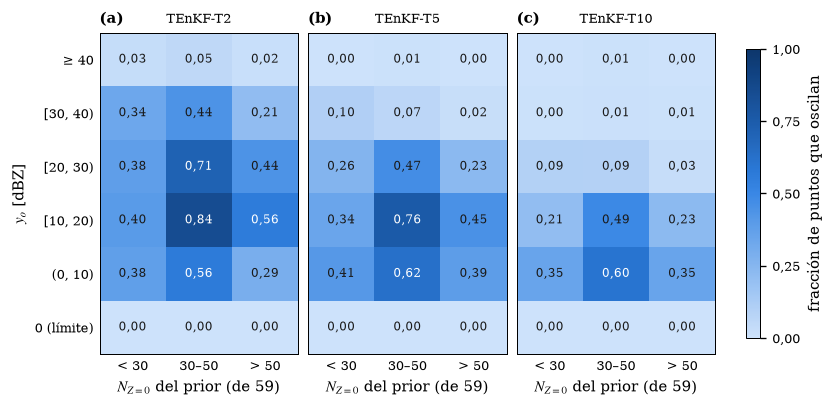

In [75]:
LABELS17 = {
    "es": {"yo": "$y_o$ [dBZ]", "n0": "$N_{Z=0}$ del prior (de 59)", "frac": "fracción de puntos que oscilan",
           "band0": "0 (límite)", "nt": r"pasos de temperado $N_t$", "abs_e": "$|e|$ final medio de $Z$ [dBZ]",
           "sweep": "barrido ({n} experimentos)", "sample_w": "muestra repesada (5–95 %)",
           "sample_u": "muestra sin repesar", "osc": "oscilan", "nonosc": "no oscilan", "t1": "T1, todos los puntos",
           "stratum": "$y_o$ {b} dBZ, $N_{{Z=0}}$ {n}", "ss": r"$\mathrm{SS}_{\mathrm{RMSE}}$ de $Z$"},
    "en": {"yo": "$y_o$ [dBZ]", "n0": "prior $N_{Z=0}$ (of 59)", "frac": "fraction of points that oscillate",
           "band0": "0 (limit)", "nt": r"tempering steps $N_t$", "abs_e": "mean final $|e|$ of $Z$ [dBZ]",
           "sweep": "sweep ({n} experiments)", "sample_w": "reweighted sample (5–95 %)",
           "sample_u": "unweighted sample", "osc": "oscillating", "nonosc": "not oscillating", "t1": "T1, all points",
           "stratum": "$y_o$ {b} dBZ, $N_{{Z=0}}$ {n}", "ss": r"$\mathrm{SS}_{\mathrm{RMSE}}$ of $Z$"},
}
assert set(LABELS17["es"]) == set(LABELS17["en"])
F1_NT = (2, 5, 10)
FRACM = {n: ZR10.groupby(S_KEYS, observed=True)[f"rev_T{n}"].agg(lambda v: (v > 0).mean()).unstack()
         .reindex(index=YO_BANDS, columns=N0_CLASSES) for n in F1_NT}


def draw_zigzag_fraction(lang):
    L = LABELS17[lang]
    fig, axes = plt.subplots(1, len(F1_NT), figsize=(nb.PAGE_W, nb.PAGE_W * 0.48), sharey=True, constrained_layout=True)
    for q, (ax, n) in enumerate(zip(axes, F1_NT)):
        M = FRACM[n].to_numpy(float)
        im = ax.imshow(M, origin="lower", cmap=nb.CMAP_SEQ, vmin=0, vmax=1, aspect="auto")
        for (r_, c_), x in np.ndenumerate(M):
            ax.text(c_, r_, nb.fmt(x, lang, ".2f"), ha="center", va="center", fontsize=7,
                    color="white" if x > 0.55 else "0.1")
        ax.set_xticks(range(len(N0_CLASSES)), N0_CLASSES)
        ax.set_yticks(range(len(YO_BANDS)), [L["band0"]] + list(YO_BANDS[1:]))
        ax.set_xlabel(L["n0"])
        ax.set_title(f"TEnKF-T{n}", fontsize=8)
        ax.set_title(f"({'abc'[q]})", loc="left", fontweight="bold")
        ax.tick_params(length=0)
        ax.grid(False)
    axes[0].set_ylabel(L["yo"])
    fig.colorbar(im, ax=axes, label=L["frac"], shrink=0.9, ticks=[0, 0.25, 0.5, 0.75, 1])
    return fig


nb.save(draw_zigzag_fraction, "N3s/zigzag_fraction", show=SHOW)
plt.show()

figures/es/N3s/zigzag_staircase.png  figures/en/N3s/zigzag_staircase.png


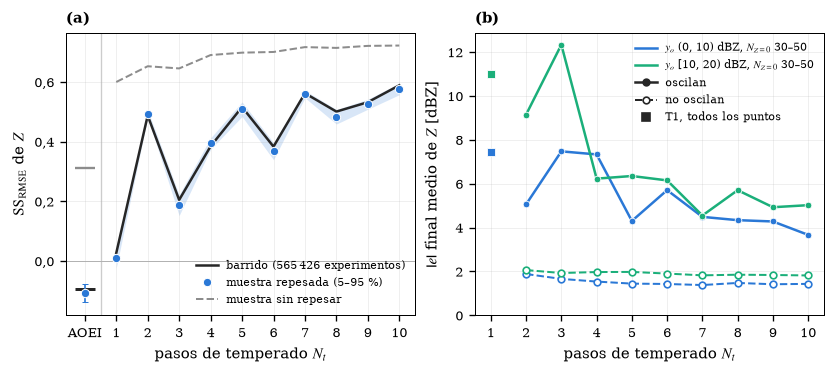

In [76]:
F2_STRATA = (("(0, 10)", "30–50"), ("[10, 20)", "30–50"))
F2_COL = {F2_STRATA[0]: "#2a78d6", F2_STRATA[1]: "#1baf7a"}     # tonos 1 y 3 de la paleta categórica
COL_SAMPLE = nb.METHOD_COLORS["TEnKF"]
INK, INK2 = "0.15", "0.55"


def draw_zigzag_staircase(lang):
    L = LABELS17[lang]
    fig, (a, b) = plt.subplots(1, 2, figsize=(nb.PAGE_W, nb.PAGE_W * 0.44), constrained_layout=True)
    # (a) SS_RMSE de Z contra N_t; AOEI aparte en x = 0
    x = np.array(NT10)
    t = SS_T.loc[[f"T{n}" for n in NT10]]
    a.fill_between(x, t.P5, t.P95, color=COL_SAMPLE, alpha=0.18, lw=0, zorder=1)
    a.plot(x, t["barrido"], "-", color=INK, lw=1.5, zorder=3, label=L["sweep"].format(n=nb.fmt(N_SWEEP, lang, ",d")))
    a.plot(x, t["muestra (pesada)"], "o", ms=5, color=COL_SAMPLE, mec="white", mew=0.6, zorder=4, label=L["sample_w"])
    a.plot(x, t["muestra (sin pesar)"], "--", color=INK2, lw=1.2, zorder=2, label=L["sample_u"])
    ao = SS_T.loc["AOEI"]
    a.plot([0], [ao["barrido"]], "_", color=INK, ms=12, mew=1.8, zorder=3)
    a.errorbar([0], [ao["muestra (pesada)"]], yerr=[[ao["muestra (pesada)"] - ao.P5], [ao.P95 - ao["muestra (pesada)"]]],
               fmt="o", ms=5, color=COL_SAMPLE, mec="white", mew=0.6, capsize=2, elinewidth=1.0, zorder=4)
    a.plot([0], [ao["muestra (sin pesar)"]], "_", color=INK2, ms=12, mew=1.4, zorder=2)
    a.axvline(0.5, color="0.8", lw=0.8, zorder=0)
    a.axhline(0, color="0.7", lw=0.6, zorder=0)
    a.set_xticks([0] + list(NT10), ["AOEI"] + [str(n) for n in NT10])
    a.set(xlabel=L["nt"], ylabel=L["ss"], xlim=(-0.6, 10.5))
    a.legend(fontsize=6.5, frameon=False, loc="lower right")
    # (b) |e| final medio contra N_t, oscilan / no oscilan, dos estratos
    for s in F2_STRATA:
        col = F2_COL[s]
        sub = AE[(AE.banda == s[0]) & (AE.N0 == s[1])].set_index(["grupo", "esquema"])["media"]
        nts = list(range(2, 11))
        b.plot(nts, [sub[("oscila", f"T{n}")] for n in nts], "-o", color=col, ms=4, lw=1.5, mec="white", mew=0.5)
        b.plot(nts, [sub[("no oscila", f"T{n}")] for n in nts], "--o", color=col, ms=4, lw=1.2, mfc="white", mew=1.0)
        b.plot([1], [sub[("todos", "T1")]], "s", color=col, ms=5, mec="white", mew=0.5)
    b.set_xticks(range(1, 11))
    b.set(xlabel=L["nt"], ylabel=L["abs_e"], ylim=(0, None))
    h = [Line2D([], [], color=F2_COL[s], lw=1.5, label=L["stratum"].format(b=s[0], n=s[1])) for s in F2_STRATA]
    h += [Line2D([], [], color=INK, ls="-", marker="o", ms=4, lw=1.5, label=L["osc"]),
          Line2D([], [], color=INK, ls="--", marker="o", ms=4, mfc="white", lw=1.2, label=L["nonosc"]),
          Line2D([], [], color=INK, ls="", marker="s", ms=5, label=L["t1"])]
    b.legend(handles=h, fontsize=6.5, frameon=False, loc="upper right")
    for q, ax in enumerate((a, b)):
        ax.set_title(f"({'ab'[q]})", loc="left", fontweight="bold")
    return fig


nb.save(draw_zigzag_staircase, "N3s/zigzag_staircase", show=SHOW)
plt.show()

## 18 · Tablas para el capítulo y puntos de ejemplo

Solo tablas, de lo ya guardado:

1. De la corrida de la sección 16, $|e|$ final de la media de $Z$ en los puntos que oscilan, según la dirección del último movimiento de la media (sube, baja, o menos de 1 dBZ), por $N_t$ = 2 a 10 y todos los $N_t$ juntos.
2. La tabla LaTeX (booktabs) de los 40 puntos de núcleo, borde, viento débil y aire claro, con las columnas de la tabla de los puntos de corriente vertical del apéndice: celda, altura, miembro verdad, $w_t$, $Z_t$ y $N_{Z>0}$ del prior.
3. Un punto de ejemplo para la ascendente, la descendente, el viento débil y el aire claro: el más típico de su condición según la tabla 1 de la sección 7, es decir, el más cercano a las medias de la condición en $N_{Z>0}$ del prior y después del paso 1 y en el error de $Z$ (prior, paso 1 y final) de TEnKF-T5, cada uno dividido por su desviación estándar en la condición.

In [80]:
# 1 · Puntos que oscilan: |e| final según el último movimiento de la media
LAST_NAME = {1.0: "sube", -1.0: "baja", 0.0: "< 1 dBZ"}
rows = []
for n in range(2, 11):
    o = ZR10[ZR10[f"rev_T{n}"] > 0]
    for v, name in LAST_NAME.items():
        g = o[o[f"last_T{n}"] == v]
        rows.append({"N_t": n, "último paso": name, "puntos": len(g), "media": g[f"abs_e_T{n}"].mean(),
                     "mediana": g[f"abs_e_T{n}"].median(),
                     "media pesada": np.average(g[f"abs_e_T{n}"], weights=g.peso) if len(g) else np.nan})
LM = pd.DataFrame(rows)
long_ = pd.concat([ZR10[ZR10[f"rev_T{n}"] > 0][[f"abs_e_T{n}", f"last_T{n}", "peso"]]
                   .set_axis(["abs_e", "last", "peso"], axis=1) for n in range(2, 11)])
pooled = long_.groupby("last").agg(puntos=("abs_e", "size"), media=("abs_e", "mean"), mediana=("abs_e", "median"))
pooled["media pesada"] = pd.Series({k: np.average(g.abs_e, weights=g.peso) for k, g in long_.groupby("last")})
pooled.index = pooled.index.map(LAST_NAME)
t = LM.pivot(index="N_t", columns="último paso", values=["puntos", "media", "mediana", "media pesada"])
t = t.reindex(columns=pd.MultiIndex.from_product([["puntos", "media", "mediana", "media pesada"], list(LAST_NAME.values())]))
t = t.astype({col: "Int64" for col in t.columns if col[0] == "puntos"})
print("Puntos que oscilan con T_Nt (algún cambio de dirección > 1 dBZ): |e| final de la media de Z [dBZ] según el último "
      "movimiento; «media pesada»: con los estratos pesados por su tamaño en el marco")
print(t.to_string(float_format=lambda v: f"{v:.2f}"))
print("\ntodos los N_t juntos (cada punto una vez por cada N_t con el que oscila)")
print(pooled.reindex(list(LAST_NAME.values())).to_string(float_format=lambda v: f"{v:.2f}"))

Puntos que oscilan con T_Nt (algún cambio de dirección > 1 dBZ): |e| final de la media de Z [dBZ] según el último movimiento; «media pesada»: con los estratos pesados por su tamaño en el marco
    puntos               media              mediana              media pesada             
      sube  baja < 1 dBZ  sube baja < 1 dBZ    sube baja < 1 dBZ         sube baja < 1 dBZ
N_t                                                                                       
2      661  4991       0  9.12 6.15     NaN    8.42 3.52     NaN         9.36 2.71     NaN
3     2882  1182     595 10.85 2.22    1.84   10.71 1.25    1.51        14.65 1.07    1.95
4     1287  2253     518  7.50 5.75    1.87    6.69 3.72    1.52         9.29 2.23    1.97
5     1117  2212     792  9.62 3.62    1.84    8.31 2.10    1.49         7.93 1.53    1.69
6     1742  1161     910  7.74 3.39    1.91    6.36 1.56    1.56        10.18 1.27    1.66
7      979  1653     731  7.37 3.37    1.95    6.12 2.00    1.53         6.20 1

In [81]:
# 2 · Tabla LaTeX de los 40 puntos de núcleo, borde, viento débil y aire claro
TEX_CONDS = ("core", "edge", "weak", "clear")


def tex_num(x, nd):
    """Número con coma decimal para LaTeX ({,} evita el espacio después de la coma)."""
    return f"{round(float(x), nd) + 0.0:.{nd}f}".replace(".", "{,}").replace("-", "$-$")     # + 0.0: sin «−0,00»


def tex_z(z):
    return f"{z:g}".replace(".", "{,}")


lines = [r"\begin{table}[htbp]", r"\centering",
         r"\caption{Puntos de núcleo de tormenta, borde de tormenta, viento vertical débil y aire claro "
         r"(4~km--5~min, 20~UTC).}",
         r"\label{tab:puntos_paso_a_paso}", r"\begin{tabular}{lrrrrr}", r"\toprule",
         r"Celda $(i, j, k)$ & Altura [km] & Miembro verdad & $w_t$ [m/s] & $Z_t$ [dBZ] & $N_{Z>0}$ del prior \\"]
for c in TEX_CONDS:
    lines += [r"\midrule", rf"\multicolumn{{6}}{{l}}{{\textit{{{LABELS['es'][f'cond_{c}'].capitalize()}}}}} \\"]
    for r in SEL[SEL.condition == c].itertuples(index=False):
        lines.append(f"({r.i}, {r.j}, {r.k}) & {tex_z(float(POS[r.i, r.j, r.k, 2]))} & {r.m} & {tex_num(r.w_t, 2)} & "
                     f"{tex_num(r.Z_t, 2)} & {r.n_echo} \\\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
TEX_TABLE = "\n".join(lines)
print(TEX_TABLE)

\begin{table}[htbp]
\centering
\caption{Puntos de núcleo de tormenta, borde de tormenta, viento vertical débil y aire claro (4~km--5~min, 20~UTC).}
\label{tab:puntos_paso_a_paso}
\begin{tabular}{lrrrrr}
\toprule
Celda $(i, j, k)$ & Altura [km] & Miembro verdad & $w_t$ [m/s] & $Z_t$ [dBZ] & $N_{Z>0}$ del prior \\
\midrule
\multicolumn{6}{l}{\textit{Núcleo de tormenta}} \\
(180, 150, 2) & 1 & 10 & $-$0{,}64 & 47{,}72 & 25 \\
(210, 180, 6) & 5 & 48 & 0{,}17 & 51{,}33 & 59 \\
(150, 350, 3) & 2 & 8 & $-$3{,}02 & 48{,}11 & 13 \\
(150, 370, 7) & 6 & 40 & 1{,}94 & 53{,}82 & 9 \\
(140, 380, 8) & 8 & 6 & $-$1{,}26 & 50{,}48 & 5 \\
(170, 420, 6) & 5 & 25 & $-$0{,}19 & 56{,}95 & 7 \\
(120, 370, 8) & 8 & 47 & 2{,}39 & 45{,}75 & 7 \\
(160, 310, 7) & 6 & 23 & $-$0{,}74 & 54{,}48 & 13 \\
(160, 420, 0) & 0{,}25 & 25 & 0{,}20 & 40{,}85 & 1 \\
(230, 40, 3) & 2 & 39 & $-$1{,}49 & 48{,}53 & 12 \\
\midrule
\multicolumn{6}{l}{\textit{Borde de tormenta}} \\
(190, 160, 4) & 3 & 1 & $-$0{,}28 & 11{,}84 & 28 \\


In [79]:
# 3 · El punto más típico de cada condición según la tabla 1 de la sección 7 (TEnKF-T5)
EX_CONDS = ("updraft", "downdraft", "weak", "clear")
T7_COLS = ["n_prior", "n_step1", "e_prior", "e_step1", "e_final"]
rows = []
for r in SEL[SEL.condition.isin(EX_CONDS)].itertuples(index=False):
    P_ = STEPS[point_name(r)]
    H = z_steps(P_, "TEnKF", 5)[0]
    e = H.mean(1) - float(P_["yo_clean"])
    se = np.where(np.abs(e) > SIGN_TOL, np.sign(e), 0.0)
    rows.append(dict(condition=r.condition, point=point_name(r), n_prior=int((H[0] > DBZ_MIN).sum()),
                     n_step1=int((H[1] > DBZ_MIN).sum()), e_prior=e[0], e_step1=e[1], e_final=e[-1],
                     cambios_signo=int((se[:-1] * se[1:] < 0).sum()), cambios_dirección=reversals(H.mean(1), REV_TOLS[1])))
TYP = pd.DataFrame(rows)
picks = {}
for c in EX_CONDS:
    g = TYP[TYP.condition == c]
    zs = (g[T7_COLS] - g[T7_COLS].mean()) / g[T7_COLS].std(ddof=1).replace(0, np.nan)
    TYP.loc[g.index, "distancia"] = np.sqrt((zs.fillna(0) ** 2).sum(axis=1))
    picks[c] = TYP.loc[g.index, "distancia"].idxmin()
for c in EX_CONDS:
    g = TYP[TYP.condition == c]
    print(f"\n{LABELS['es'][f'cond_{c}']}: medias de la condición " +
          ", ".join(f"{k} {g[k].mean():+.2f}" for k in T7_COLS))
    print(g.sort_values("distancia").drop(columns="condition").to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\npuntos de ejemplo propuestos (el de menor distancia) y su figura A1:")
for c in EX_CONDS:
    p = TYP.at[picks[c], "point"]
    print(f"  {c:9s} {p:28s} figures/<idioma>/N3s/points/{c}/{p}_A1.png")


corriente ascendente fuerte: medias de la condición n_prior +10.60, n_step1 +53.20, e_prior -48.15, e_step1 -33.03, e_final -16.07
                  point  n_prior  n_step1  e_prior  e_step1  e_final  cambios_signo  cambios_dirección  distancia
updraft_122_407_10_tm51        9       59   -47.13   -35.39   -13.25              0                  0       0.61
 updraft_131_368_9_tm52        9       59   -49.64   -33.40   -13.37              0                  0       0.63
 updraft_137_365_8_tm38       12       59   -50.17   -28.17   -10.56              0                  0       0.94
 updraft_166_361_7_tm47       10       59   -52.38   -33.88   -15.22              0                  0       1.21
 updraft_164_309_8_tm14       13       59   -48.02   -23.27    -8.98              0                  0       1.24
updraft_231_291_10_tm55       13       59   -45.77   -42.44   -18.42              0                  0       1.28
updraft_155_346_10_tm25       16       59   -45.77   -31.14   -10.78  